# CA6001 · 预算受限的 CPT 补勘：剖面重建、低阻力层厚度与低值识别

**最终课程报告初稿（Notebook 版，v0.9.1 的 13 个入口 + 最终独立测试）** · NTU MSc CA6001 小组项目 · 2026-10

**状态**：v0.9.1 的最终独立测试已经完成（2026-10-14 揭盲，只运行一次）。本 Notebook 是最终报告的**初稿**，正文措辞以后还会修改；图、表和正文中的数字全部由项目保存的结果文件重新计算，并在代码中用断言核对。尚未完成：报告定稿、幻灯片（≤ 12 页）、录屏（≤ 15 分钟）和代码打包，截止 2026-10-28 23:59。正文为中文，图中文字和图注为英文。

| 节 | 内容 | 图表 |
|---|---|---|
| 1 | 问题与两层证据 | 图 1 |
| 2 | 数据与场地：验证场地、最终测试场地、分折与权重规则 | 图 2–4 |
| 3 | 方法：13 个模型入口与主方案机制 | 图 5–6 |
| 4 | **验证结果**（用于选择的证据） | 图 7–9、表 1 |
| 5 | **最终测试结果**（独立证据） | 图 10–17、表 2 |
| 6 | 取舍与讨论 | 图 18–21 |
| 7 | 局限与项目历程 | 图 22 |

**两层证据（全篇适用，每个数字都标明属于哪一层）**
- **验证（VALIDATION）**：4 个场地（Lower Hutt、Tauranga、Chch Metro Sports、Marshland）上的 60 个固定状态，只对应 39 个不同的已知 CPT 集合和 8 组评价集合。13 个入口就是在这些场地上选出和调参的，风险校准也用到它们的标签，所以验证分数**带有选择偏差**。来源：`results/current/`。
- **最终测试（FINAL TEST）**：4 个从未用于选择的场地（Chch Stadium、Wellington Airport、New Lock、Hollywood），100 个状态。每个场地使用它在分折中担任测试组的那一折的权重；泄漏审计 4/4 通过；预测在看不到真值的情况下完成，协议与预测用 SHA-256 冻结后只揭盲一次，之后没有任何改动。来源：`docs/FINAL_TEST_PROTOCOL.md`、`results/final_test/`。
- 只有 4 个测试场地，测试结果是**描述性的**（场地级符号检验在 n = 4 时最小 p = 0.125）。两层的场地难度不同，**不比较两层的绝对误差**，只比较相对 IDW 的变化和名次。
- 本研究只比较固定揭示序列下的预测质量，**没有证明能少打 CPT**。

**运行方式**：用项目 `.venv` 内核打开，第一格会自动定位项目根目录。需要以下本地文件：
- `artifacts/evaluation/`：验证与测试状态、分折、13 个入口的验证参考预测（不入 Git）；
- `data_processed_v2/`；`Data/cpt_screened_depth_qc.npz`（图 1、图 9 中的原始测量曲线）；
- `results/current/`（验证）与 `results/final_test/`（最终测试）；
- 图 22 的项目历程读取 Git 标签中的历史结果表；没有 Git 时改用构建时记录的数值。

除原始测量曲线外，每张图都直接由结果文件计算，不重新训练、不重新推理。设 `EXPORT = True` 时，图会另存为 PNG/SVG/PDF 到 `results/figures-notebook/`。

In [1]:
from pathlib import Path
import json, math, warnings, io, subprocess, hashlib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm, to_rgb
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
import matplotlib.transforms as mtrans
warnings.filterwarnings("ignore")

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "configs" / "catalog.json").exists():
            return p
    raise FileNotFoundError("Open this notebook inside the CA6001 project folder.")

ROOT = find_root()
CUR = ROOT / "results" / "current"          # validation evidence (v0.9.1)
FT = ROOT / "results" / "final_test"        # final independent test
UB = FT / "unblind"
EVAL = ROOT / "artifacts" / "evaluation"    # frozen validation + test states, reference predictions (local only)
DATA = ROOT / "data_processed_v2"
EXPORT = False
OUT = ROOT / "results" / "figures-notebook"
print("project root:", ROOT)

project root: E:\Study\Msc_AAI\CA6001-AI ALGORITHMS FUNDAMENTALS & APPLICATION\Project


## 0 · 视觉系统

- **颜色表示模型身份**，色值与组员的状态页相同：基线用中性灰、蓝、绿；TabPFN 组合用橙色系；主方案用深红系；讨论方案用橄榄、卡其、灰粉，并用**空心标记**。
- 每个模型有固定的标记形状，散点图上也直接标注名字。Thickness（实心六边形）与 FPR 护栏版（空心六边形）同形状，以填充区分。
- **紫色渐变只表示低阻力**（qc < 1 MPa）。
- **蓝 / 红只表示相对 IDW 更好 / 更差**（热图与判定标签）。预注册判定的四个类别固定配色：一致改进（深蓝）、仅均值改进（浅蓝）、无改进（灰）、一致变差（红）。
- 证据层用文字标签区分：**VALIDATION** 与 **FINAL TEST**；示意图中最终测试层用深海军蓝。
- 版式按 A4 单栏宽 175 mm，字号 6–9 pt；网格只用发丝线。

In [2]:
INK, INK2, MUTED = "#1d1d1b", "#52514e", "#8a8984"
GRID, AXIS, PAPER, SOFT = "#ebeae5", "#c3c2b7", "#ffffff", "#f5f4f0"
MODELS = ["constant", "idw", "gp", "xgb", "tabpfn_joint", "tabpfn_graph",
          "balanced", "thickness", "recognition", "simplex", "count_shrink", "thickness_guarded", "cnp"]
COL = {"constant": "#b4b2a9", "idw": "#4d4c48", "gp": "#2a78d6", "xgb": "#1baf7a",
       "tabpfn_joint": "#f0a074", "tabpfn_graph": "#d9601f",
       "balanced": "#b0144a", "thickness": "#e0577f", "recognition": "#6b0d2f",
       "simplex": "#8c8a3c", "count_shrink": "#b8a24a", "thickness_guarded": "#c98a9e", "cnp": "#9a958a"}
NAME = {"constant": "Constant median", "idw": "IDW (3NN)", "gp": "GP", "xgb": "XGBoost residual",
        "tabpfn_joint": "TabPFN joint", "tabpfn_graph": "TabPFN + graph low-union",
        "balanced": "Balanced", "thickness": "Thickness (Haar, nearest)", "recognition": "Recognition (recall-60)",
        "simplex": "Simplex", "count_shrink": "Count-shrink", "thickness_guarded": "Thickness (FPR-guarded)", "cnp": "CNP"}
SHORT = {"constant": "Constant", "idw": "IDW", "gp": "GP", "xgb": "XGBoost", "tabpfn_joint": "TabPFN joint",
         "tabpfn_graph": "TabPFN+graph", "balanced": "Balanced", "thickness": "Thickness",
         "recognition": "Recognition", "simplex": "Simplex", "count_shrink": "Count-shrink",
         "thickness_guarded": "Thickness (guarded)", "cnp": "CNP"}
MK = {"constant": "X", "idw": "o", "gp": "s", "xgb": "D", "tabpfn_joint": "^", "tabpfn_graph": "v",
      "balanced": "*", "thickness": "h", "recognition": "p", "simplex": "<", "count_shrink": ">",
      "thickness_guarded": "h", "cnp": "d"}
MSZ = {"*": 2.0, "h": 1.15, "p": 1.2, "D": .8, "X": 1.05}
GROUPS = [("baseline", "Baselines", ["constant", "idw", "gp", "xgb"]),
          ("tabpfn", "TabPFN combinations", ["tabpfn_joint", "tabpfn_graph"]),
          ("selected", "Main schemes", ["balanced", "thickness", "recognition"]),
          ("discussion", "Discussion entries", ["simplex", "count_shrink", "thickness_guarded", "cnp"])]
GROUP_OF = {m: g for g, _, ms in GROUPS for m in ms}
DISC = set(GROUPS[3][2])
MAIN = ("balanced", "thickness", "recognition")
LOWC = "#5a47b8"; LOWL = "#ebe7fa"
LOW = LinearSegmentedColormap.from_list("low", ["#f4f2fb", "#c9c1ef", "#8b7bdc", "#5a47b8", "#2d2178"])
GOOD, BAD = "#2f6f8f", "#b4553a"          # change-vs-IDW only (not model identities)
DIV = LinearSegmentedColormap.from_list("div", [GOOD, "#f6f5f1", BAD])
TIER_T = "#1f3f66"                        # final-test tier in schematics
# pre-registered outcome categories (FINAL_TEST_PROTOCOL 6.3): label, chip fill, chip text, text colour on white
OUTC = {"consistent_improvement": ("Consistent improvement", GOOD, "white", GOOD),
        "mean_improvement_only": ("Mean improvement only", "#c4dbe5", INK, "#4f8aa6"),
        "no_improvement": ("No improvement", "#e6e5df", INK, MUTED),
        "consistent_deterioration": ("Consistent worsening", BAD, "white", BAD)}
SITE = {"lower_hutt_town_hall": ("LH", "Lower Hutt"), "tauranga_farmers_building": ("TF", "Tauranga"),
        "christchurch_metro_sports_facility": ("CM", "Chch Metro Sports"), "marshland": ("MS", "Marshland")}
VAL_SITES = list(SITE)
TEST_SITES = ["christchurch_stadium", "wellington_airport", "newlock", "hollywood"]
TSITE = {"christchurch_stadium": "Chch Stadium", "wellington_airport": "Wellington Airport",
         "newlock": "New Lock", "hollywood": "Hollywood"}
TFOLD = {"christchurch_stadium": 0, "wellington_airport": 0, "newlock": 1, "hollywood": 2}
SNAME = {**{s: v[1] for s, v in SITE.items()}, **TSITE}
RSRC = {"shared_empirical_head": "shared head", "native_gp": "native GP", "platt_on_point": "Platt on point"}
B5 = [5, 7, 9, 11, 13]
MM = 1 / 25.4
W = 175 * MM

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Segoe UI", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 7.8, "xtick.labelsize": 7.2,
    "ytick.labelsize": 7.2, "legend.fontsize": 7.2, "axes.titleweight": "normal",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": .7, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.major.width": .6, "ytick.major.width": .6, "axes.grid": False,
    "grid.color": GRID, "grid.linewidth": .6, "lines.linewidth": 1.6,
    "lines.solid_capstyle": "round", "legend.frameon": False,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "figure.dpi": 110, "svg.fonttype": "none", "pdf.fonttype": 42, "mathtext.default": "regular",
    "hatch.linewidth": .5,
})

def label(ax, letter, x=-0.02, y=1.02):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom", ha="right", color=INK)

def hgrid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=.6); ax.set_axisbelow(True)

def mscatter(ax, x, y, m, s=40, z=4, **kw):
    st = dict(marker=MK[m], s=s * MSZ.get(MK[m], 1), zorder=z, clip_on=kw.pop("clip_on", True))
    if m in DISC:
        st.update(facecolor="white", edgecolor=COL[m], linewidth=1.3)
    else:
        st.update(color=COL[m], edgecolor="#8a8984" if m == "constant" else "white", linewidth=.7)
    st.update(kw)
    return ax.scatter(x, y, **st)

def mhandle(m, ms=6, label=None, line=False):
    fill = "white" if m in DISC else COL[m]
    return Line2D([], [], ls="-" if line else "", color=COL[m], lw=1.6, marker=MK[m],
                  ms=ms * math.sqrt(MSZ.get(MK[m], 1)), mfc=fill, mec=COL[m] if m in DISC else "white",
                  mew=1.1 if m in DISC else .6, label=label or NAME[m])

def scalebar(ax, frac=.25, loc=(.06, .07)):
    ax.apply_aspect()
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    span = (x1 - x0) * frac
    mag = 10 ** math.floor(math.log10(span)); L = min([1, 2, 5, 10], key=lambda k: abs(k * mag - span)) * mag
    x, y = x0 + (x1 - x0) * loc[0], y0 + (y1 - y0) * loc[1]
    ax.plot([x, x + L], [y, y], color=INK, lw=2, solid_capstyle="butt", zorder=6)
    ax.text(x + L / 2, y + (y1 - y0) * .03, f"{L:g} m", ha="center", va="bottom", fontsize=6.6, color=INK2, zorder=6)

def box(ax, x, y, w, h, title=None, body=None, edge=AXIS, fill="#fbfbf9", ls="-", lw=.9, tsize=7.3, bsize=6.4,
        tcol=INK, stripe=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.4", fc=fill, ec=edge, lw=lw, ls=ls))
    if stripe:
        ax.add_patch(FancyBboxPatch((x, y), 1.4, h, boxstyle="round,pad=0,rounding_size=.7", fc=stripe, ec="none"))
    dx = 3.0 if stripe else 2.0
    if title:
        ax.text(x + dx, y + h - 2.0, title, fontsize=tsize, fontweight="bold", color=tcol, va="top")
    if body:
        ax.text(x + dx, y + h - (6.0 if title else 2.0), body, fontsize=bsize, color=INK2, va="top", linespacing=1.38)

def arrow(ax, x0, y0, x1, y1, c=INK2, lw=.9, style="-|>", rad=0):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle=style, color=c, lw=lw, shrinkA=0, shrinkB=0,
                mutation_scale=8, connectionstyle=f"arc3,rad={rad}"))

def tag(ax, x, y, text, xt, yt, ha="left", c=INK, fs=6.6, lc=AXIS, bold=False):
    ax.annotate(text, (x, y), xytext=(xt, yt), textcoords="data", fontsize=fs, ha=ha, va="center", color=c,
                fontweight="bold" if bold else "normal",
                arrowprops=dict(arrowstyle="-", color=lc, lw=.55, shrinkA=1.5, shrinkB=4))

def chip(ax, x, y, w, h, outcome, text=None, fs=6.2):
    lab, fc, tc, _ = OUTC[outcome]
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.0", fc=fc, ec="none", clip_on=False))
    ax.text(x + w / 2, y + h / 2, text or lab, ha="center", va="center", fontsize=fs, color=tc, clip_on=False)

def tierbadge(ax, x, y, tier, transform=None, fs=6.0):
    c = TIER_T if tier == "test" else MUTED
    ax.text(x, y, "FINAL TEST" if tier == "test" else "VALIDATION", transform=transform or ax.transAxes, fontsize=fs,
            fontweight="bold", color="white", va="bottom", ha="left",
            bbox=dict(boxstyle="round,pad=0.25,rounding_size=0.3", fc=c, ec="none"))

def save(fig, name):
    if EXPORT:
        OUT.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "svg", "pdf"):
            fig.savefig(OUT / f"{name}.{ext}", dpi=300, bbox_inches="tight")

## 加载与核对 · 验证层

评价口径（两层相同）：
1. 每条预算轨迹（fold × site × seed，已知 CPT 数 n = 5, 7, 9, 11, 13）先求**预算曲线下面积平均**（AUBC：梯形积分后除以预算跨度）；
2. 再在同一场地内对种子平均；
3. 最后对场地做**等权宏平均**。

指标定义：
- **log-MAE**：所有评价单元上 |ln q̂c − ln qc| 的平均（越低越好），同时包含水平误差和形状误差。
- **厚度 MAE**：每根评价 CPT 的低阻力层厚度 H = 0.25 m × (qc < 1 MPa 的单元数)，取 |Ĥ − H| 的平均。
- **点召回 / 点误报率（FPR）**：以点预测 q̂c < 1 MPa 判定低值单元，分别计算对真值低值单元的召回和对非低值单元的误报。评价集没有低值单元时召回无定义。
- **风险召回 / 风险误报 / Brier**：没有任何入口在预测时直接输出风险标签。风险列由评价程序做单调 Platt 校准得到（只用验证场地标签），阈值为校准概率 P ≥ 0.2（漏判 : 误报代价 = 4 : 1）。Platt 的输入取决于 `risk_source`：
  - `shared_empirical_head`：共享经验风险头的 p_low_1，与入口自身的点路径无关，所以 6 个入口的风险数字完全相同；
  - `native_gp`：GP 的预测分布；
  - `platt_on_point`：入口没有原生风险头，直接校准点预测 −ŷ。
- **点 FPR 护栏**：点 FPR ≤ 同一层 IDW 的点 FPR + 2 个百分点。验证层为 9.28%，测试层为 7.48%。

In [3]:
cat = json.loads((ROOT / "configs" / "catalog.json").read_text(encoding="utf-8"))
assert [r["id"] for r in cat] == MODELS, "catalogue order changed"
CATR = {r["id"]: r for r in cat}
assert all(CATR[m]["group"] == GROUP_OF[m] for m in MODELS)
metrics = pd.read_csv(CUR / "metrics.csv")
ranking = pd.read_csv(CUR / "all_model_ranking.csv").set_index("model_id")
rt = pd.read_csv(CUR / "runtime_summary.csv")
migr = json.loads((CUR / "migration_summary.json").read_text())
prov = json.loads((CUR / "evaluation_provenance.json").read_text())
states = pd.read_parquet(EVAL / "states.parquet")
folds = json.loads((EVAL / "folds.json").read_text())
ref = pd.read_parquet(EVAL / "reference_predictions.parquet")
grid = pd.read_parquet(DATA / "grid.parquet")
sites = pd.read_parquet(DATA / "sites.parquet")
profiles = pd.read_parquet(DATA / "profiles.parquet")

KEYS = ["model_id", "fold_id", "site_id", "seed"]
MET = ["log_mae", "h_point_mae_m", "recall", "false_positive_rate", "risk_recall", "risk_fpr", "risk_brier"]
def aubc(frame, cols=MET):
    rows = []
    for k, d in frame.sort_values("budget_n").groupby(KEYS):
        x = d.budget_n.to_numpy(float)
        rows.append({**dict(zip(KEYS, k)), **{c: np.trapezoid(d[c].to_numpy(float), x) / (x[-1] - x[0]) for c in cols}})
    return pd.DataFrame(rows)

curves = aubc(metrics)
SITE_T = curves.groupby(["model_id", "site_id"])[MET].mean()
MACRO = SITE_T.groupby("model_id").mean().loc[MODELS]
BUD = (metrics.groupby(["model_id", "site_id", "budget_n"])[MET + ["coverage_90"]].mean()
              .groupby(["model_id", "budget_n"]).mean())          # site mean, then macro, per budget

# 1) recomputation equals the stored validation ranking (13 entries x 7 metrics)
assert np.allclose(MACRO[MET].to_numpy(), ranking.loc[MODELS, MET].to_numpy(), atol=1e-12)
RISK_SRC = ranking.loc[MODELS, "risk_source"]
assert all(RISK_SRC[m] == CATR[m]["risk_source"] for m in MODELS)
assert all(ranking.loc[m, "source_model_id"] == CATR[m]["source_model_id"] for m in MODELS)
SHARED_IDS = [m for m in MODELS if RISK_SRC[m] == "shared_empirical_head"]
assert SHARED_IDS == ["tabpfn_joint", "balanced", "thickness", "recognition", "count_shrink", "thickness_guarded"]
# 2) validation headline numbers (E, H m, recall %, FPR %, risk recall %, risk FPR %, Brier)
DOC = {"constant": (0.889189, 0.966146, 0.00, 0.00, 25.00, 25.00, 0.158444),
       "idw": (0.638586, 0.630371, 37.38, 7.28, 69.55, 38.35, 0.130449),
       "gp": (0.650156, 0.667155, 33.43, 7.37, 62.20, 24.87, 0.125157),
       "xgb": (0.634278, 0.648112, 34.26, 6.76, 68.96, 39.30, 0.130882),
       "tabpfn_joint": (0.598844, 0.525228, 37.68, 8.19, 68.21, 23.90, 0.121124),
       "tabpfn_graph": (0.616500, 0.618978, 42.47, 8.60, 74.40, 29.18, 0.121324),
       "balanced": (0.592435, 0.536947, 38.52, 8.31, 68.21, 23.90, 0.121124),
       "thickness": (0.614517, 0.472493, 39.38, 10.05, 68.21, 23.90, 0.121124),
       "recognition": (0.613079, 0.526855, 48.77, 9.14, 68.21, 23.90, 0.121124),
       "simplex": (0.607248, 0.585286, 34.00, 7.04, 66.65, 25.03, 0.121464),
       "count_shrink": (0.591791, 0.546712, 38.20, 7.98, 68.21, 23.90, 0.121124),
       "thickness_guarded": (0.611418, 0.487630, 38.36, 8.99, 68.21, 23.90, 0.121124),
       "cnp": (0.854427, 0.966146, 0.00, 0.00, 37.55, 38.73, 0.192664)}
for m, (e, h, r, f, rr, rf, br) in DOC.items():
    got = MACRO.loc[m]
    assert abs(got.log_mae - e) < 6e-7 and abs(got.h_point_mae_m - h) < 6e-7 and abs(got.risk_brier - br) < 6e-7, m
    assert all(abs(100 * got[c] - v) < .006 for c, v in zip(["recall", "false_positive_rate", "risk_recall", "risk_fpr"], [r, f, rr, rf])), m
SHARED = MACRO.loc["balanced", ["risk_recall", "risk_fpr", "risk_brier"]]
assert all(np.allclose(MACRO.loc[m, ["risk_recall", "risk_fpr", "risk_brier"]], SHARED, atol=1e-15) for m in SHARED_IDS)
GUARD = MACRO.loc["idw", "false_positive_rate"] + .02                     # validation point-FPR guard: IDW + 2 pp
assert MACRO.loc["thickness", "false_positive_rate"] > GUARD >= MACRO.loc["thickness_guarded", "false_positive_rate"]
COV90 = ranking.loc["gp", "coverage_90"]; COVB = BUD.coverage_90.xs("gp", level="model_id")
assert abs(COV90 - .797607) < 1e-6 and ranking.coverage_90.notna().sum() == 1 and COVB.between(.78, .815).all()
assert prov["risk"]["threshold"] == 0.2
# 3) state structure: 60 states, 39 revealed sets, 8 evaluation sets, 39 held-out profiles / 936 cells
n_states = states.groupby(["fold_id", "site_id", "seed", "budget_n"]).ngroups
n_sets = states.observed_set_id.nunique()
EVSETS = states.evaluation_ids.map(lambda v: tuple(sorted(v)))
n_evsets, EVLOC = EVSETS.nunique(), set().union(*map(set, EVSETS))
n_cells = ref.query("model_id == 'idw'").drop_duplicates(["location_id", "depth_index"]).shape[0]
assert (n_states, n_sets, n_evsets, len(EVLOC), n_cells) == (60, 39, 8, 39, 936)
assert set(states.site_id) == set(VAL_SITES)
ev_size = states.groupby("site_id").evaluation_ids.first().map(len)
# 4) live inference equals the stored reference predictions; uniform runtime benchmark
assert migr["passed"] and migr["checks"] == 780 and migr["label_changes"] == 0
RTF = rt[rt.path == "full"].set_index("model_id").loc[MODELS]
RTP = rt[rt.path == "point_only"].set_index("model_id")
assert RTF.matches_reference.all() and set(RTF.device) == {"cpu", "cuda"}
assert sorted(RTP.index) == sorted(m for m in MODELS if CATR[m]["point_only_supported"])
assert not RTP.loc["tabpfn_joint", "matches_reference"] and RTP.drop("tabpfn_joint").matches_reference.all()
TJ_CPU = RTP.loc["tabpfn_joint"]
RATIO = RTF.loc["count_shrink", "total_ms_median"] / RTF.loc["balanced", "total_ms_median"]
print(f"VALIDATION · states {n_states} · distinct revealed sets {n_sets} · distinct evaluation sets {n_evsets} · "
      f"held-out profiles {len(EVLOC)} ({n_cells} cells) · reference rows {len(ref):,}")
print("evaluation CPTs per state:", {SITE[s][1]: int(v) for s, v in ev_size.items()})
print(f"live inference = reference predictions: {migr['checks']} checks passed")
print(f"shared risk head ({len(SHARED_IDS)} entries) recall/FPR/Brier = "
      f"{100*SHARED.risk_recall:.2f}% / {100*SHARED.risk_fpr:.2f}% / {SHARED.risk_brier:.6f}")
print(f"validation point-FPR guard (IDW + 2 pp) = {100*GUARD:.2f}%; GP 90% interval coverage {100*COV90:.2f}% "
      f"(per budget {100*COVB.min():.1f}–{100*COVB.max():.1f}%)")

VALIDATION · states 60 · distinct revealed sets 39 · distinct evaluation sets 8 · held-out profiles 39 (936 cells) · reference rows 112,320
evaluation CPTs per state: {'Chch Metro Sports': 8, 'Lower Hutt': 6, 'Marshland': 4, 'Tauranga': 6}
live inference = reference predictions: 780 checks passed
shared risk head (6 entries) recall/FPR/Brier = 68.21% / 23.90% / 0.121124
validation point-FPR guard (IDW + 2 pp) = 9.28%; GP 90% interval coverage 79.76% (per budget 78.1–81.2%)


## 加载与核对 · 最终测试层

下面的单元格：
1. 重新计算冻结文件的 SHA-256，与 `frozen.json` 和揭盲日志中的记录逐一比对（揭盲后没有任何文件被改动）；
2. 核对测试场地、所用折、风险校准场地与泄漏审计；
3. 由逐状态的 `unblind/metrics.csv` **重新计算** AUBC、场地均值、4 场地等权总表、逐预算表和与 IDW 的配对比较，并与保存的表逐项比对；
4. 按预注册规则重新判定 Q1–Q5，与 `decisions.json` 比对。

In [4]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
frozen = json.loads((FT / "frozen.json").read_text(encoding="utf-8"))
ulog = [json.loads(l) for l in (FT / "unblind_log.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
leak = json.loads((FT / "leakage_audit.json").read_text(encoding="utf-8"))
prep = json.loads((FT / "prepare_summary.json").read_text(encoding="utf-8"))
blind = json.loads((FT / "blind" / "blind_summary.json").read_text(encoding="utf-8"))
det = json.loads((FT / "blind" / "determinism.json").read_text(encoding="utf-8"))
calj = json.loads((FT / "calibrators.json").read_text(encoding="utf-8"))
roles_t = pd.read_csv(FT / "site_roles.csv").set_index("site_id")
dec = json.loads((UB / "decisions.json").read_text(encoding="utf-8"))
ANS = dec["answers"]
tm = pd.read_csv(UB / "metrics.csv")
trank = pd.read_csv(UB / "test_ranking.csv").set_index("model_id")
trank2 = pd.read_csv(UB / "test_ranking_verified_sites.csv").set_index("model_id")
tsite_f = pd.read_csv(UB / "site_metrics.csv").set_index(["model_id", "site_id"])
tbud_f = pd.read_csv(UB / "budget_metrics.csv").set_index(["model_id", "budget_n"])
tcurv_f = pd.read_csv(UB / "curves.csv")
paired = pd.read_csv(UB / "paired_comparisons.csv")
tstates = pd.read_parquet(EVAL / "test_states.parquet")

# 1) integrity: frozen inputs and unblind outputs are byte-identical to what was recorded
started = [e for e in ulog if e["event"] == "unblind_started"]; finished = [e for e in ulog if e["event"] == "unblind_finished"]
assert len(started) == len(finished) == 1 and started[0]["run_index"] == 1 and not started[0]["rerun"] and dec["run_index"] == 1
HASH = {"protocol": (ROOT / "docs" / "FINAL_TEST_PROTOCOL.md", frozen["protocol_sha256"]),
        "test states": (EVAL / "test_states.parquet", frozen["test_states_sha256"]),
        "catalogue": (ROOT / "configs" / "catalog.json", frozen["catalog_sha256"]),
        "risk calibrators": (FT / "calibrators.json", frozen["calibrators_sha256"]),
        "validation ranking": (CUR / "all_model_ranking.csv", frozen["validation_ranking_sha256"]),
        "blind predictions": (FT / "blind" / "predictions.parquet", frozen["blind_predictions_sha256"])}
HASH.update({f"unblind/{k}": (UB / k, v) for k, v in finished[0]["outputs_sha256"].items()})
HCHK = pd.DataFrame([(k, v[1][:12] + "…", sha(v[0]) == v[1]) for k, v in HASH.items()], columns=["file", "recorded sha256", "match"])
assert HCHK.match.all() and len(HCHK) == 15
assert started[0]["protocol_sha256"] == frozen["protocol_sha256"] == dec["protocol_sha256"]
assert started[0]["blind_predictions_sha256"] == frozen["blind_predictions_sha256"]
T_FROZEN, T_START, T_END = frozen["frozen_at"][11:19], started[0]["time"][11:19], finished[0]["time"][11:19]
assert frozen["frozen_at"][:10] == started[0]["time"][:10] == "2026-10-14" and T_FROZEN < T_START < T_END
# 2) sites, folds, calibrators, leakage audit, blind run
assert frozen["models"] == MODELS and frozen["seeds"] == [17, 29, 43, 71, 101] and frozen["budgets"] == B5
assert frozen["test_sites"] == TFOLD and frozen["risk_threshold"] == 0.2
inc = roles_t[roles_t.included]
assert sorted(inc.index) == sorted(TEST_SITES) and all(inc.loc[s, f"fold_{TFOLD[s]}"] == "test" for s in TEST_SITES)
assert not inc.in_frozen_validation_states.any() and roles_t.loc[VAL_SITES, "in_frozen_validation_states"].all()
assert set(TEST_SITES).isdisjoint(states.site_id)
CALS = {}
for key, c in calj["calibrators"].items():
    CALS.setdefault(int(key.split("|")[1]), set()).update(c["training_sites"])
assert CALS == {0: {"lower_hutt_town_hall", "tauranga_farmers_building"}, 1: {"lower_hutt_town_hall", "tauranga_farmers_building"},
                2: {"christchurch_metro_sports_facility", "marshland"}}
assert all(set(TEST_SITES).isdisjoint(v) for v in CALS.values())
assert leak["all_passed"] and len(leak["sites"]) == 4 and all(s["passed"] and not s["leaks"] for s in leak["sites"])
assert blind["all_sanity_passed"] and blind["states"] == 100 and blind["prediction_rows"] == 249600
assert det["predictions_file_sha256_equal"] and det["point_label_differences"] == 0 and det["risk_label_differences"] == 0
assert len(tstates) == 100 and tstates.observed_set_id.nunique() == 100 and prep["distinct_evaluation_sets"] == 19
assert prep["frozen_state_reproduction"] == {"checked": 60, "mismatches": 0}
T_EV = tstates.groupby("site_id").n_evaluation.agg(["min", "max"])
assert (T_EV["min"] == T_EV["max"]).all()
T_EV = T_EV["min"].to_dict()
assert T_EV == {"christchurch_stadium": 5, "wellington_airport": 6, "newlock": 16, "hollywood": 5}

# 3) recompute every test table from the per-state metrics
TMET = MET + ["coverage_90"]
assert len(tm) == 1300 and set(tm.site_id) == set(TEST_SITES)
TCURV = aubc(tm, TMET)
chk = TCURV.merge(tcurv_f, on=KEYS, suffixes=("", "_f"))
assert len(chk) == len(tcurv_f) == 260 and all(np.allclose(chk[c], chk[c + "_f"], equal_nan=True, atol=1e-12) for c in TMET)
TSITE_T = TCURV.groupby(["model_id", "site_id"])[TMET].mean()
assert np.allclose(TSITE_T[TMET].to_numpy(), tsite_f.loc[TSITE_T.index, TMET].to_numpy(), equal_nan=True, atol=1e-12)
TMACRO = TSITE_T.groupby("model_id").mean().loc[MODELS]
assert np.allclose(TMACRO[TMET].to_numpy(), trank.loc[MODELS, TMET].to_numpy(), equal_nan=True, atol=1e-12)
TNSITE = TSITE_T.groupby("model_id").count().loc[MODELS]
assert (TNSITE.recall == 3).all() and (TNSITE.log_mae == 4).all() and (TNSITE.recall == trank.loc[MODELS, "n_sites_recall"]).all()
TBUD = tm.groupby(["model_id", "site_id", "budget_n"])[TMET].mean().groupby(["model_id", "budget_n"]).mean()
assert np.allclose(TBUD[TMET].to_numpy(), tbud_f.loc[TBUD.index, TMET].to_numpy(), equal_nan=True, atol=1e-12)
V2 = ["christchurch_stadium", "wellington_airport"]                      # sensitivity: grouping-verified test sites
TMACRO2 = TSITE_T[TSITE_T.index.get_level_values("site_id").isin(V2)].groupby("model_id").mean().loc[MODELS]
assert np.allclose(TMACRO2[TMET].to_numpy(), trank2.loc[MODELS, TMET].to_numpy(), equal_nan=True, atol=1e-12)
# undefined recall: Wellington Airport evaluation sets contain no low cell
AIR = tm[tm.site_id == "wellington_airport"]
assert (AIR.n_true_positive == 0).all() and AIR.recall.isna().all() and (AIR.h_point_mae_m == 0).all() and (AIR.false_positive_rate == 0).all()
assert TSITE_T.xs("wellington_airport", level="site_id").recall.isna().all()
LOWSHARE = (tm[tm.model_id == "idw"].assign(r=lambda d: d.n_true_positive / d.n_eval_cells).groupby("site_id").r.mean())

# 4) paired comparisons and pre-registered outcomes (FINAL_TEST_PROTOCOL 6.3)
LOWER = {"log_mae": True, "h_point_mae_m": True, "recall": False, "false_positive_rate": True,
         "risk_recall": False, "risk_fpr": True, "risk_brier": True}
def compare(m, ref_m, col, ST=TSITE_T, site_list=TEST_SITES):
    d = (ST.loc[m, col] - ST.loc[ref_m, col]).reindex(site_list).dropna()
    good = -d if LOWER[col] else d
    w, l = int((good > 1e-12).sum()), int((good < -1e-12).sum())
    n, delta = len(d), d.mean()
    k = math.ceil(.75 * n); better = (-delta if LOWER[col] else delta) > 0; worse = (-delta if LOWER[col] else delta) < 0
    out = ("consistent_improvement" if better and w >= k else "mean_improvement_only" if better else
           "consistent_deterioration" if worse and l >= k else "no_improvement")
    return dict(delta=delta, n=n, w=w, t=n - w - l, l=l, outcome=out, diffs=d)
PAIR = {(m, r, c): compare(m, r, c) for r in ("idw", "thickness_guarded") for m in MODELS for c in LOWER}
for row in paired.itertuples():
    if row.metric not in LOWER: continue
    p_ = PAIR[(row.model_id, row.reference, row.metric)]
    assert (p_["w"], p_["t"], p_["l"], p_["n"]) == (row.site_wins, row.site_ties, row.site_losses, row.n_sites), row
    assert abs(p_["delta"] - row.mean_site_difference) < 1e-12 or (np.isnan(p_["delta"]) and np.isnan(row.mean_site_difference))
SIGN_P_MIN = paired.site_sign_test_p_two_sided.min()
assert abs(SIGN_P_MIN - .125) < 1e-12

def same(a, p_):
    return a["outcome"] == p_["outcome"] and (a["site_wins"], a["site_ties"], a["site_losses"]) == (p_["w"], p_["t"], p_["l"]) \
        and abs(a["mean_site_difference"] - p_["delta"]) < 1e-12
QA = ANS
assert same(QA["Q1_balanced_vs_idw"]["log_mae"], PAIR[("balanced", "idw", "log_mae")])
assert same(QA["Q1_balanced_vs_idw"]["h_point_mae_m"], PAIR[("balanced", "idw", "h_point_mae_m")])
assert same(QA["Q2_thickness"]["vs_idw_h_point_mae_m"], PAIR[("thickness", "idw", "h_point_mae_m")])
assert same(QA["Q2_thickness"]["vs_thickness_guarded_h_point_mae_m"], PAIR[("thickness", "thickness_guarded", "h_point_mae_m")])
assert same(QA["Q3_recognition"]["recall_vs_idw"], PAIR[("recognition", "idw", "recall")])
assert same(QA["Q3_recognition"]["fpr_vs_idw"], PAIR[("recognition", "idw", "false_positive_rate")])
for m in ("tabpfn_joint", "tabpfn_graph"):
    for c in ("log_mae", "h_point_mae_m"):
        assert same(QA["Q4_tabpfn_vs_idw"][m][c], PAIR[(m, "idw", c)])
TGUARD = TMACRO.loc["idw", "false_positive_rate"] + .02                  # test point-FPR guard: test IDW + 2 pp
assert abs(QA["Q2_thickness"]["fpr_guard_idw_plus_2pp"] - TGUARD) < 1e-12
assert QA["Q2_thickness"]["thickness_within_fpr_guard"] == (TMACRO.loc["thickness", "false_positive_rate"] <= TGUARD)
assert QA["Q3_recognition"]["within_fpr_guard_idw_plus_2pp"] == (TMACRO.loc["recognition", "false_positive_rate"] <= TGUARD)

def q_rule(o1, o2):          # wording rule of Q1 / Q4 (protocol 6.4)
    if o1 == o2 == "consistent_improvement": return "consistently better than IDW"
    if {o1, o2} & {"consistent_improvement", "mean_improvement_only"}: return "only partial improvement over IDW"
    if o1 == o2 == "consistent_deterioration": return "consistently worse than IDW"
    return "no improvement over IDW"
assert "部分改进" in QA["Q1_balanced_vs_idw"]["decision"]
assert q_rule(PAIR[("balanced", "idw", "log_mae")]["outcome"], PAIR[("balanced", "idw", "h_point_mae_m")]["outcome"]) == "only partial improvement over IDW"

# 5) Q5: rank stability between validation and test (13 entries)
RHO, TOP3 = {}, {}
for c in ("log_mae", "h_point_mae_m"):
    RHO[c] = MACRO[c].corr(TMACRO[c], method="spearman")
    v3, t3 = list(MACRO[c].sort_values().index[:3]), list(TMACRO[c].sort_values().index[:3])
    TOP3[c] = (v3, t3, len(set(v3) & set(t3)))
    q5 = QA["Q5_rank_stability"][c]
    assert abs(q5["spearman_rho"] - RHO[c]) < 1e-12 and q5["validation_top3"] == v3 and q5["test_top3"] == t3 and q5["top3_overlap"] == TOP3[c][2]
    assert q5["balanced_test_rank"] == int(TMACRO[c].rank(method="min")["balanced"])
STAB = lambda r: "stable" if r >= .7 else "moderate" if r >= .4 else "unstable"
assert [STAB(RHO[c]) for c in RHO] == [QA["Q5_rank_stability"][c]["stability"] for c in RHO] == ["stable", "moderate"]

print(f"FINAL TEST · frozen {frozen['frozen_at'][:10]} {T_FROZEN} · unblinded once {T_START}–{T_END} (run 1, no rerun)")
print(f"{int(HCHK.match.sum())}/{len(HCHK)} recorded SHA-256 hashes match the files on disk")
print(f"leakage audit {sum(s['passed'] for s in leak['sites'])}/4 · blind rows {blind['prediction_rows']:,} · two blind runs identical: {det['predictions_file_sha256_equal']}")
print("weights used:", {TSITE[s]: f"fold {f}" for s, f in TFOLD.items()}, "· evaluation CPTs per state:", {TSITE[s]: v for s, v in T_EV.items()})
print("risk calibrators fitted on:", {f: sorted(SNAME[s] for s in v) for f, v in CALS.items()})
print(f"recomputed AUBC/site/macro/budget tables equal the unblind files · test point-FPR guard {100*TGUARD:.2f}% · min site sign-test p {SIGN_P_MIN:.3f}")
display(HCHK)

FINAL TEST · frozen 2026-10-14 22:50:34 · unblinded once 22:50:43–22:51:17 (run 1, no rerun)
15/15 recorded SHA-256 hashes match the files on disk
leakage audit 4/4 · blind rows 249,600 · two blind runs identical: True
weights used: {'Chch Stadium': 'fold 0', 'Wellington Airport': 'fold 0', 'New Lock': 'fold 1', 'Hollywood': 'fold 2'} · evaluation CPTs per state: {'Chch Stadium': 5, 'Hollywood': 5, 'New Lock': 16, 'Wellington Airport': 6}
risk calibrators fitted on: {0: ['Lower Hutt', 'Tauranga'], 1: ['Lower Hutt', 'Tauranga'], 2: ['Chch Metro Sports', 'Marshland']}
recomputed AUBC/site/macro/budget tables equal the unblind files · test point-FPR guard 7.48% · min site sign-test p 0.125


,file,recorded sha256,match
0,protocol,6f88d02f46a0…,True
1,test states,951b6cfb6bb8…,True
2,catalogue,d344bdee1c89…,True
3,risk calibrators,48efc2919100…,True
4,validation ranking,80fd4672deb7…,True
5,blind predictions,f87c1f7b3aac…,True
6,unblind/budget_metrics.csv,c2180b8783dc…,True
7,unblind/curves.csv,8d326e43642d…,True
8,unblind/decisions.json,dc8c00e3513b…,True
9,unblind/metrics.csv,bc5a996e18ad…,True


In [5]:
# --- numbers quoted in the Chinese text and the English captions, checked against the result files ---------
pct = lambda M_, m, c: 100 * (M_.loc[m, c] / M_.loc["idw", c] - 1)
TXT = {"VAL Balanced log-MAE vs IDW (%)": (pct(MACRO, "balanced", "log_mae"), -7.23),
       "VAL Balanced thickness vs IDW (%)": (pct(MACRO, "balanced", "h_point_mae_m"), -14.82),
       "VAL Thickness thickness vs IDW (%)": (pct(MACRO, "thickness", "h_point_mae_m"), -25.05),
       "VAL Thickness (guarded) thickness vs IDW (%)": (pct(MACRO, "thickness_guarded", "h_point_mae_m"), -22.64),
       "VAL TabPFN joint log-MAE vs IDW (%)": (pct(MACRO, "tabpfn_joint", "log_mae"), -6.22),
       "VAL Count-shrink - Balanced log-MAE": (MACRO.loc["count_shrink", "log_mae"] - MACRO.loc["balanced", "log_mae"], -0.000644),
       "VAL point-FPR guard (%)": (100 * GUARD, 9.28),
       "TEST count_shrink log-MAE": (TMACRO.loc["count_shrink", "log_mae"], 0.5049),
       "TEST balanced log-MAE": (TMACRO.loc["balanced", "log_mae"], 0.5052),
       "TEST tabpfn_joint log-MAE": (TMACRO.loc["tabpfn_joint", "log_mae"], 0.5061),
       "TEST IDW log-MAE": (TMACRO.loc["idw", "log_mae"], 0.5315),
       "TEST Balanced log-MAE vs IDW (%)": (pct(TMACRO, "balanced", "log_mae"), -4.9),
       "TEST thickness MAE (m)": (TMACRO.loc["thickness", "h_point_mae_m"], 0.4383),
       "TEST thickness - IDW (m)": (PAIR[("thickness", "idw", "h_point_mae_m")]["delta"], -0.065),
       "TEST Thickness thickness vs IDW (%)": (pct(TMACRO, "thickness", "h_point_mae_m"), -13.0),
       "TEST IDW thickness MAE (m)": (TMACRO.loc["idw", "h_point_mae_m"], 0.504),
       "TEST constant thickness MAE (m)": (TMACRO.loc["constant", "h_point_mae_m"], 0.471),
       "TEST thickness point FPR (%)": (100 * TMACRO.loc["thickness", "false_positive_rate"], 4.81),
       "TEST point-FPR guard (%)": (100 * TGUARD, 7.48),
       "TEST recognition recall (%)": (100 * TMACRO.loc["recognition", "recall"], 28.4),
       "TEST recognition recall - IDW (pp)": (100 * PAIR[("recognition", "idw", "recall")]["delta"], 5.07),
       "TEST recognition FPR - IDW (pp)": (100 * PAIR[("recognition", "idw", "false_positive_rate")]["delta"], 0.85),
       "TEST shared-head risk FPR at New Lock (%)": (100 * TSITE_T.loc[("balanced", "newlock"), "risk_fpr"], 62.7),
       "TEST shared-head risk recall (%)": (100 * TMACRO.loc["balanced", "risk_recall"], 46.7),
       "TEST IDW+Platt risk recall (%)": (100 * TMACRO.loc["idw", "risk_recall"], 57.0),
       "TEST GP 90% coverage (%)": (100 * TMACRO.loc["gp", "coverage_90"], 86.5),
       "Q5 rho log-MAE": (RHO["log_mae"], 0.912), "Q5 rho thickness": (RHO["h_point_mae_m"], 0.510),
       "Count-shrink / Balanced runtime (x)": (RATIO, 1.89),
       "Balanced runtime (ms)": (RTF.loc["balanced", "total_ms_median"], 183.2),
       "Count-shrink runtime (ms)": (RTF.loc["count_shrink", "total_ms_median"], 345.8),
       "IDW runtime (ms)": (RTF.loc["idw", "total_ms_median"], 6.8),
       "TabPFN joint point-only CPU (ms)": (TJ_CPU.total_ms_median, 1857.2),
       "TabPFN joint point-only max point diff": (TJ_CPU.max_point_difference, 0.33)}
for k, (got, want) in TXT.items():
    tol = 10 ** -(len(str(want).split(".")[-1])) * .51
    assert abs(got - want) <= tol, (k, got, want)
assert (PAIR[("thickness", "idw", "h_point_mae_m")]["w"], PAIR[("thickness", "idw", "h_point_mae_m")]["t"], PAIR[("thickness", "idw", "h_point_mae_m")]["l"]) == (3, 1, 0)
assert TMACRO.log_mae.sort_values().index[:3].tolist() == ["count_shrink", "balanced", "tabpfn_joint"]
assert TMACRO.h_point_mae_m.idxmin() == "thickness" and TMACRO.recall.idxmax() == "recognition"
NL = TSITE_T.xs("newlock", level="site_id").log_mae
assert set(NL.sort_values().index[:2]) == {"constant", "cnp"}                 # New Lock: constant/CNP beat every spatial model
assert TSITE_T.xs("newlock", level="site_id").h_point_mae_m.between(1.3, 1.7).all()
print("all quoted numbers agree with results/current and results/final_test:")
display(pd.DataFrame({k: dict(computed=v[0], quoted=v[1]) for k, v in TXT.items()}).T.round(6))

all quoted numbers agree with results/current and results/final_test:


,computed,quoted
VAL Balanced log-MAE vs IDW (%),-7.227075,-7.230000
VAL Balanced thickness vs IDW (%),-14.820553,-14.820000
VAL Thickness thickness vs IDW (%),-25.045185,-25.050000
VAL Thickness (guarded) thickness vs IDW (%),-22.643945,-22.640000
VAL TabPFN joint log-MAE vs IDW (%),-6.223415,-6.220000
VAL Count-shrink - Balanced log-MAE,-0.000644,-0.000644
VAL point-FPR guard (%),9.276634,9.280000
TEST count_shrink log-MAE,0.504857,0.504900
TEST balanced log-MAE,0.505248,0.505200
TEST tabpfn_joint log-MAE,0.506097,0.506100


## 1 · 问题与两层证据

一块场地上已经打了少量 CPT（n = 5…13 根），需要在**还没打的位置**回答三件事：
1. 重建 2–8 m 的 qc 剖面（24 个 0.25 m 单元）；
2. 估计 qc < 1 MPa 的**低阻力层厚度**；
3. 标出哪些单元是低值。

这三件事的最优模型并不相同，所以后面分出"均衡 / 厚度 / 识别"三个主方案。

### 图 1 · 一根 CPT 上的预测目标，以及两层证据各能说明什么

左图是验证场地 Chch Metro Sports 的一根真实 CPT。选取规则是"测得厚度等于该场地非零厚度的中位数"，不看任何模型结果。右图列出两层证据和至今仍无法说明的问题。

example CPT: location_021e40993a0ab7d4 · measured thickness 1.00 m · site median of non-zero thickness 1.00 m


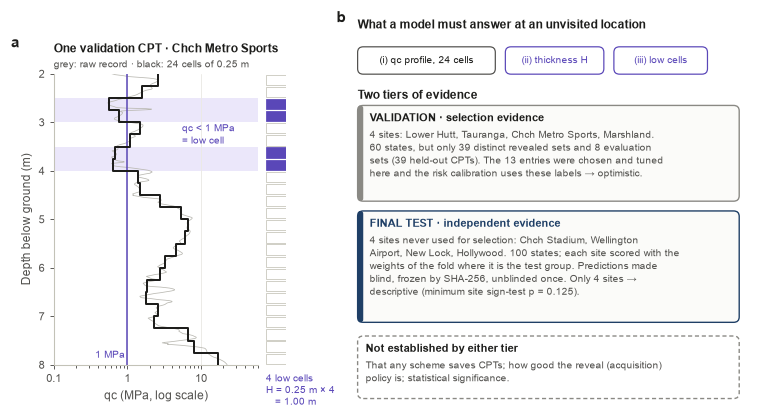

In [6]:
LOC = grid.drop_duplicates("location_id")[["site_id", "location_id", "near_group_id", "x_m", "y_m"]].copy()
LOC = LOC.join((grid.groupby("location_id").low_1.sum() * .25).rename("h_true"), on="location_id")
npz = np.load(ROOT / "Data" / "cpt_screened_depth_qc.npz", allow_pickle=True)
def raw_profile(location_id):
    key = profiles.query("location_id == @location_id and is_representative").array_key.iloc[0]
    a = np.asarray(npz[str(key)], float); a = a[(a[:, 0] > 1.95) & (a[:, 0] < 8.05) & (a[:, 1] > 0)]
    return a[:, 0], a[:, 1]
EDGES = np.arange(2.0, 8.0001, .25)
def stair(values):
    return np.repeat(values, 2), np.column_stack([EDGES[:-1], EDGES[1:]]).ravel()

S1 = "christchurch_metro_sports_facility"
nz = LOC.query("site_id == @S1 and h_true > 0").sort_values("location_id")
ex = nz.iloc[np.argsort((nz.h_true - nz.h_true.median()).abs().to_numpy(), kind="stable")[0]]
g1 = grid.query("location_id == @ex.location_id").sort_values("depth_index")
rz, rq = raw_profile(ex.location_id)

fig = plt.figure(figsize=(W, 96 * MM))
a = fig.add_axes([.075, .12, .27, .7]); bc = fig.add_axes([.355, .12, .026, .7], sharey=a)
low = g1.low_1.to_numpy()
for z0, l in zip(EDGES[:-1], low):
    if l: a.axhspan(z0, z0 + .25, color=LOWL, lw=0, zorder=0)
a.plot(rq, rz, color="#b9b8b1", lw=.5, zorder=1)
xs, ys = stair(g1.qc_mpa.to_numpy()); a.plot(xs, ys, color=INK, lw=1.3, zorder=3)
a.axvline(1, color=LOWC, lw=1, zorder=2)
a.text(.93, 7.9, "1 MPa", color=LOWC, fontsize=6.8, va="bottom", ha="right")
a.text(5.5, 3.25, "qc < 1 MPa\n= low cell", color=LOWC, fontsize=6.6, va="center", linespacing=1.2)
a.set_xscale("log"); a.set_xlim(.1, 60); a.set_ylim(8, 2)
a.set_xticks([.1, 1, 10], ["0.1", "1", "10"]); hgrid(a, "x")
a.set_xlabel("qc (MPa, log scale)"); a.set_ylabel("Depth below ground (m)")
a.set_title(f"One validation CPT · {SITE[S1][1]}", loc="left", fontsize=7.8, fontweight="bold", pad=14)
a.text(0, 1.015, "grey: raw record · black: 24 cells of 0.25 m", transform=a.transAxes, fontsize=6.4, color=INK2, va="bottom")
label(a, "a", x=-.17, y=1.08)
for z0, l in zip(EDGES[:-1], low):
    bc.add_patch(Rectangle((0, z0 + .02), 1, .21, fc=LOWC if l else "white", ec=LOWC if l else AXIS, lw=.5))
bc.set_xlim(0, 1); bc.axis("off")
k = int(low.sum())
bc.text(.0, 8.15, f"{k} low cells\nH = 0.25 m × {k}\n   = {0.25*k:.2f} m", ha="left", va="top", fontsize=6.5, color=LOWC, linespacing=1.25)

b = fig.add_axes([.46, .02, .53, .94]); b.set_xlim(0, 100); b.set_ylim(0, 100); b.axis("off")
label(b, "b", x=.0, y=.975)
b.text(3, 99, "What a model must answer at an unvisited location", fontsize=7.6, fontweight="bold", va="top")
chips = ["(i) qc profile, 24 cells", "(ii) thickness H", "(iii) low cells"]
cx = 3
for t in chips:
    wdt = 1.22 * len(t) + 5
    box(b, cx, 85, wdt, 7, None, None, edge=LOWC if t != chips[0] else INK2, fill="white", lw=.8)
    b.text(cx + wdt / 2, 88.5, t, ha="center", va="center", fontsize=6.6, color=LOWC if t != chips[0] else INK)
    cx += wdt + 2.5
b.text(3, 81, "Two tiers of evidence", fontsize=7.6, fontweight="bold", va="top")
lad = [(52.5, 24.5, MUTED, "-", "VALIDATION · selection evidence",
        f"4 sites: Lower Hutt, Tauranga, Chch Metro Sports, Marshland.\n"
        f"{n_states} states, but only {n_sets} distinct revealed sets and {n_evsets} evaluation\n"
        f"sets ({len(EVLOC)} held-out CPTs). The 13 entries were chosen and tuned\n"
        "here and the risk calibration uses these labels → optimistic."),
       (21.5, 28.5, TIER_T, "-", "FINAL TEST · independent evidence",
        "4 sites never used for selection: Chch Stadium, Wellington\n"
        f"Airport, New Lock, Hollywood. {len(tstates)} states; each site scored with the\n"
        "weights of the fold where it is the test group. Predictions made\n"
        "blind, frozen by SHA-256, unblinded once. Only 4 sites →\n"
        f"descriptive (minimum site sign-test p = {SIGN_P_MIN:.3f})."),
       (2, 16, MUTED, (0, (3, 2)), "Not established by either tier",
        "That any scheme saves CPTs; how good the reveal (acquisition)\npolicy is; statistical significance.")]
for y, h, c, ls, t, body in lad:
    box(b, 3, y, 95, h, t, body, edge=c, ls=ls, stripe=None if ls != "-" else c, tsize=7.2, bsize=6.5,
        fill="#ffffff" if ls != "-" else "#fbfbf9", tcol=c if c == TIER_T else INK)
save(fig, "fig01_task_and_evidence"); plt.show()
print(f"example CPT: {ex.location_id} · measured thickness {ex.h_true:.2f} m · site median of non-zero thickness {nz.h_true.median():.2f} m")

**Caption.** *Fig. 1. (a) The prediction target at one validation CPT. The record is averaged into 24 cells of 0.25 m between 2 and 8 m. Cells with qc < 1 MPa (violet) define the low-resistance layer, whose thickness is 0.25 m × the number of low cells. (b) Two tiers of evidence. VALIDATION: four sites on which the thirteen entries were selected and tuned and whose labels calibrate the risk flags, so these scores are optimistic. FINAL TEST: four further sites never used for selection, each scored with the weights of its own test fold; predictions were made blind, frozen by SHA-256 and unblinded once. With four test sites the test is descriptive only. Neither tier shows that a scheme saves CPTs.*

## 2 · 数据与场地

### 图 2 · 按勘察组分折：验证场地、最终测试场地与所用权重

31 个勘察组按 250 m 的地理连通性分组，分成 3 折。**每个组恰好在一折中担任测试组**；训练和验证角色因折而异。只有至少 20 个位置的 8 个场地能做预算回放，它们分成两层：

- **验证场地**（4 个）：在各自的验证折中产生了全部 60 个验证状态（格内为状态数）。Lower Hutt 和 Tauranga 在 fold 0 和 fold 1 都是验证组，**位置集合相同，只是模型权重不同**。
- **最终测试场地**（4 个）：没有进入任何验证状态。**权重规则**：每个测试场地只用它担任测试组的那一折的全部推理工件评分——Chch Stadium 与 Wellington Airport 用 fold 0，New Lock 用 fold 1，Hollywood 用 fold 2。在这些折里，该场地既不参与训练也不参与验证（泄漏审计 4/4 通过）。每个测试场地 25 个状态（5 个种子 × 5 个预算）。
- 测试场地在**其他**折中是训练源。那些折的权重参与过验证场地上的选择，这是交叉折设计固有的弱间接通道（第 7 节）。

validation states per site: {'Chch Metro Sports': 10, 'Lower Hutt': 20, 'Marshland': 10, 'Tauranga': 20}
test states per site: {'Chch Stadium': 25, 'Hollywood': 25, 'New Lock': 25, 'Wellington Airport': 25}


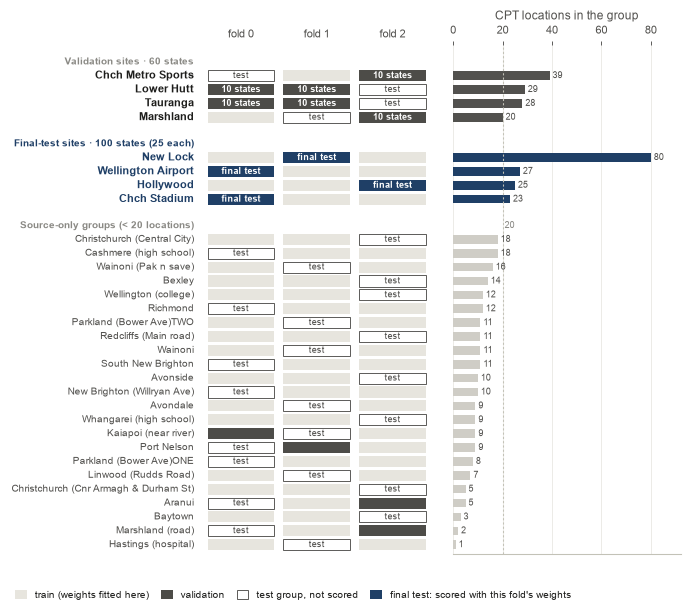

In [7]:
roles = {}
for fo in folds["folds"]:
    for role in ("train", "validation", "test"):
        for gname in fo[f"{role}_groups"]:
            roles.setdefault(gname, {})[fo["fold_id"]] = role
S = sites.set_index("investigation_group")
R = pd.DataFrame(roles).T
assert (R[[0, 1, 2]] == "test").sum(axis=1).eq(1).all(), "each group is test in exactly one fold"
R["n"] = S.n_locations.reindex(R.index); R["name"] = S.display_name.reindex(R.index)
R["site_id"] = S.site_id.reindex(R.index); R["elig"] = S.replay_eligible.reindex(R.index)
R["tier"] = np.where(R.site_id.isin(VAL_SITES), "val", np.where(R.site_id.isin(TEST_SITES), "test", "src"))
assert (R.tier != "src").sum() == R.elig.sum() == 8
order = {"val": 0, "test": 1, "src": 2}
R = R.assign(o=R.tier.map(order)).sort_values(["o", "n"], ascending=[True, False])
cnt = states.groupby(["site_id", "fold_id"]).size()
tcnt = tstates.groupby(["site_id", "fold_id"]).size()
assert all(tcnt[(s, TFOLD[s])] == 25 for s in TEST_SITES) and len(tcnt) == 4
RC = {"train": "#e7e5de", "validation": "#4d4c48", "test": "#ffffff"}

fig = plt.figure(figsize=(W, 140 * MM))
ax = fig.add_axes([.27, .06, .3, .84]); hb = fig.add_axes([.6, .06, .3, .84], sharey=ax)
y, ys, heads, prev = 0, [], [], None
for gname, r in R.iterrows():
    if r.tier != prev:
        if prev is not None: y += .9
        heads.append((r.tier, y)); y += 1.0; prev = r.tier
    ys.append(y)
    for f in range(3):
        role = r[f]
        final = r.tier == "test" and role == "test"
        ax.add_patch(Rectangle((f + .06, y - .4), .88, .8, fc=TIER_T if final else RC[role],
                               ec=INK2 if (role == "test" and not final) else "none", lw=.6))
        if final:
            ax.text(f + .5, y, "final test", ha="center", va="center", fontsize=5.9, color="white", fontweight="bold")
        elif role == "test":
            ax.text(f + .5, y, "test", ha="center", va="center", fontsize=5.6, color=INK2)
        if (r.site_id, f) in cnt.index and role == "validation":
            ax.text(f + .5, y, f"{cnt[(r.site_id, f)]} states", ha="center", va="center", fontsize=6, color="white", fontweight="bold")
    nm = SNAME.get(r.site_id, r["name"])
    ax.text(-.12, y, nm, ha="right", va="center", fontsize=6.9 if r.tier != "src" else 6.3,
            fontweight="bold" if r.tier != "src" else "normal",
            color=TIER_T if r.tier == "test" else INK if r.tier == "val" else INK2)
    hb.barh(y, r.n, height=.62, color=TIER_T if r.tier == "test" else INK2 if r.tier == "val" else "#cfcdc6", lw=0)
    hb.text(r.n + 1.2, y, f"{int(r.n)}", va="center", fontsize=6.2, color=INK2)
    y += 1
HEAD = {"val": "Validation sites · 60 states", "test": "Final-test sites · 100 states (25 each)", "src": "Source-only groups (< 20 locations)"}
for t, yh in heads:
    ax.text(-.12, yh, HEAD[t], ha="right", va="center", fontsize=6.8, fontweight="bold",
            color=TIER_T if t == "test" else MUTED)
ax.set_xlim(0, 3); ax.set_ylim(y - .3, -1.2)
ax.set_xticks([.5, 1.5, 2.5], ["fold 0", "fold 1", "fold 2"]); ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_yticks([]); [sp.set_visible(False) for sp in ax.spines.values()]
hb.axvline(20, color=AXIS, lw=.7, ls=(0, (2, 2))); hb.text(20.8, heads[-1][1], "20", fontsize=6.2, color=MUTED, va="center")
hb.set_xlim(0, 92); hb.tick_params(left=False, labelleft=False); hb.spines["left"].set_visible(False)
hb.set_xlabel("CPT locations in the group"); hgrid(hb, "x")
hb.xaxis.set_label_position("top"); hb.xaxis.tick_top()
fig.legend(handles=[Rectangle((0, 0), 1, 1, fc=RC["train"], label="train (weights fitted here)"),
                    Rectangle((0, 0), 1, 1, fc=RC["validation"], label="validation"),
                    Rectangle((0, 0), 1, 1, fc="white", ec=INK2, lw=.6, label="test group, not scored"),
                    Rectangle((0, 0), 1, 1, fc=TIER_T, label="final test: scored with this fold's weights")],
           loc="lower left", bbox_to_anchor=(.01, -.03), ncol=4, fontsize=6.5, handlelength=1.2, handleheight=1, columnspacing=1.2)
save(fig, "fig02_fold_design"); plt.show()
print("validation states per site:", states.groupby("site_id").size().rename(lambda s: SITE[s][1]).to_dict())
print("test states per site:", tstates.groupby("site_id").size().rename(TSITE).to_dict())

**Caption.** *Fig. 2. Site-grouped three-fold design (31 investigation groups). Each group is the test group in exactly one fold. Only the eight groups with at least 20 CPT locations support budget replay. VALIDATION: four of them, in their validation folds, produce all 60 validation states (cell labels); Lower Hutt and Tauranga are scored in two folds on the same location sets with different weights. FINAL TEST: the other four were never used for selection; each is scored only with the artefacts of the fold in which it is the test group (navy cells: Chch Stadium and Wellington Airport fold 0, New Lock fold 1, Hollywood fold 2), 25 states per site. In the remaining folds the test sites are training sources.*

### 图 3 · 八个可回放场地：低阻力层分布与空间可预测性

上两排每个点是一个 CPT 位置，颜色为实测低阻力层厚度（空心表示没有低值单元）；每个场地用自己的比例尺。New Lock 与 Hollywood 只有场地内局部坐标（没有全球坐标），因此它们与其他场地的分组无法用距离核实。

下图对 8 个场地做留近邻组交叉：用其余位置的 IDW（3NN）或简单平均剖面去预测每个位置。两者差距越小，邻近 CPT 带来的信息越少。这只是启发式参考，不是严格的下界。

,site,tier,idw,mean,skill
5,Wellington Airport,test,0.123,0.118,-0.043
1,Tauranga,validation,0.544,0.561,0.031
6,New Lock,test,0.922,0.962,0.041
7,Hollywood,test,0.311,0.330,0.059
4,Chch Stadium,test,0.495,0.536,0.077
2,Chch Metro Sports,validation,0.462,0.559,0.174
3,Marshland,validation,0.636,0.836,0.239
0,Lower Hutt,validation,0.535,0.927,0.423


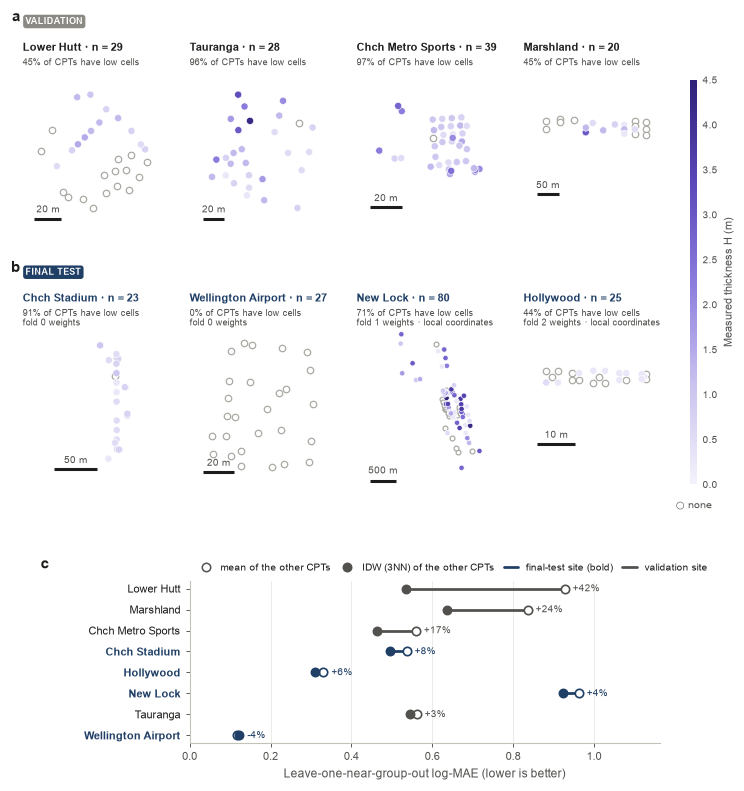

In [8]:
def loo_floor(site):
    g = grid.query("site_id == @site").pivot(index="location_id", columns="depth_index", values="log_qc")
    meta = LOC.set_index("location_id").loc[g.index]
    xy = meta[["x_m", "y_m"]].to_numpy(); grp = meta.near_group_id.to_numpy(); V = g.to_numpy()
    e_idw, e_mean = [], []
    for i in range(len(V)):
        keep = grp != grp[i]
        d = np.hypot(*(xy[keep] - xy[i]).T); k = np.argsort(d, kind="stable")[:3]
        w = 1 / np.maximum(d[k], 1e-6) ** 2
        e_idw.append(np.abs((w[:, None] * V[keep][k]).sum(0) / w.sum() - V[i]).mean())
        e_mean.append(np.abs(V[keep].mean(0) - V[i]).mean())
    return np.mean(e_idw), np.mean(e_mean)

REPLAY = VAL_SITES + TEST_SITES
assert sorted(REPLAY) == sorted(sites.query("replay_eligible").site_id)
floor = pd.DataFrame([(s, *loo_floor(s)) for s in REPLAY], columns=["site_id", "idw", "mean"])
floor["skill"] = 1 - floor.idw / floor["mean"]; floor = floor.sort_values("skill")
assert floor[floor.site_id.isin(VAL_SITES)].iloc[0].site_id == "tauranga_farmers_building"
SK = floor.set_index("site_id").skill
assert [round(100 * SK[s]) for s in ("tauranga_farmers_building", "newlock", "wellington_airport")] == [3, 4, -4]
vmax = LOC.query("site_id in @REPLAY").h_true.max()
UNVER = set(roles_t.index[~roles_t.grouping_verified])

fig = plt.figure(figsize=(W, 178 * MM))
gs = fig.add_gridspec(3, 5, width_ratios=[1, 1, 1, 1, .05], height_ratios=[1, 1, 1.05], wspace=.28, hspace=.62,
                      left=.03, right=.92, top=.93, bottom=.07)
for row, (tier, ss) in enumerate([("val", VAL_SITES), ("test", TEST_SITES)]):
    for i, s in enumerate(ss):
        ax = fig.add_subplot(gs[row, i]); d = LOC.query("site_id == @s")
        x, y_ = d.x_m - d.x_m.min(), d.y_m - d.y_m.min(); zero = d.h_true.to_numpy() == 0
        ax.scatter(x[zero], y_[zero], s=18 if len(d) < 60 else 10, facecolor="white", edgecolor="#a9a8a2", lw=.8, zorder=2)
        ax.scatter(x[~zero], y_[~zero], c=d.h_true[~zero], cmap=LOW, vmin=0, vmax=vmax, s=22 if len(d) < 60 else 12,
                   edgecolor="white", lw=.4, zorder=3)
        ax.set_aspect("equal", adjustable="datalim"); ax.margins(.12); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_title(f"{SNAME[s]} · n = {len(d)}", loc="left", fontsize=7.4, fontweight="bold", pad=19,
                     color=TIER_T if tier == "test" else INK)
        sub = f"{100*(d.h_true > 0).mean():.0f}% of CPTs have low cells"
        sub += (f"\nfold {TFOLD[s]} weights" + (" · local coordinates" if s in UNVER else "")) if tier == "test" else "\n "
        ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=6.1, color=INK2, va="bottom", linespacing=1.2)
        scalebar(ax, loc=(.02, .02))
        if i == 0:
            label(ax, "ab"[row], x=-.02, y=1.36)
            tierbadge(ax, .02, 1.35, tier)
cax = fig.add_subplot(gs[0:2, 4])
cb = fig.colorbar(mpl.cm.ScalarMappable(Normalize(0, vmax), LOW), cax=cax)
cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=6.6)
cb.set_label("Measured thickness H (m)", fontsize=7)
cax.text(.5, -.04, "○ none", transform=cax.transAxes, ha="center", va="top", fontsize=6.6, color=INK2, fontfamily="DejaVu Sans")

ax = fig.add_subplot(gs[2, 1:4])
yy = np.arange(len(floor))
for y_, r in zip(yy, floor.itertuples()):
    c = TIER_T if r.site_id in TEST_SITES else INK2
    ax.plot([r.mean, r.idw], [y_, y_], color=c, lw=1.8, zorder=1)
    ax.scatter(r.mean, y_, s=30, facecolor="white", edgecolor=c, lw=1.1, zorder=2)
    ax.scatter(r.idw, y_, s=30, color=c, zorder=3)
    ax.text(max(r.mean, r.idw) + .02, y_, f"{100*r.skill:+.0f}%", va="center", fontsize=6.8, color=c)
ax.set_yticks(yy, [SNAME[s] for s in floor.site_id])
for t, s in zip(ax.get_yticklabels(), floor.site_id):
    t.set_color(TIER_T if s in TEST_SITES else INK); t.set_fontweight("bold" if s in TEST_SITES else "normal")
ax.set_xlim(0, floor[["idw", "mean"]].max().max() + .2); hgrid(ax, "x")
ax.set_xlabel("Leave-one-near-group-out log-MAE (lower is better)")
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=5.5, mfc="white", mec=INK2, label="mean of the other CPTs"),
                   Line2D([], [], ls="", marker="o", ms=5.5, color=INK2, label="IDW (3NN) of the other CPTs"),
                   Line2D([], [], color=TIER_T, lw=1.8, label="final-test site (bold)"),
                   Line2D([], [], color=INK2, lw=1.8, label="validation site")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=6.3, columnspacing=1.0, handlelength=1.5)
label(ax, "c", x=-.3, y=1.06)
save(fig, "fig03_sites_floor"); plt.show()
display(floor.assign(site=floor.site_id.map(SNAME), tier=floor.site_id.map(lambda s: "test" if s in TEST_SITES else "validation"))
        [["site", "tier", "idw", "mean", "skill"]].round(3))

**Caption.** *Fig. 3. (a) The four validation sites and (b) the four final-test sites, each at its own 1:1 scale; colour is the measured low-layer thickness. No Wellington Airport CPT has a low cell, so its recall is undefined in the final test; New Lock (80 locations) has the most low cells. New Lock and Hollywood have only local coordinates. (c) Leave-one-near-group-out predictability of the eight replay sites. At Tauranga (validation, +3%) and New Lock (test, +4%) IDW barely beats the average profile, and at Wellington Airport it is slightly worse (−4%), which suggests limited headroom for any spatial model there. This is a heuristic, not a bound.*

### 图 4 · 一个验证状态与一个测试状态

一个"状态"由场地 × 随机种子 × 已知根数 n 确定，两层的生成器完全相同（用同一代码以种子 17、29 可以逐一重现全部 60 个验证状态）：
- 评价位置（方块）按种子随机选取完整近邻组（约 20% 的位置），从不进入已知集合；
- 初始 5 根用**最远点采样**选出，起点由种子决定；之后每轮按 maximin 再加 2 根，直到 13 根；
- 生成时只读取坐标、位置 ID 与近邻组 ID，不读 qc。

验证层用种子 17、29；最终测试用全部 5 个种子 17、29、43、71、101。评价集很小：验证每状态 4–8 根，测试每状态 5–16 根评价 CPT。

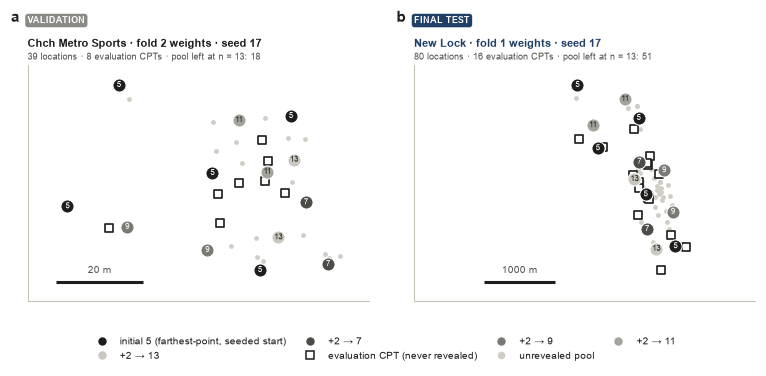

In [9]:
def state_panel(ax, ST, site, fold, seed, tier):
    st = ST.query("site_id == @site and fold_id == @fold and seed == @seed").sort_values("budget_n")
    L = LOC.query("site_id == @site").set_index("location_id"); ox, oy = L.x_m.min(), L.y_m.min()
    first = {}
    for r in st.itertuples():
        for lid in r.observed_ids: first.setdefault(lid, r.budget_n)
    ev = list(st.evaluation_ids.iloc[0]); pool = [l for l in L.index if l not in first and l not in ev]
    P = lambda ids: L.loc[list(ids)]
    ax.scatter(P(pool).x_m - ox, P(pool).y_m - oy, s=10, color="#cfcdc6", lw=0, zorder=2)
    e = P(ev); ax.scatter(e.x_m - ox, e.y_m - oy, s=30, marker="s", facecolor="white", edgecolor=INK, lw=1.1, zorder=3)
    shades = dict(zip(B5, ["#1d1d1b", "#4d4c48", "#7a7973", "#a3a29b", "#c9c7bf"]))
    for lid, n in first.items():
        p = L.loc[lid]
        ax.scatter(p.x_m - ox, p.y_m - oy, s=74, color=shades[n], edgecolor="white", lw=.7, zorder=4)
        ax.text(p.x_m - ox, p.y_m - oy, str(n), fontsize=5.5, color="white" if n <= 9 else INK, ha="center", va="center", zorder=5)
    ax.set_aspect("equal", adjustable="datalim"); ax.margins(.1); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_color(AXIS)
    ax.set_title(f"{SNAME[site]} · fold {fold} weights · seed {seed}", loc="left", fontsize=7.4, fontweight="bold", pad=12,
                 color=TIER_T if tier == "test" else INK)
    ax.text(0, 1.015, f"{len(L)} locations · {len(ev)} evaluation CPTs · pool left at n = 13: {len(pool)}",
            transform=ax.transAxes, fontsize=6.2, color=INK2, va="bottom")
    tierbadge(ax, 0, 1.17, tier)
    scalebar(ax, loc=(.04, .03))

first5 = {s: states.query("site_id == @s and budget_n == 5").groupby("seed").observed_set_id.first().nunique() for s in VAL_SITES}
assert first5["tauranga_farmers_building"] == 1      # Tauranga: both validation seeds give the same initial five

fig = plt.figure(figsize=(W, 88 * MM))
a1 = fig.add_axes([.03, .17, .45, .62]); a2 = fig.add_axes([.54, .17, .45, .62])
state_panel(a1, states, "christchurch_metro_sports_facility", 2, 17, "val"); label(a1, "a", x=-.025, y=1.17)
state_panel(a2, tstates, "newlock", 1, 17, "test"); label(a2, "b", x=-.025, y=1.17)
shades = ["#1d1d1b", "#4d4c48", "#7a7973", "#a3a29b", "#c9c7bf"]
h = [Line2D([], [], ls="", marker="o", ms=6.5, color=c, mec="white", label=f"{lab}") for c, lab in
     zip(shades, ["initial 5 (farthest-point, seeded start)", "+2 → 7", "+2 → 9", "+2 → 11", "+2 → 13"])]
h += [Line2D([], [], ls="", marker="s", ms=5.5, mfc="white", mec=INK, label="evaluation CPT (never revealed)"),
      Line2D([], [], ls="", marker="o", ms=4, color="#cfcdc6", label="unrevealed pool")]
h = [h[i] for i in (0, 4, 1, 5, 2, 6, 3)]
fig.legend(handles=h, loc="lower center", ncol=4, bbox_to_anchor=(.5, -.01), fontsize=6.6, columnspacing=1.4)
save(fig, "fig04_states"); plt.show()

**Caption.** *Fig. 4. One validation trajectory (a) and one final-test trajectory (b) produced by the same generator. Numbers give the budget n at which each CPT becomes known: five farthest-point CPTs from a seeded start, then maximin batches of two. Evaluation CPTs (squares) are fixed per site and seed and are never revealed. Validation states score 4–8 evaluation CPTs, test states 5 (Chch Stadium, Hollywood), 6 (Wellington Airport) or 16 (New Lock). The 20 test site–seed pairs use 19 distinct evaluation sets drawn from the same few CPTs per site, so seeds are not independent replicates of a site.*

## 3 · 方法：13 个固定模型入口

项目只保留 `configs/catalog.json` 中的 13 个入口，最终测试冻结的也是这 13 个：

| 组 | 入口 |
|---|---|
| 基线（4） | 常数中位数、IDW（3NN）、GP、XGBoost 残差 |
| TabPFN 组合（2） | TabPFN joint、TabPFN + 图 Huber 低值并集 |
| 主方案（3） | Balanced（均衡）、Thickness（Haar，最近剖面细节）、Recognition（识别，recall-60） |
| 讨论方案（4） | Simplex、Count-shrink、Thickness（FPR 护栏版）、CNP |

这 13 个入口是在 4 个验证场地上选出的（选择用到了验证标签）；最终测试场地从未用于选择。FPCA、形状配准、图 Huber、TabPFN 残差、整曲线决策等是**被多个入口共享的计算组件**，不单独算作模型。

几个入口的定位：
- **Thickness（Haar，最近剖面细节）** 是厚度专长方案：Haar 粗系数由核岭回归插值，细节系数取自几何上最近的已知 CPT，低值单元数由 Haar 剖面决定。它在验证上的点 FPR（10.05%）超过了 FPR 护栏（IDW + 2 pp = 9.28%）。
- **Thickness（FPR 护栏版）** 把细节系数换成 3 个近邻的加权中位数，是验证上落在护栏内的变体（点 FPR 8.99%）。
- **TabPFN joint** 的幅值底座一半来自 TabPFN 残差（以 IDW 为底、符号受 IDW 约束）、一半来自 Simplex，低值单元由整曲线决策给出，所以 **TabPFN 只提供一半的幅值底座**。
- **Count-shrink** 与 Balanced 只在低值单元数的决定上不同；**CNP** 是神经过程的负结果参照。
- GP 先去掉源训练场地的深度趋势，再在 (x, y, z) 上用 Matérn ν = 1.5 核，是唯一给出预测区间的入口；XGBoost 与 TabPFN 的残差模型在训练折场地的模拟补勘轨迹上训练，每折一个检查点。

### 图 5 · 13 个入口由哪些组件构成

- 实心圆：该组件参与点预测；
- 空心圆：该组件只出现在共享风险头里；
- 实心方块：该入口的 p_low_1 来自共享风险头。

右侧第一列写出每个入口风险列的来源。"Platt on point" 表示入口没有原生风险输出，风险列是评价时对点预测做的校准。

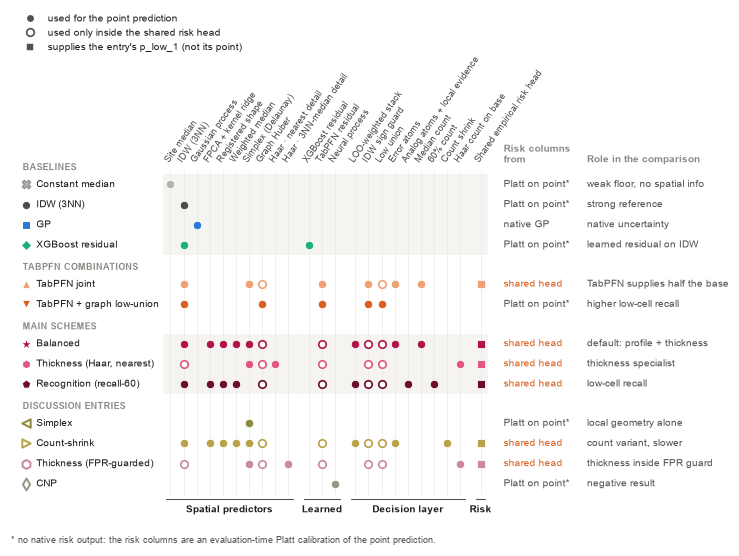

In [10]:
COLS = [("Spatial predictors", [("med", "Site median"), ("idw", "IDW (3NN)"), ("gp", "Gaussian process"),
                                ("fpca", "FPCA + kernel ridge"), ("reg", "Registered shape"), ("wmed", "Weighted median"),
                                ("splx", "Simplex (Delaunay)"), ("graph", "Graph Huber"),
                                ("haarN", "Haar · nearest detail"), ("haarM", "Haar · 3NN-median detail")]),
        ("Learned", [("xgbr", "XGBoost residual"), ("tabr", "TabPFN residual"), ("cnp", "Neural process")]),
        ("Decision layer", [("fuse", "LOO-weighted stack"), ("guard", "IDW sign guard"), ("union", "Low union"),
                            ("eatoms", "Error atoms"), ("aatoms", "Analog atoms + local evidence"),
                            ("cmed", "Median count"), ("c60", "60% count"), ("cshr", "Count shrink"),
                            ("chaar", "Haar count on base")]),
        ("Risk", [("risk", "Shared empirical risk head")])]
RISK = {"idw": "R", "tabr": "R", "guard": "R", "graph": "R", "union": "R", "risk": "S"}
STACK = {"idw": "P", "fpca": "P", "reg": "P", "wmed": "P", "fuse": "P"}
USE = {"constant": {"med": "P"}, "idw": {"idw": "P"}, "gp": {"gp": "P"}, "xgb": {"idw": "P", "xgbr": "P"},
       "tabpfn_joint": {**RISK, "idw": "P", "tabr": "P", "guard": "P", "splx": "P", "eatoms": "P", "cmed": "P"},
       "tabpfn_graph": {"idw": "P", "tabr": "P", "guard": "P", "graph": "P", "union": "P"},
       "balanced": {**RISK, **STACK, "splx": "P", "eatoms": "P", "cmed": "P"},
       "thickness": {**RISK, "splx": "P", "haarN": "P", "chaar": "P"},
       "recognition": {**RISK, **STACK, "aatoms": "P", "c60": "P"},
       "simplex": {"splx": "P"},
       "count_shrink": {**RISK, **STACK, "splx": "P", "eatoms": "P", "cshr": "P"},
       "thickness_guarded": {**RISK, "splx": "P", "haarM": "P", "chaar": "P"},
       "cnp": {"cnp": "P"}}
assert all((USE[m].get("risk") == "S") == (RISK_SRC[m] == "shared_empirical_head") for m in MODELS)
ROLE = {"constant": "weak floor, no spatial info", "idw": "strong reference", "gp": "native uncertainty",
        "xgb": "learned residual on IDW", "tabpfn_joint": "TabPFN supplies half the base",
        "tabpfn_graph": "higher low-cell recall", "balanced": "default: profile + thickness",
        "thickness": "thickness specialist", "recognition": "low-cell recall",
        "simplex": "local geometry alone", "count_shrink": "count variant, slower",
        "thickness_guarded": "thickness inside FPR guard", "cnp": "negative result"}
keys = [k for _, cs in COLS for k, _ in cs]
xpos, x = {}, 0.0
for gi, (_, cs) in enumerate(COLS):
    for k, _ in cs: xpos[k] = x; x += 1
    x += .55
XR = x - .55 - .4
rows, y = {}, 0.0
for gi, (_, _, ms) in enumerate(GROUPS):
    y += .95
    for m in ms: rows[m] = y; y += 1
YB = y - .4

fig = plt.figure(figsize=(W, 128 * MM))
ax = fig.add_axes([.205, .1, .43, .6])
ax.set_xlim(-.6, XR); ax.set_ylim(YB, -.1); ax.axis("off")
u = (XR + .6) / .43                      # data units per figure width
for gi, (gk, gname, ms) in enumerate(GROUPS):
    y0, y1 = rows[ms[0]] - .5, rows[ms[-1]] + .5
    ax.add_patch(Rectangle((-.6, y0), XR + .6, y1 - y0, fc=SOFT if gi % 2 == 0 else "#ffffff", ec="none", zorder=0))
    ax.text(-.195 * u, y0 - .12, gname.upper(), fontsize=5.8, color=MUTED, fontweight="bold", va="bottom", clip_on=False)
for k in keys:
    ax.plot([xpos[k], xpos[k]], [.3, YB - .1], color=GRID, lw=.5, zorder=1)
for m, yv in rows.items():
    for k, how in USE[m].items():
        if how == "P":
            ax.scatter(xpos[k], yv, s=30, color=COL[m], edgecolor="white", lw=.5, zorder=3)
        elif how == "R":
            ax.scatter(xpos[k], yv, s=24, facecolor="white", edgecolor=COL[m], lw=1.1, zorder=3)
        else:
            ax.scatter(xpos[k], yv, s=30, marker="s", color=COL[m], edgecolor="white", lw=.5, zorder=3)
    mscatter(ax, -.19 * u, yv, m, s=30, clip_on=False)
    ax.text(-.177 * u, yv, NAME[m], va="center", fontsize=6.7, color=INK, clip_on=False)
    rs = RSRC[RISK_SRC[m]] + ("*" if RISK_SRC[m] == "platt_on_point" else "")
    ax.text(XR + .02 * u, yv, rs, va="center", fontsize=6.3, color=INK2 if RISK_SRC[m] != "shared_empirical_head" else COL["tabpfn_graph"], clip_on=False)
    ax.text(XR + .13 * u, yv, ROLE[m], va="center", fontsize=6.3, color=INK2, clip_on=False)
for gname, cs in COLS:
    xs_ = [xpos[k] for k, _ in cs]
    for k, lab in cs:
        ax.text(xpos[k], -.05, lab, rotation=55, ha="left", va="bottom", fontsize=6.1, color=INK2, rotation_mode="anchor")
    ax.plot([min(xs_) - .35, max(xs_) + .35], [YB + .15, YB + .15], color=INK2, lw=.7, clip_on=False)
    ax.text(np.mean(xs_), YB + .45, gname, ha="center", va="top", fontsize=6.6, color=INK, fontweight="bold", clip_on=False)
ax.text(XR + .02 * u, -.05, "Risk columns\nfrom", fontsize=6.5, color=MUTED, fontweight="bold", va="bottom", linespacing=1.15)
ax.text(XR + .13 * u, -.05, "Role in the comparison", fontsize=6.5, color=MUTED, fontweight="bold", va="bottom")
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=5.5, color=INK2, mec="white", label="used for the point prediction"),
                    Line2D([], [], ls="", marker="o", ms=5, mfc="white", mec=INK2, mew=1.1, label="used only inside the shared risk head"),
                    Line2D([], [], ls="", marker="s", ms=5, color=INK2, mec="white", label="supplies the entry's p_low_1 (not its point)")],
           loc="upper left", bbox_to_anchor=(.005, .985), ncol=1, fontsize=6.5)
fig.text(.005, .015, "* no native risk output: the risk columns are an evaluation-time Platt calibration of the point prediction.",
         fontsize=6.2, color=INK2)
save(fig, "fig05_model_map"); plt.show()

**Caption.** *Fig. 5. Composition of the thirteen entries. Baselines use a single predictor. TabPFN + graph low-union averages an IDW-sign-guarded TabPFN residual with a graph-Huber smoother; TabPFN joint averages the same residual with Simplex and then applies the whole-profile count decision. The main schemes fuse several spatial predictors (Balanced, Recognition) or use Simplex with a Haar count (Thickness), and then decide the number of low cells for the whole profile. Six entries take their risk probability from one shared empirical risk head built on the TabPFN + graph low-union point prediction (squares and hollow circles), so their risk metrics are identical. GP has a native predictive distribution; for the other six entries the risk columns are a Platt calibration of the point prediction, not a native risk head.*

### 图 6 · 均衡方案的推断流程与共享风险头

图分三排：上排是均衡方案（Balanced）的点预测路径；中排是六个入口共享的风险头；下排是其他方案相对均衡方案改动了哪一步。所有步骤只读取当前已知的 CPT，查询位置的真值从不进入推断。图中描述按 `src/cpt_budget/`（`runtime.py` 与 `components/`）的实现核对过。

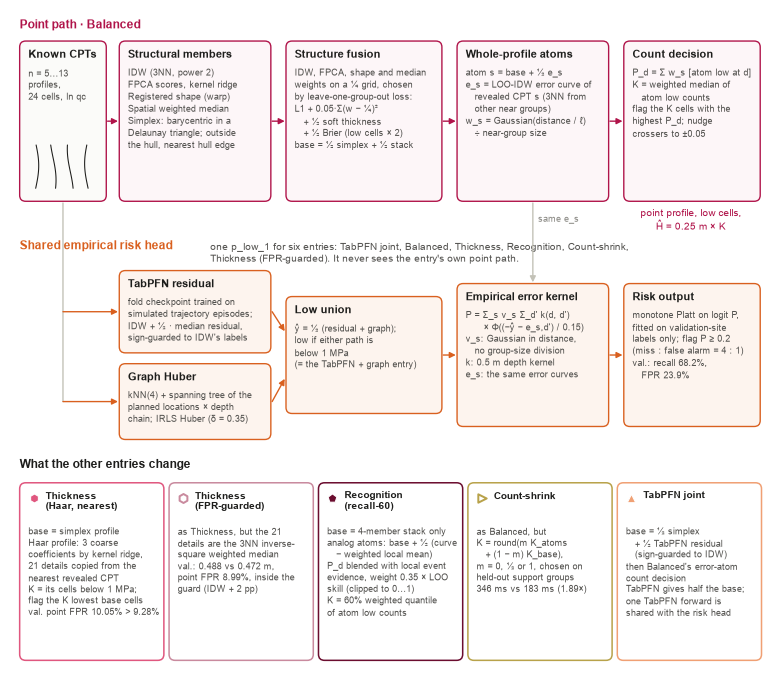

In [11]:
cs_ms, bal_ms = RTF.loc["count_shrink", "total_ms_median"], RTF.loc["balanced", "total_ms_median"]
HF = 152
fig = plt.figure(figsize=(W, HF * MM)); ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 175); ax.set_ylim(0, HF); ax.axis("off")
CB, CR = COL["balanced"], COL["tabpfn_graph"]
ax.text(2, HF - 2, "Point path · Balanced", fontsize=7.6, fontweight="bold", color=CB, va="top")
YA, HA = 108, 37
A = [(2, 20, "Known CPTs", "n = 5…13\nprofiles,\n24 cells, ln qc"),
     (25, 35, "Structural members", "IDW (3NN, power 2)\nFPCA scores, kernel ridge\nRegistered shape (warp)\nSpatial weighted median\nSimplex: barycentric in a\nDelaunay triangle; outside\nthe hull, nearest hull edge"),
     (63.5, 36, "Structure fusion", "IDW, FPCA, shape and median\nweights on a ¼ grid, chosen\nby leave-one-group-out loss:\nL1 + 0.05·Σ(w − ¼)²\n   + ½ soft thickness\n   + ½ Brier (low cells × 2)\nbase = ½ simplex + ½ stack"),
     (103, 35, "Whole-profile atoms", "atom s = base + ½ e_s\ne_s = LOO-IDW error curve of\n   revealed CPT s (3NN from\n   other near groups)\nw_s = Gaussian(distance / ℓ)\n   ÷ near-group size"),
     (141.5, 31.5, "Count decision", "P_d = Σ w_s [atom low at d]\nK = weighted median of\n   atom low counts\nflag the K cells with the\nhighest P_d; nudge\ncrossers to ±0.05")]
for x0, w, t, bdy in A:
    box(ax, x0, YA, w, HA, t, bdy, edge=CB, fill="#fdf6f8" if t != "Known CPTs" else "#fbfbf9", bsize=6.1, tsize=7.0)
for (x0, w, *_), (x1, *_) in zip(A[:-1], A[1:]):
    arrow(ax, x0 + w + .3, YA + HA / 2, x1 - .3, YA + HA / 2, c=CB)
for k_, xs_ in enumerate([4.5, 8.5, 12.5, 16.5]):
    z = np.linspace(YA + 3, YA + 13, 24); q = 1.2 + .7 * np.sin(np.linspace(0, 3, 24) + k_)
    ax.plot(xs_ + q, z, color=INK, lw=.7)
ax.text(157, YA - 1.6, "point profile, low cells,\nĤ = 0.25 m × K", fontsize=6.4, color=CB, va="top", ha="center")

YM = 99
ax.text(2, YM, "Shared empirical risk head", fontsize=7.6, fontweight="bold", color=CR, va="top")
ax.text(46, YM - .3, "one p_low_1 for six entries: TabPFN joint, Balanced, Thickness, Recognition, Count-shrink,\n"
        "Thickness (FPR-guarded). It never sees the entry's own point path.", fontsize=6.3, color=INK2, va="top", linespacing=1.3)
YB = 53
box(ax, 25, YB + 20, 35, 19, "TabPFN residual", "fold checkpoint trained on\nsimulated trajectory episodes;\nIDW + ½ · median residual,\nsign-guarded to IDW's labels", edge=CR, fill="#fdf4ee", bsize=6.0, tsize=6.9)
box(ax, 25, YB, 35, 17.5, "Graph Huber", "kNN(4) + spanning tree of the\nplanned locations × depth\nchain; IRLS Huber (δ = 0.35)", edge=CR, fill="#fdf4ee", bsize=6.0, tsize=6.9)
box(ax, 63.5, YB + 6, 36, 27, "Low union", "ŷ = ½ (residual + graph);\nlow if either path is\nbelow 1 MPa\n(= the TabPFN + graph entry)", edge=CR, fill="#fdf4ee", bsize=6.1, tsize=6.9)
box(ax, 103, YB + 3, 35, 33, "Empirical error kernel", "P = Σ_s v_s Σ_d' k(d, d')\n      × Φ((−ŷ − e_s,d') / 0.15)\nv_s: Gaussian in distance,\n   no group-size division\nk: 0.5 m depth kernel\ne_s: the same error curves", edge=CR, fill="#fdf4ee", bsize=6.0, tsize=6.9)
box(ax, 141.5, YB + 3, 31.5, 33, "Risk output", "monotone Platt on logit P,\nfitted on validation-site\nlabels only; flag P ≥ 0.2\n(miss : false alarm = 4 : 1)\n"
    f"val.: recall {100*SHARED.risk_recall:.1f}%,\n   FPR {100*SHARED.risk_fpr:.1f}%", edge=CR, fill="#fdf4ee", bsize=6.0, tsize=6.9)
arrow(ax, 12, YA - .4, 12, YB + 8.75, c=AXIS, style="-")
arrow(ax, 12, YB + 29.5, 24.7, YB + 29.5, c=CR); arrow(ax, 12, YB + 8.75, 24.7, YB + 8.75, c=CR)
arrow(ax, 60.3, YB + 29.5, 63.2, YB + 25, c=CR); arrow(ax, 60.3, YB + 8.75, 63.2, YB + 14, c=CR)
arrow(ax, 99.8, YB + 19.5, 102.7, YB + 19.5, c=CR); arrow(ax, 138.3, YB + 19.5, 141.2, YB + 19.5, c=CR)
arrow(ax, 120.5, YA - .4, 120.5, YB + 36.3, c=AXIS)
ax.text(121.7, YA - 3.2, "same e_s", fontsize=6, color=MUTED, ha="left", va="top")

ax.text(2, 48.5, "What the other entries change", fontsize=7.6, fontweight="bold", color=INK, va="top")
V = [("thickness", "Thickness\n(Haar, nearest)", "base = simplex profile\nHaar profile: 3 coarse\ncoefficients by kernel ridge,\n21 details copied from the\nnearest revealed CPT\nK = its cells below 1 MPa;\nflag the K lowest base cells\nval. point FPR 10.05% > 9.28%"),
     ("thickness_guarded", "Thickness\n(FPR-guarded)", "as Thickness, but the 21\ndetails are the 3NN inverse-\nsquare weighted median\nval.: 0.488 vs 0.472 m,\npoint FPR 8.99%, inside the\nguard (IDW + 2 pp)"),
     ("recognition", "Recognition\n(recall-60)", "base = 4-member stack only\nanalog atoms: base + ½ (curve\n   − weighted local mean)\nP_d blended with local event\nevidence, weight 0.35 × LOO\nskill (clipped to 0…1)\nK = 60% weighted quantile\nof atom low counts"),
     ("count_shrink", "Count-shrink", f"as Balanced, but\nK = round(m K_atoms\n   + (1 − m) K_base),\nm = 0, ½ or 1, chosen on\nheld-out support groups\n{cs_ms:.0f} ms vs {bal_ms:.0f} ms ({cs_ms/bal_ms:.2f}×)"),
     ("tabpfn_joint", "TabPFN joint", "base = ½ simplex\n   + ½ TabPFN residual\n   (sign-guarded to IDW)\nthen Balanced's error-atom\ncount decision\nTabPFN gives half the base;\none TabPFN forward is\nshared with the risk head")]
for i, (m, t, bdy) in enumerate(V):
    x0 = 2 + i * 34.5
    box(ax, x0, 2, 33.3, 41, None, None, edge=COL[m], fill="#ffffff", lw=1.0)
    mscatter(ax, x0 + 3.2, 39.6, m, s=30, clip_on=False)
    ax.text(x0 + 6.0, 41.3, t, fontsize=6.6, fontweight="bold", va="top", color=INK, linespacing=1.15)
    ax.text(x0 + 2.0, 33.0, bdy, fontsize=5.9, color=INK2, va="top", linespacing=1.36)
save(fig, "fig06_balanced_pipeline"); plt.show()

**Caption.** *Fig. 6. Inference in the Balanced scheme. Four spatial predictors are stacked with weights chosen on the revealed CPTs by a leave-one-group-out loss (L1 + 0.05·Σ(w − ¼)² + ½ soft thickness + ½ Brier with low cells weighted ×2), and the stack is averaged ½ : ½ with Simplex. Leave-one-out IDW error curves of the revealed CPTs (e_s) turn the fused profile into weighted whole-profile atoms, from which the number of low cells K is decided jointly for the profile. A separate shared risk head (TabPFN residual + graph-Huber low union, smoothed by the same error curves with spatial weights that are not divided by group size) supplies the probability used for the risk flags of six entries; it is Platt-calibrated on validation-site labels only. Bottom: the step each other entry changes. Numbers marked "val." are validation scores.*

## 4 · 验证结果（选择证据：4 个验证场地，60 个状态）

> 本节全部数字属于 **VALIDATION** 层：13 个入口正是在这些场地上选出的，分数偏乐观。它们说明"为什么选这 13 个"，不说明"在新场地上会怎样"——后者见第 5 节。

### 图 7 · 13 个入口的四项指标（验证）

每行一个模型，按组排列，不按成绩排序，便于跨面板对照。虚线为 IDW；点误报率面板中的点线是验证层的点 FPR 护栏（IDW + 2 pp = 9.28%）。常数中位数和 CNP 在两个误差面板上远超坐标范围，用箭头和数值标在右缘。log-MAE 保留 4 位小数。

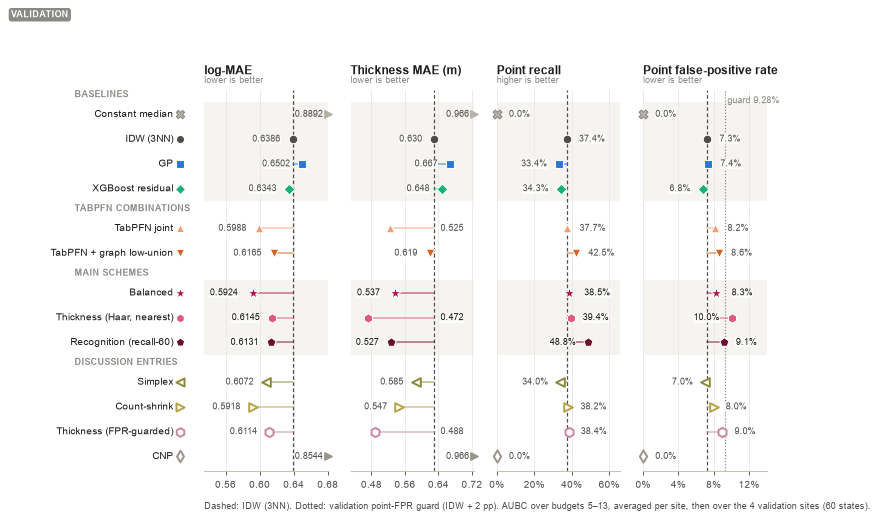

In [12]:
def multimetric(MAC, guard, pans, foot, tier, name, nsites_note=None):
    ypos, y = {}, 0.0
    for _, _, ms in GROUPS:
        for m in ms: ypos[m] = y; y += 1
        y += .6
    fig = plt.figure(figsize=(W, 116 * MM))
    axs = [fig.add_axes([.235 + i * .193, .1, .163, .76]) for i in range(4)]
    for i, (ax, (col, title, sub, xl, fmt)) in enumerate(zip(axs, pans)):
        for gi, (_, gname, ms) in enumerate(GROUPS):
            if gi % 2 == 0:
                ax.axhspan(ypos[ms[0]] - .5, ypos[ms[-1]] + .5, color=SOFT, lw=0, zorder=0)
        ref_v = MAC.loc["idw", col]; span = xl[1] - xl[0]
        ax.axvline(ref_v, color=COL["idw"], lw=.8, ls=(0, (3, 2)), zorder=1)
        if col == "false_positive_rate":
            ax.axvline(guard, color=MUTED, lw=.8, ls=(0, (1, 1.5)), zorder=1)
            ax.text(guard + span * .02, -.55, f"guard {100*guard:.2f}%", fontsize=5.9, color=MUTED, ha="left", va="center")
        for m in MODELS:
            v = MAC.loc[m, col]
            if v > xl[1]:
                ax.scatter(xl[1], ypos[m], marker=">", s=22, color=COL[m], clip_on=False, zorder=4)
                ax.text(xl[1] - span * .04, ypos[m], fmt.format(v), ha="right", va="center", fontsize=6.2, color=INK2)
                continue
            if v > 0:
                ax.plot([ref_v, v], [ypos[m], ypos[m]], color=COL[m], lw=1.1, alpha=.55, zorder=2)
            mscatter(ax, v, ypos[m], m, s=32, clip_on=False)
            right = v >= ref_v
            tw = span * (len(fmt.format(v)) * 1.25 + 3) / (.163 * 175)       # label width in data units
            if not right and v - tw < xl[0]: right = True
            if right and v + tw > xl[1]: right = False
            dx = 10 if MK[m] == "*" else 8
            anchor = v
            if right and 0 < v < ref_v:          # no room on the left: write the value just right of the IDW line
                anchor, dx = ref_v, 4
            ax.annotate(fmt.format(v), (anchor, ypos[m]), xytext=(dx if right else -dx, 0), textcoords="offset points",
                        ha="left" if right else "right", va="center", fontsize=6.2, color=INK if m in MAIN else INK2,
                        bbox=dict(fc="white", ec="none", pad=.3, alpha=.8))
        ax.set_xlim(*xl); ax.set_ylim(y - .6 - .4, -1.0); hgrid(ax, "x")
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
        ax.set_title(title, loc="left", fontsize=7.6, fontweight="bold", pad=10)
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=6.2, color=MUTED, va="bottom")
        if col in ("recall", "false_positive_rate"):
            ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
        ax.tick_params(axis="x", labelsize=6.6)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
    x0_ = pans[0][3][0]; sp0 = pans[0][3][1] - x0_
    for m in MODELS:
        mscatter(axs[0], x0_ - sp0 * .2, ypos[m], m, s=28, clip_on=False)
        axs[0].text(x0_ - sp0 * .25, ypos[m], NAME[m], ha="right", va="center", fontsize=6.7, color=INK, clip_on=False)
    for _, gname, ms in GROUPS:
        axs[0].text(x0_ - sp0 * 1.05, ypos[ms[0]] - .62, gname.upper(), fontsize=5.6, color=MUTED, fontweight="bold", va="bottom")
    tierbadge(axs[0], -.02, 1.0, tier, transform=fig.transFigure)
    fig.text(.235, .025, foot, fontsize=6.2, color=INK2)
    save(fig, name)
    return fig

PAN_V = [("log_mae", "log-MAE", "lower is better", (.535, .68), "{:.4f}"),
         ("h_point_mae_m", "Thickness MAE (m)", "lower is better", (.43, .725), "{:.3f}"),
         ("recall", "Point recall", "higher is better", (0, .66), "{:.1%}"),
         ("false_positive_rate", "Point false-positive rate", "lower is better", (0, .14), "{:.1%}")]
multimetric(MACRO, GUARD, PAN_V, "Dashed: IDW (3NN). Dotted: validation point-FPR guard (IDW + 2 pp). AUBC over budgets 5–13, "
            "averaged per site, then over the 4 validation sites (60 states).", "val", "fig07_validation_multimetric")
plt.show()

In [13]:
def metric_table(MAC, extra=None):
    T = MAC.assign(group=[dict((g, n) for g, n, _ in GROUPS)[GROUP_OF[m]] for m in MODELS], name=[NAME[m] for m in MODELS],
                   risk_source=RISK_SRC.to_numpy())
    T = T[["group", "name", "log_mae", "h_point_mae_m", "recall", "false_positive_rate", "risk_recall", "risk_fpr", "risk_brier", "risk_source"]]
    T.columns = ["group", "model", "log-MAE", "thickness MAE (m)", "point recall %", "point FPR %",
                 "risk recall %", "risk FPR %", "risk Brier", "risk_source"]
    for c in ["point recall %", "point FPR %", "risk recall %", "risk FPR %"]:
        T[c] = (100 * T[c]).round(2)
    T["log-MAE"] = T["log-MAE"].round(4); T["thickness MAE (m)"] = T["thickness MAE (m)"].round(4); T["risk Brier"] = T["risk Brier"].round(4)
    return T.reset_index(drop=True)
print("Table 1. VALIDATION · AUBC, macro over 4 validation sites (60 states).")
print("risk_source: shared_empirical_head = one shared head, identical for its six entries; native_gp = GP predictive distribution;")
print("platt_on_point = no native risk output, evaluation-time Platt calibration of the point prediction (Constant's 25%/25% is degenerate).")
print(f"Only GP has predictive intervals: nominal 90% -> {100*COV90:.2f}% actual coverage ({100*COVB.min():.1f}–{100*COVB.max():.1f}% at each budget).")
display(metric_table(MACRO))

Table 1. VALIDATION · AUBC, macro over 4 validation sites (60 states).
risk_source: shared_empirical_head = one shared head, identical for its six entries; native_gp = GP predictive distribution;
platt_on_point = no native risk output, evaluation-time Platt calibration of the point prediction (Constant's 25%/25% is degenerate).
Only GP has predictive intervals: nominal 90% -> 79.76% actual coverage (78.1–81.2% at each budget).


,group,model,log-MAE,thickness MAE (m),point recall %,point FPR %,risk recall %,risk FPR %,risk Brier,risk_source
0,Baselines,Constant median,0.8892,0.9661,0.00,0.00,25.00,25.00,0.1584,platt_on_point
1,Baselines,IDW (3NN),0.6386,0.6304,37.38,7.28,69.55,38.35,0.1304,platt_on_point
2,Baselines,GP,0.6502,0.6672,33.43,7.37,62.20,24.87,0.1252,native_gp
3,Baselines,XGBoost residual,0.6343,0.6481,34.26,6.76,68.96,39.30,0.1309,platt_on_point
4,TabPFN combinations,TabPFN joint,0.5988,0.5252,37.68,8.19,68.21,23.90,0.1211,shared_empirical_head
5,TabPFN combinations,TabPFN + graph low-union,0.6165,0.6190,42.47,8.60,74.40,29.18,0.1213,platt_on_point
6,Main schemes,Balanced,0.5924,0.5369,38.52,8.31,68.21,23.90,0.1211,shared_empirical_head
7,Main schemes,"Thickness (Haar, nearest)",0.6145,0.4725,39.38,10.05,68.21,23.90,0.1211,shared_empirical_head
8,Main schemes,Recognition (recall-60),0.6131,0.5269,48.77,9.14,68.21,23.90,0.1211,shared_empirical_head
9,Discussion entries,Simplex,0.6072,0.5853,34.00,7.04,66.65,25.03,0.1215,platt_on_point


**Caption.** *Fig. 7. VALIDATION performance of the thirteen entries (AUBC over budgets 5–13, macro over four sites). Balanced lowers log-MAE from 0.6386 (IDW) to 0.5924 and thickness error from 0.630 m to 0.537 m; Count-shrink is 0.0006 lower on log-MAE. Thickness (Haar, nearest) has the lowest thickness error (0.472 m), but its point false-positive rate (10.05%) exceeds the validation guard of 9.28%; the guarded variant reaches 0.488 m at 8.99%. Recognition raises point recall from 37.4% to 48.8% at a false-positive rate of 9.1% (IDW 7.3%). TabPFN joint reaches 0.5988 / 0.525 m. These are selection scores and are optimistic.*

**表 1** 是图 7 的数值版，另加风险三项和 `risk_source`：六个 `shared_empirical_head` 入口的风险数字完全相同；`platt_on_point` 入口的风险数字只是对点预测的校准，**不是原生风险头**；GP 是唯一给出预测区间的入口，名义 90% 区间在验证上的实际覆盖率只有 79.76%。

### 图 8 · 验证预算曲线：已知 CPT 从 5 根增加到 13 根

每个点是该预算下 4 个验证场地的宏平均（每个场地先对 fold × seed 平均）。为保持可读，讨论方案、常数中位数和 CNP 没有画出，数值见表 1。

VALIDATION · IDW − Balanced log-MAE by budget: {5: 0.032, 7: 0.047, 9: 0.05, 11: 0.052, 13: 0.04}


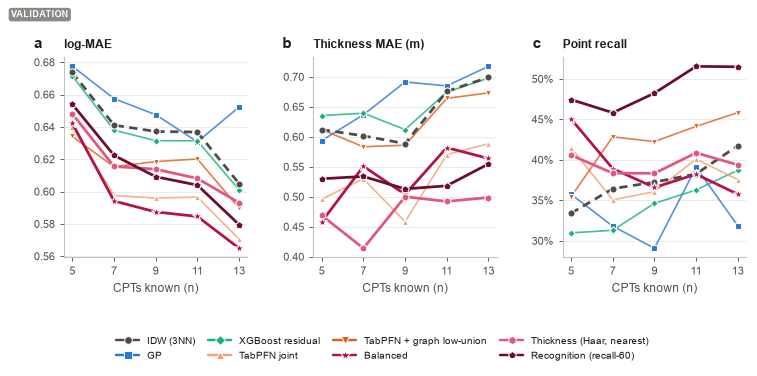

In [14]:
SEL = ["idw", "gp", "xgb", "tabpfn_joint", "tabpfn_graph", "balanced", "thickness", "recognition"]
def budget_fig(BD, tier, name, recall_note=""):
    fig, axs = plt.subplots(1, 3, figsize=(W, 84 * MM), gridspec_kw=dict(wspace=.36))
    for ax, (col, ylab, pct_) in zip(axs, [("log_mae", "log-MAE", False), ("h_point_mae_m", "Thickness MAE (m)", False),
                                          ("recall", "Point recall" + recall_note, True)]):
        for m in SEL:
            v = BD[col].xs(m, level="model_id").loc[B5]
            main = m in MAIN or m == "idw"
            ax.plot(B5, v, color=COL[m], lw=1.8 if main else 1.1, alpha=1 if main else .8,
                    ls=(0, (3, 2)) if m == "idw" else "-", zorder=3 if main else 2)
            mscatter(ax, B5, v, m, s=22 if main else 15, z=4 if main else 3)
        ax.set_xticks(B5); ax.set_xlabel("CPTs known (n)"); ax.set_title(ylab, loc="left", fontsize=7.6, fontweight="bold")
        hgrid(ax)
        if pct_: ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    for ax, l in zip(axs, "abc"): label(ax, l, x=-.12, y=1.03)
    fig.subplots_adjust(bottom=.31, top=.86, left=.08, right=.98)
    tierbadge(axs[0], .01, .965, tier, transform=fig.transFigure)
    fig.legend(handles=[mhandle(m, ms=5, line=True) for m in SEL], loc="lower center", ncol=4, bbox_to_anchor=(.5, .0),
               fontsize=6.7, columnspacing=1.3, handlelength=2.2)
    save(fig, name)
    return fig

LB = BUD.log_mae.unstack().loc[:, B5]; HB_ = BUD.h_point_mae_m.unstack().loc[:, B5]
rises = {m: [f"{a}→{b}" for a, b in zip(B5[:-1], B5[1:]) if LB.loc[m, b] > LB.loc[m, a]] for m in MODELS}
assert rises["gp"] == ["11→13"] and rises["tabpfn_graph"] == ["7→9", "9→11"] and rises["tabpfn_joint"] == ["9→11"]
assert not rises["balanced"] and not rises["idw"] and not rises["thickness"]
assert all(LB.loc[SEL, b].idxmin() == "balanced" for b in B5[1:]) and LB.loc[SEL, 5].idxmin() == "tabpfn_graph"
assert [b for b in B5 if LB.loc["count_shrink", b] < LB.loc["balanced", b]] == [5, 7, 13]
assert all(HB_.loc[m, 13] > HB_.loc[m, 5] for m in ["idw", "gp", "balanced", "thickness"])
assert HB_.loc["idw"].idxmin() == 9 and [round(HB_.loc["idw", b], 3) for b in (5, 9, 13)] == [0.612, 0.589, 0.699]
assert [round(HB_.loc["balanced", b], 3) for b in (5, 13)] == [0.458, 0.564] and [round(HB_.loc["thickness", b], 3) for b in (5, 13)] == [0.469, 0.499]
assert [b for b in B5 if HB_.loc[SEL, b].idxmin() == "thickness"] == [7, 11, 13]
budget_fig(BUD, "val", "fig08_validation_budget"); plt.show()
print("VALIDATION · IDW − Balanced log-MAE by budget:", (LB.loc["idw"] - LB.loc["balanced"]).round(3).to_dict())

**Caption.** *Fig. 8. VALIDATION error and recall as CPTs are added (macro over four validation sites). Log-MAE generally falls with budget, but not for every model: GP rises from 11 to 13 CPTs, TabPFN + graph low-union from 7 to 11, and TabPFN joint slightly from 9 to 11. Among the plotted entries Balanced is lowest from seven CPTs onwards (with five CPTs TabPFN + graph is lower). Thickness error does not improve monotonically with budget: IDW goes 0.612 m (n = 5) → 0.589 m (n = 9) → 0.699 m (n = 13), Balanced 0.458 → 0.564 m and Thickness 0.469 → 0.499 m, because each state scores only 4–8 evaluation CPTs. Recognition has the highest point recall throughout.*

### 图 9 · 四个验证场地上的剖面实例

每个场地取 seed 17、n = 9 的状态（Lower Hutt 和 Tauranga 用 fold 0）。评价 CPT 选**实测低阻力层最厚**的那一根，只看真值，不看任何模型误差。右侧色条中紫色格为 qc < 1 MPa 的单元：第一列是真值，其后依次是 IDW、Balanced 和 Thickness 的预测。

model,idw,balanced,thickness,h_true
site,,,,
Chch Metro Sports,0.5,0.75,0.25,1.00
Lower Hutt,1.0,1.00,1.25,1.00
Marshland,0.0,0.00,0.50,0.75
Tauranga,0.5,1.75,1.75,4.25


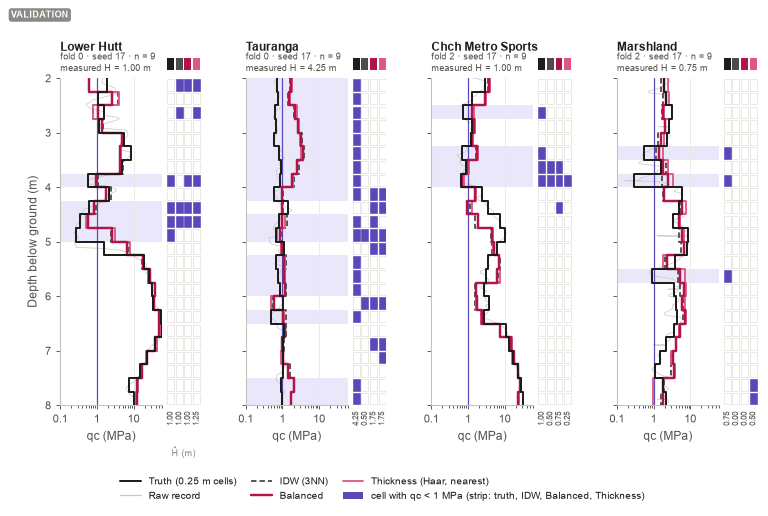

In [15]:
PM = ["idw", "balanced", "thickness"]
fig = plt.figure(figsize=(W, 118 * MM))
outer = fig.add_gridspec(1, 4, left=.075, right=.995, top=.84, bottom=.2, wspace=.32)
prof_rows = []
for i, s in enumerate(VAL_SITES):
    f = int(states.query("site_id == @s").fold_id.min())
    d = ref.query("site_id == @s and fold_id == @f and seed == 17 and budget_n == 9")
    tr = d[d.model_id == "idw"].groupby("location_id").truth_log_qc.apply(lambda v: (v < 0).sum())
    lid = tr.sort_index().idxmax()
    sub = outer[0, i].subgridspec(1, 2, width_ratios=[1, .34], wspace=.06)
    ax = fig.add_subplot(sub[0]); bc = fig.add_subplot(sub[1], sharey=ax)
    t = d[(d.model_id == "idw") & (d.location_id == lid)].sort_values("depth_index")
    for z0, l in zip(EDGES[:-1], t.truth_log_qc.to_numpy() < 0):
        if l: ax.axhspan(z0, z0 + .25, color=LOWL, lw=0, zorder=0)
    rzz, rqq = raw_profile(lid); ax.plot(rqq, rzz, color="#c9c7bf", lw=.45, zorder=1)
    xs, ys_ = stair(t.truth_qc_mpa.to_numpy()); ax.plot(xs, ys_, color=INK, lw=1.3, zorder=5)
    cols_bc = [("Truth", t.truth_log_qc.to_numpy(), INK)]
    for m in PM:
        p = d[(d.model_id == m) & (d.location_id == lid)].sort_values("depth_index")
        xs, ys_ = stair(np.exp(p.pred_log_qc.to_numpy()))
        ax.plot(xs, ys_, color=COL[m], lw=1.6 if m == "balanced" else 1.2, ls=(0, (3, 1.6)) if m == "idw" else "-", zorder=4 if m == "balanced" else 3)
        cols_bc.append((SHORT[m], p.pred_log_qc.to_numpy(), COL[m]))
        prof_rows.append(dict(site=SITE[s][1], model=m, h_pred=.25 * (p.pred_log_qc < 0).sum(), h_true=.25 * (t.truth_log_qc < 0).sum()))
    ax.axvline(1, color=LOWC, lw=.8, zorder=2)
    ax.set_xscale("log"); ax.set_xlim(.1, 60); ax.set_ylim(8, 2); ax.set_xticks([.1, 1, 10], ["0.1", "1", "10"]); hgrid(ax, "x")
    if i == 0: ax.set_ylabel("Depth below ground (m)")
    else: ax.tick_params(labelleft=False)
    ax.set_xlabel("qc (MPa)")
    ax.set_title(SITE[s][1], loc="left", fontsize=7.6, fontweight="bold", pad=18)
    ax.text(0, 1.015, f"fold {f} · seed 17 · n = 9\nmeasured H = {.25*(t.truth_log_qc < 0).sum():.2f} m", transform=ax.transAxes,
            fontsize=6.2, color=INK2, va="bottom", linespacing=1.3)
    for j, (nm, v, c) in enumerate(cols_bc):
        for z0, l in zip(EDGES[:-1], v < 0):
            bc.add_patch(Rectangle((j + .1, z0 + .02), .8, .21, fc=LOWC if l else "white", ec=LOWC if l else "#dddbd4", lw=.4))
        bc.text(j + .5, 8.12, f"{.25*(v < 0).sum():.2f}", ha="center", va="top", fontsize=5.4, color=INK2, rotation=90)
        bc.add_patch(Rectangle((j + .1, 1.62), .8, .22, fc=c, ec="none", clip_on=False))
    bc.set_xlim(0, len(cols_bc)); bc.axis("off")
    if i == 0:
        bc.text(len(cols_bc) / 2, 8.75, "Ĥ (m)", ha="center", va="top", fontsize=5.6, color=MUTED)
tierbadge(fig.axes[0], .01, .955, "val", transform=fig.transFigure)
fig.legend(handles=[Line2D([], [], color=INK, lw=1.3, label="Truth (0.25 m cells)"),
                    Line2D([], [], color="#c9c7bf", lw=.8, label="Raw record"),
                    Line2D([], [], color=COL["idw"], lw=1.2, ls=(0, (3, 1.6)), label=NAME["idw"]),
                    Line2D([], [], color=COL["balanced"], lw=1.6, label=NAME["balanced"]),
                    Line2D([], [], color=COL["thickness"], lw=1.2, label=NAME["thickness"]),
                    Rectangle((0, 0), 1, 1, fc=LOWC, label="cell with qc < 1 MPa (strip: truth, IDW, Balanced, Thickness)")],
           loc="lower center", ncol=3, bbox_to_anchor=(.5, -.005), fontsize=6.6, columnspacing=1.5)
save(fig, "fig09_validation_profiles"); plt.show()
PR = pd.DataFrame(prof_rows)
display(PR.pivot(index="site", columns="model", values="h_pred").assign(h_true=PR.groupby("site").h_true.first())[PM + ["h_true"]].round(2))

**Caption.** *Fig. 9. VALIDATION example profiles at one evaluation CPT per site (seed 17, nine CPTs known; the CPT with the thickest measured low layer). The colour strips compare low-cell labels: truth first, then IDW, Balanced and Thickness (Haar, nearest), with the implied thickness Ĥ underneath. Smooth spatial predictors rarely reach the deepest soft layers; the whole-profile count decisions of Balanced and Thickness can flag more low cells where the revealed CPTs support it, but not everywhere, and a single profile is not representative of the macro scores.*

## 5 · 最终测试结果（独立证据：4 个测试场地，100 个状态）

> 本节全部数字属于 **FINAL TEST** 层。13 个入口、指标、聚合方式、阈值和 5 个预注册问题都在看到测试真值之前冻结；揭盲只运行一次，之后没有修改任何入口或判定。只有 4 个场地，结论是**描述性的**。

### 图 10 · 测试协议：盲测 → 冻结哈希 → 只揭盲一次

上排是执行顺序；下排是每个测试场地使用的权重（它担任测试组的那一折）和风险校准器的拟合场地。

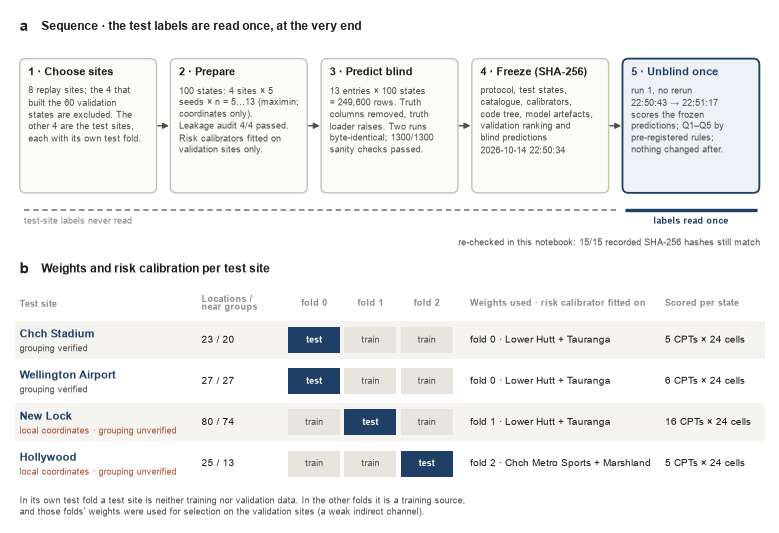

In [16]:
n_sanity = 13 * len(tstates)
assert blind["n_sanity_failed"] == 0
HF = 118
fig = plt.figure(figsize=(W, HF * MM)); ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 175); ax.set_ylim(0, HF); ax.axis("off")
ax.text(2, HF - 2, "a", fontsize=10, fontweight="bold", va="top")
ax.text(7, HF - 2.3, "Sequence · the test labels are read once, at the very end", fontsize=7.6, fontweight="bold", va="top")
STEP = [("1 · Choose sites", "8 replay sites; the 4 that\nbuilt the 60 validation\nstates are excluded. The\nother 4 are the test sites,\neach with its own test fold."),
        ("2 · Prepare", f"{len(tstates)} states: 4 sites × 5\nseeds × n = 5…13 (maximin;\ncoordinates only).\nLeakage audit 4/4 passed.\nRisk calibrators fitted on\nvalidation sites only."),
        ("3 · Predict blind", f"13 entries × {len(tstates)} states\n= {blind['prediction_rows']:,} rows. Truth\ncolumns removed, truth\nloader raises. Two runs\nbyte-identical; {n_sanity}/{n_sanity}\nsanity checks passed."),
        ("4 · Freeze (SHA-256)", "protocol, test states,\ncatalogue, calibrators,\ncode tree, model artefacts,\nvalidation ranking and\nblind predictions\n" + f"{frozen['frozen_at'][:10]} {T_FROZEN}"),
        ("5 · Unblind once", f"run 1, no rerun\n{T_START} → {T_END}\nscores the frozen\npredictions; Q1–Q5 by\npre-registered rules;\nnothing changed after.")]
YS, HS, WS, GAP = 76, 31, 31.6, 3.2
for i, (t, bdy) in enumerate(STEP):
    x0 = 2 + i * (WS + GAP); last = i == len(STEP) - 1
    box(ax, x0, YS, WS, HS, t, bdy, edge=TIER_T if last else AXIS, fill="#eef2f7" if last else "#fbfbf9",
        lw=1.2 if last else .9, tsize=6.9, bsize=6.0, tcol=TIER_T if last else INK)
    if i: arrow(ax, x0 - GAP + .3, YS + HS / 2, x0 - .3, YS + HS / 2, c=INK2)
xe = 2 + 4 * (WS + GAP)
ax.plot([3, xe - 1.2], [YS - 4, YS - 4], color=MUTED, lw=1.2, ls=(0, (3, 2)))
ax.text(3, YS - 5.5, "test-site labels never read", fontsize=6.1, color=MUTED, va="top")
ax.plot([xe + .5, xe + WS - .5], [YS - 4, YS - 4], color=TIER_T, lw=2.2, solid_capstyle="butt")
ax.text(xe + WS / 2, YS - 5.5, "labels read once", fontsize=6.1, color=TIER_T, va="top", ha="center", fontweight="bold")
ax.text(173, YS - 10.5, f"re-checked in this notebook: {int(HCHK.match.sum())}/{len(HCHK)} recorded SHA-256 hashes still match",
        fontsize=6.1, color=INK2, va="top", ha="right")

ax.text(2, 60, "b", fontsize=10, fontweight="bold", va="top")
ax.text(7, 59.7, "Weights and risk calibration per test site", fontsize=7.6, fontweight="bold", va="top")
COLX = dict(site=2, loc=44, f0=64, f1=77, f2=90, wt=106, ev=151)
yh = 50.5
for k_, t in [("site", "Test site"), ("loc", "Locations /\nnear groups"), ("wt", "Weights used · risk calibrator fitted on"),
              ("ev", "Scored per state")]:
    ax.text(COLX[k_], yh, t, fontsize=6.2, color=MUTED, fontweight="bold", va="center", linespacing=1.1)
for f in range(3):
    ax.text(COLX[f"f{f}"] + 6, yh, f"fold {f}", fontsize=6.2, color=MUTED, fontweight="bold", va="center", ha="center")
for i, s in enumerate(TEST_SITES):
    yr = 42 - i * 9.5
    r = roles_t.loc[s]
    ax.add_patch(Rectangle((1, yr - 4.4), 173, 8.8, fc=SOFT if i % 2 == 0 else "white", ec="none", zorder=0))
    ax.text(COLX["site"], yr + 1.3, TSITE[s], fontsize=6.9, fontweight="bold", color=TIER_T, va="center")
    ax.text(COLX["site"], yr - 2.0, "grouping verified" if r.grouping_verified else "local coordinates · grouping unverified",
            fontsize=5.8, color=INK2 if r.grouping_verified else BAD, va="center")
    ax.text(COLX["loc"], yr, f"{int(r.n_locations)} / {int(r.n_near_groups)}", fontsize=6.6, color=INK, va="center")
    for f in range(3):
        role = r[f"fold_{f}"]; assert role in ("train", "test")
        ax.add_patch(Rectangle((COLX[f"f{f}"], yr - 3), 12, 6, fc=TIER_T if role == "test" else "#e7e5de", ec="none"))
        ax.text(COLX[f"f{f}"] + 6, yr, role, fontsize=6.0, color="white" if role == "test" else INK2, ha="center", va="center",
                fontweight="bold" if role == "test" else "normal")
    f = TFOLD[s]
    ax.text(COLX["wt"], yr, f"fold {f} · " + " + ".join(SNAME[c] for c in sorted(CALS[f])), fontsize=6.4, color=INK, va="center")
    ax.text(COLX["ev"], yr, f"{T_EV[s]} CPTs × 24 cells", fontsize=6.4, color=INK, va="center")
ax.text(2, 1.0, "In its own test fold a test site is neither training nor validation data. In the other folds it is a training source,\n"
        "and those folds' weights were used for selection on the validation sites (a weak indirect channel).", fontsize=6.0, color=INK2,
        va="bottom", linespacing=1.3)
save(fig, "fig10_test_protocol"); plt.show()

**Caption.** *Fig. 10. FINAL TEST protocol. (a) The four test sites, 100 states, metrics, aggregation, thresholds and five questions were fixed before any test label was read. All thirteen entries predicted the test states blind (truth columns removed; two independent runs byte-identical). The protocol, states, catalogue, calibrators, code tree, model artefacts, validation ranking and predictions were frozen by SHA-256 at 22:50:34 on 2026-10-14; the single unblinding ran 22:50:43–22:51:17 and scored the frozen predictions. Every recorded hash still matches the files used here. (b) Each test site is scored with the artefacts of the fold in which it is the test group; risk calibrators were fitted on that fold's validation sites only. New Lock and Hollywood have only local coordinates, so their independence from other sites cannot be checked by distance (sensitivity analysis in Fig. 16).*

### 图 11 · 13 个入口的四项指标（最终测试）

版式与图 7 相同，但这是 4 个测试场地的等权平均。虚线为测试层的 IDW；点线为测试层的点 FPR 护栏（测试 IDW + 2 pp = 7.48%）。点召回只在 3 个场地上平均：Wellington Airport 的 5 个评价集都没有低值单元，召回无定义。**两层的绝对数值不可直接比较**（测试层包含很容易预测的 Airport），比较时看相对 IDW 的变化和名次。

Table 2. FINAL TEST · AUBC per (site, seed), mean over 5 seeds per site, equal weight over 4 test sites (100 states).
Point and risk recall average the 3 sites where they are defined (Wellington Airport has no low cell).
GP is the only entry with intervals: nominal 90% -> 86.48% on the test sites (mean width 2.169 log units).


,group,model,log-MAE,thickness MAE (m),point recall %,point FPR %,risk recall %,risk FPR %,risk Brier,risk_source,n sites (recall),GP 90% coverage %
0,Discussion entries,Count-shrink,0.5049,0.4691,25.29,5.44,46.65,17.87,0.0665,shared_empirical_head,3,NaN
1,Main schemes,Balanced,0.5052,0.4629,25.78,5.66,46.65,17.87,0.0665,shared_empirical_head,3,NaN
2,TabPFN combinations,TabPFN joint,0.5061,0.4657,23.06,5.68,46.65,17.87,0.0665,shared_empirical_head,3,NaN
3,Main schemes,Recognition (recall-60),0.5094,0.4771,28.44,6.33,46.65,17.87,0.0665,shared_empirical_head,3,NaN
4,TabPFN combinations,TabPFN + graph low-union,0.5098,0.5513,26.21,6.69,40.28,13.43,0.0685,platt_on_point,3,NaN
5,Discussion entries,Thickness (FPR-guarded),0.5171,0.4388,26.37,4.58,46.65,17.87,0.0665,shared_empirical_head,3,NaN
6,Main schemes,"Thickness (Haar, nearest)",0.5174,0.4383,28.23,4.81,46.65,17.87,0.0665,shared_empirical_head,3,NaN
7,Discussion entries,Simplex,0.5192,0.4431,18.51,5.00,68.69,14.73,0.0652,platt_on_point,3,NaN
8,Baselines,XGBoost residual,0.5278,0.4929,22.74,4.97,54.10,14.76,0.0675,platt_on_point,3,NaN
9,Baselines,IDW (3NN),0.5315,0.5036,23.37,5.48,56.98,14.97,0.0678,platt_on_point,3,NaN


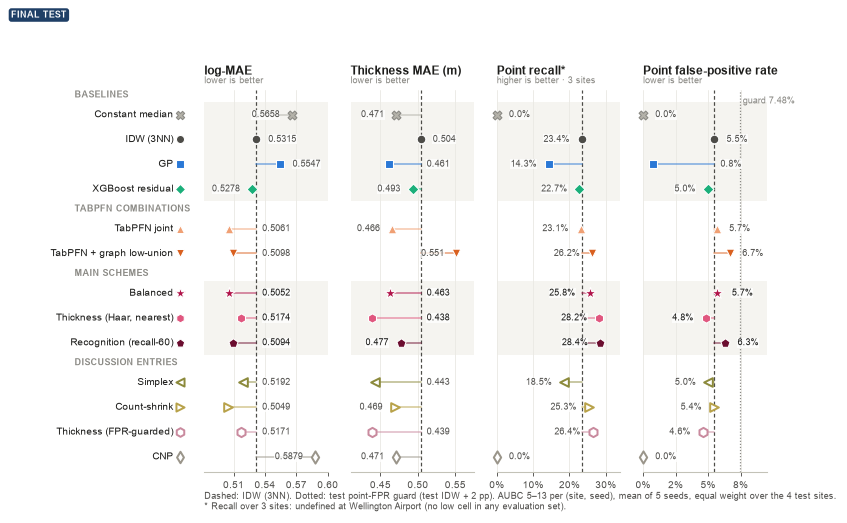

In [17]:
PAN_T = [("log_mae", "log-MAE", "lower is better", (.482, .6), "{:.4f}"),
         ("h_point_mae_m", "Thickness MAE (m)", "lower is better", (.41, .575), "{:.3f}"),
         ("recall", "Point recall*", "higher is better · 3 sites", (0, .34), "{:.1%}"),
         ("false_positive_rate", "Point false-positive rate", "lower is better", (0, .095), "{:.1%}")]
assert all(TMACRO[c].max() <= xl[1] for c, _, _, xl, _ in PAN_T)
multimetric(TMACRO, TGUARD, PAN_T, "Dashed: IDW (3NN). Dotted: test point-FPR guard (test IDW + 2 pp). AUBC 5–13 per (site, seed), mean of 5 seeds, "
            "equal weight over the 4 test sites.\n* Recall over 3 sites: undefined at Wellington Airport (no low cell in any evaluation set).",
            "test", "fig11_test_multimetric")
plt.show()
T2 = metric_table(TMACRO)
T2["n sites (recall)"] = TNSITE.recall.to_numpy()
T2["GP 90% coverage %"] = (100 * TMACRO.coverage_90).round(2).to_numpy()
print("Table 2. FINAL TEST · AUBC per (site, seed), mean over 5 seeds per site, equal weight over 4 test sites (100 states).")
print("Point and risk recall average the 3 sites where they are defined (Wellington Airport has no low cell).")
print(f"GP is the only entry with intervals: nominal 90% -> {100*TMACRO.loc['gp','coverage_90']:.2f}% on the test sites "
      f"(mean width {trank.loc['gp','width_90_log']:.3f} log units).")
display(T2.sort_values("log-MAE").reset_index(drop=True))

**Caption.** *Fig. 11. FINAL TEST performance of the thirteen entries (AUBC over budgets 5–13, equal weight over four test sites). The three lowest log-MAE values are Count-shrink 0.5049, Balanced 0.5052 and TabPFN joint 0.5061, the same three entries as in validation (IDW 0.5315). Thickness (Haar, nearest) has the lowest thickness error, 0.438 m against 0.504 m for IDW, and its point false-positive rate (4.81%) is inside the test guard of 7.48%. Recognition has the highest point recall (28.4% vs 23.4%, three sites) at a false-positive rate 0.85 pp above IDW. The Constant median's thickness error (0.471 m) is below IDW's, because it never predicts a low cell and two test sites have none or very few (Fig. 13).*

**表 2** 是图 11 的数值版（按测试 log-MAE 排序）。风险列的读法与表 1 相同；风险校准器只用验证场地拟合，测试中原样使用，迁移效果见图 17。

### 图 12 · 相对 IDW 的变化、场地胜负与 Q1–Q5 预注册判定

(a) 每个入口相对 IDW 的等权差值 Δ（入口 − IDW），右侧为按场地计的胜 / 平 / 负（|差| ≤ 1e-12 记平）。文字颜色是按预注册规则得到的判定类别：Δ 优于 IDW 且至少 ⌈0.75 n⌉ 个场地优于 IDW 为"一致改进"；Δ 优于 IDW 但胜场不足为"仅均值改进"；Δ 劣于 IDW 且至少 ⌈0.75 n⌉ 个场地更差为"一致变差"；其余为"无改进"。n = 4（召回为 3）。

(b) 五个预注册问题的逐项判定，类别名称与 `decisions.json` 完全一致，不论方向如何都报告。

FINAL TEST · difference to IDW (log-MAE, m, pp, pp) and site wins/ties/losses


,entry,log_mae Δ,h_point_mae_m Δ,recall Δ,false_positive_rate Δ,log_mae W/T/L,h_point_mae_m W/T/L,recall W/T/L,false_positive_rate W/T/L
0,Constant median,0.0343,-0.0325,-23.3715,-5.4813,2/0/2,2/1/1,0/0/3,3/1/0
1,GP,0.0232,-0.0428,-9.0449,-4.6915,1/0/3,2/1/1,0/1/2,3/1/0
2,XGBoost residual,-0.0037,-0.0107,-0.6322,-0.5125,3/0/1,2/1/1,0/1/2,3/1/0
3,TabPFN joint,-0.0254,-0.0379,-0.3066,0.2021,3/0/1,2/1/1,1/1/1,2/1/1
4,TabPFN + graph low-union,-0.0217,0.0477,2.8427,1.2087,3/0/1,0/2/2,2/1/0,0/2/2
5,Balanced,-0.0263,-0.0406,2.4039,0.1741,3/0/1,2/1/1,2/1/0,1/1/2
6,"Thickness (Haar, nearest)",-0.0142,-0.0653,4.8583,-0.6758,1/0/3,3/1/0,3/0/0,2/1/1
7,Recognition (recall-60),-0.0221,-0.0265,5.0687,0.8471,4/0/0,2/1/1,2/1/0,0/1/3
8,Simplex,-0.0123,-0.0605,-4.8651,-0.4794,1/0/3,2/1/1,2/0/1,2/1/1
9,Count-shrink,-0.0267,-0.0345,1.9145,-0.0373,3/0/1,2/1/1,1/1/1,1/1/2


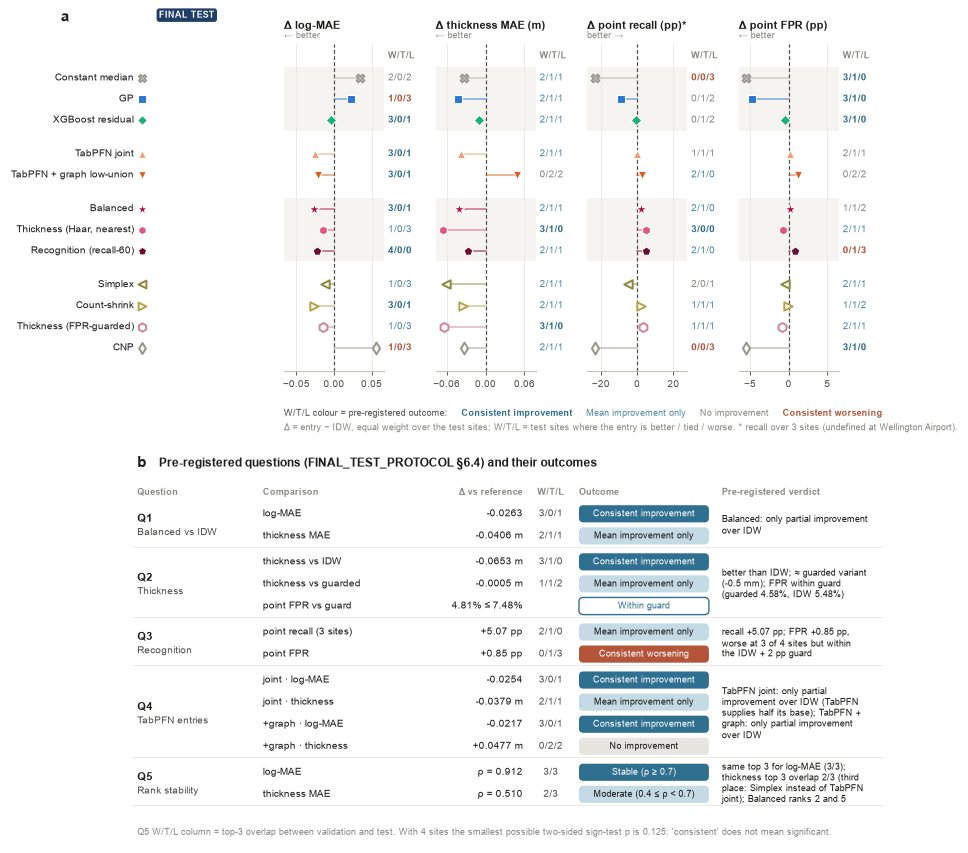

In [18]:
D_ENT = [m for m in MODELS if m != "idw"]
DP = [("log_mae", "Δ log-MAE", 1, "lower"), ("h_point_mae_m", "Δ thickness MAE (m)", 1, "lower"),
      ("recall", "Δ point recall (pp)*", 100, "higher"), ("false_positive_rate", "Δ point FPR (pp)", 100, "lower")]
ypos, y = {}, 0.0
for _, _, ms in GROUPS:
    for m in ms:
        if m == "idw": continue
        ypos[m] = y; y += 1
    y += .6
YMAX = y - .6
fig = plt.figure(figsize=(W, 196 * MM))
axs = [fig.add_axes([.205 + i * .2, .555, .132, .385]) for i in range(4)]
for i, (ax, (col, title, sc, better)) in enumerate(zip(axs, DP)):
    vals = np.array([PAIR[(m, "idw", col)]["delta"] * sc for m in D_ENT])
    lim = np.abs(vals).max() * 1.18
    for gi, (_, _, ms) in enumerate(GROUPS):
        ms_ = [m for m in ms if m != "idw"]
        if gi % 2 == 0:
            ax.axhspan(ypos[ms_[0]] - .5, ypos[ms_[-1]] + .5, color=SOFT, lw=0, zorder=0)
    ax.axvline(0, color=COL["idw"], lw=.8, ls=(0, (3, 2)), zorder=1)
    for m in D_ENT:
        p_ = PAIR[(m, "idw", col)]; v = p_["delta"] * sc
        ax.plot([0, v], [ypos[m], ypos[m]], color=COL[m], lw=1.1, alpha=.55, zorder=2)
        mscatter(ax, v, ypos[m], m, s=30, clip_on=False)
        o = p_["outcome"]
        ax.text(1.04, ypos[m], f"{p_['w']}/{p_['t']}/{p_['l']}", transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
                fontsize=6.4, color=OUTC[o][3], va="center", ha="left",
                fontweight="bold" if o in ("consistent_improvement", "consistent_deterioration") else "normal")
    ax.text(1.04, -1.05, "W/T/L", transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData), fontsize=5.9,
            color=MUTED, fontweight="bold", va="center")
    ax.set_xlim(-lim, lim); ax.set_ylim(YMAX + .1, -1.6); hgrid(ax, "x")
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3, symmetric=True)); ax.tick_params(axis="x", labelsize=6.3)
    ax.set_title(title, loc="left", fontsize=7.4, fontweight="bold", pad=10)
    ax.text(0, 1.012, "← better" if better == "lower" else "better →", transform=ax.transAxes, fontsize=6.2, color=MUTED, va="bottom",
            ha="left" if better == "lower" else "left")
for m in D_ENT:
    mscatter(axs[0], -1.42, ypos[m], m, s=26, clip_on=False, transform=mtrans.blended_transform_factory(axs[0].transAxes, axs[0].transData))
    axs[0].text(-1.5, ypos[m], NAME[m], transform=mtrans.blended_transform_factory(axs[0].transAxes, axs[0].transData),
                ha="right", va="center", fontsize=6.6, color=INK)
label(axs[0], "a", x=-2.15, y=1.06)
tierbadge(axs[0], -1.25, 1.075, "test")
prev = fig.text(.205, .505, "W/T/L colour = pre-registered outcome:", fontsize=6.2, color=INK2, va="center")
for o in ["consistent_improvement", "mean_improvement_only", "no_improvement", "consistent_deterioration"]:
    prev = axs[0].annotate(OUTC[o][0], xy=(1, .5), xycoords=prev, xytext=(9, 0), textcoords="offset points", fontsize=6.2,
                           color=OUTC[o][3], va="center", ha="left",
                           fontweight="bold" if o in ("consistent_improvement", "consistent_deterioration") else "normal")
fig.text(.205, .488, "Δ = entry − IDW, equal weight over the test sites; W/T/L = test sites where the entry is better / tied / worse. "
         "* recall over 3 sites (undefined at Wellington Airport).", fontsize=6.0, color=MUTED, va="center")

# ---- (b) Q1-Q5 verdicts -----------------------------------------------------------------------------------
bx = fig.add_axes([0, 0, 1, .465]); bx.set_xlim(0, 175); bx.set_ylim(0, 92); bx.axis("off")
bx.text(2, 90, "b", fontsize=10, fontweight="bold", va="top")
bx.text(7, 89.6, "Pre-registered questions (FINAL_TEST_PROTOCOL §6.4) and their outcomes", fontsize=7.6, fontweight="bold", va="top")
fq = lambda m, r, c: PAIR[(m, r, c)]
def dtxt(p_, col):
    v = p_["delta"]
    return f"{v:+.4f}" if col == "log_mae" else f"{v:+.4f} m" if col == "h_point_mae_m" else f"{100*v:+.2f} pp"
q2 = ANS["Q2_thickness"]; q3 = ANS["Q3_recognition"]
o = lambda m, c: PAIR[(m, "idw", c)]["outcome"]
QROWS = [
  ("Q1", "Balanced vs IDW", [("log-MAE", fq("balanced", "idw", "log_mae"), "log_mae"),
                             ("thickness MAE", fq("balanced", "idw", "h_point_mae_m"), "h_point_mae_m")],
   "Balanced: " + q_rule(o("balanced", "log_mae"), o("balanced", "h_point_mae_m"))),
  ("Q2", "Thickness", [("thickness vs IDW", fq("thickness", "idw", "h_point_mae_m"), "h_point_mae_m"),
                       ("thickness vs guarded", fq("thickness", "thickness_guarded", "h_point_mae_m"), "h_point_mae_m"),
                       ("point FPR vs guard", None, f"{100*q2['thickness_point_fpr']:.2f}% ≤ {100*q2['fpr_guard_idw_plus_2pp']:.2f}%")],
   f"better than IDW; ≈ guarded variant ({1000*fq('thickness', 'thickness_guarded', 'h_point_mae_m')['delta']:+.1f} mm); "
   f"FPR within guard (guarded {100*q2['thickness_guarded_point_fpr']:.2f}%, IDW {100*q2['idw_point_fpr']:.2f}%)"),
  ("Q3", "Recognition", [("point recall (3 sites)", fq("recognition", "idw", "recall"), "recall"),
                         ("point FPR", fq("recognition", "idw", "false_positive_rate"), "false_positive_rate")],
   f"recall +{100*fq('recognition', 'idw', 'recall')['delta']:.2f} pp; FPR +{q3['fpr_increase_pp']:.2f} pp, worse at 3 of 4 sites "
   "but within the IDW + 2 pp guard"),
  ("Q4", "TabPFN entries", [("joint · log-MAE", fq("tabpfn_joint", "idw", "log_mae"), "log_mae"),
                            ("joint · thickness", fq("tabpfn_joint", "idw", "h_point_mae_m"), "h_point_mae_m"),
                            ("+graph · log-MAE", fq("tabpfn_graph", "idw", "log_mae"), "log_mae"),
                            ("+graph · thickness", fq("tabpfn_graph", "idw", "h_point_mae_m"), "h_point_mae_m")],
   "TabPFN joint: " + q_rule(o("tabpfn_joint", "log_mae"), o("tabpfn_joint", "h_point_mae_m")) +
   " (TabPFN supplies half its base); TabPFN + graph: " + q_rule(o("tabpfn_graph", "log_mae"), o("tabpfn_graph", "h_point_mae_m"))),
  ("Q5", "Rank stability", [("log-MAE", "rho", "log_mae"), ("thickness MAE", "rho", "h_point_mae_m")],
   f"same top 3 for log-MAE ({TOP3['log_mae'][2]}/3); thickness top 3 overlap {TOP3['h_point_mae_m'][2]}/3 "
   f"(third place: Simplex instead of TabPFN joint); Balanced ranks {int(TMACRO.log_mae.rank(method='min')['balanced'])} and "
   f"{int(TMACRO.h_point_mae_m.rank(method='min')['balanced'])}"),
]
assert QROWS[1][3].startswith("better than IDW") and q2["thickness_within_fpr_guard"] and q3["within_fpr_guard_idw_plus_2pp"]
hy = 81.5
for xh, t, ha in [(2, "Question", "left"), (31, "Comparison", "left"), (91, "Δ vs reference", "right"), (97.5, "W/T/L", "center"),
                  (104, "Outcome", "left"), (137, "Pre-registered verdict", "left")]:
    bx.text(xh, hy, t, fontsize=6.1, color=MUTED, fontweight="bold", va="center", ha=ha)
yr, RH = 76.5, 5.15
import textwrap
for qi, (q, qname, items, verdict) in enumerate(QROWS):
    y0 = yr
    for (lab, p_, col) in items:
        bx.text(31, yr, lab, fontsize=6.3, color=INK, va="center")
        if p_ is None:
            bx.text(91, yr, col, fontsize=6.3, color=INK, va="center", ha="right")
            bx.add_patch(FancyBboxPatch((104, yr - 2), 30, 4, boxstyle="round,pad=0,rounding_size=1.0", fc="white", ec=GOOD, lw=.9))
            bx.text(119, yr, "Within guard", fontsize=6.2, color=GOOD, ha="center", va="center")
        elif p_ == "rho":
            st = STAB(RHO[col])
            bx.text(91, yr, f"ρ = {RHO[col]:.3f}", fontsize=6.3, color=INK, va="center", ha="right")
            bx.text(97.5, yr, f"{TOP3[col][2]}/3", fontsize=6.3, color=INK2, va="center", ha="center")
            chip(bx, 104, yr - 2, 30, 4, {"stable": "consistent_improvement", "moderate": "mean_improvement_only",
                                          "unstable": "no_improvement"}[st],
                 text={"stable": "Stable (ρ ≥ 0.7)", "moderate": "Moderate (0.4 ≤ ρ < 0.7)", "unstable": "Unstable"}[st])
        else:
            bx.text(91, yr, dtxt(p_, col), fontsize=6.3, color=INK, va="center", ha="right")
            bx.text(97.5, yr, f"{p_['w']}/{p_['t']}/{p_['l']}", fontsize=6.3, color=INK2, va="center", ha="center")
            chip(bx, 104, yr - 2, 30, 4, p_["outcome"])
        yr -= RH
    ym = (y0 + yr + RH) / 2
    bx.text(2, ym + 1.4, q, fontsize=7.2, fontweight="bold", color=INK, va="center")
    bx.text(2, ym - 1.8, qname, fontsize=6.3, color=INK2, va="center")
    bx.text(137, ym, textwrap.fill(verdict, 34), fontsize=6.0, color=INK, va="center", linespacing=1.25)
    bx.plot([1, 174], [yr + RH / 2 + .1, yr + RH / 2 + .1], color=GRID, lw=.7)
    yr -= .9
bx.text(97.5, hy - .1, "", fontsize=1)
bx.text(2, 1.2, f"Q5 W/T/L column = top-3 overlap between validation and test. With 4 sites the smallest possible two-sided sign-test p is "
        f"{SIGN_P_MIN:.3f}: 'consistent' does not mean significant.", fontsize=6.0, color=MUTED, va="bottom")
save(fig, "fig12_test_delta_verdicts"); plt.show()
assert sorted(m for m in D_ENT if PAIR[(m, "idw", "log_mae")]["w"] >= 3) == sorted(["count_shrink", "balanced", "tabpfn_joint", "recognition", "tabpfn_graph", "xgb"])
PT = pd.DataFrame([{"entry": NAME[m], **{f"{c} Δ": PAIR[(m, 'idw', c)]["delta"] * sc for c, _, sc, _ in DP},
                    **{f"{c} W/T/L": f"{PAIR[(m, 'idw', c)]['w']}/{PAIR[(m, 'idw', c)]['t']}/{PAIR[(m, 'idw', c)]['l']}" for c, _, _, _ in DP}}
                   for m in D_ENT])
print("FINAL TEST · difference to IDW (log-MAE, m, pp, pp) and site wins/ties/losses")
display(PT.round(4))

**Caption.** *Fig. 12. FINAL TEST differences to IDW and the pre-registered verdicts. (a) Δ = entry − IDW (equal weight over sites) with site wins/ties/losses; colour gives the outcome category of the pre-registered rule. Six entries (Count-shrink, Balanced, TabPFN joint, Recognition, TabPFN + graph, XGBoost) improve log-MAE at three or four of the four sites. Ties in thickness are Wellington Airport, where every entry has zero thickness error. (b) Q1: Balanced improves on IDW only partially — consistent improvement in log-MAE (−0.0263, 3/0/1), mean improvement only in thickness (−0.041 m, 2/1/1). Q2: Thickness is a consistent improvement over IDW (−0.065 m, 3/1/0), indistinguishable from its guarded variant (−0.5 mm, mean improvement only), and its point FPR 4.81% is inside the 7.48% guard. Q3: Recognition's recall gain (+5.07 pp) is a mean improvement only, and its FPR is a consistent worsening (+0.85 pp) that stays inside the guard. Q4: both TabPFN entries improve log-MAE consistently; TabPFN joint's thickness gain is mean-only and TabPFN + graph shows no thickness improvement (+0.048 m). Q5: the log-MAE ranking is stable (ρ = 0.912) and the thickness ranking moderately stable (ρ = 0.510). Four sites: descriptive only.*

### 图 13 · 逐场地结果：Airport 没有低值单元，New Lock 主导厚度

格内数字为该入口在该场地的数值（5 个种子的 AUBC 均值），颜色为相对同一场地 IDW 的变化；顶行是 IDW 自身的数值，底行是 IDW 在该场地的数值占 4 个场地之和的比例（说明等权平均主要由哪个场地决定）。斜线灰格为无定义：Wellington Airport 的评价集没有低值单元，召回无定义；该场地所有入口的厚度误差与点 FPR 都是 0。黑框标出 New Lock 上 log-MAE 低于所有空间模型的常数中位数与 CNP。

FINAL TEST · New Lock share of IDW's 4-site thickness sum: 75% · thickness MAE at New Lock across entries: 1.31–1.68 m
low-cell share of evaluation cells: {'Chch Stadium': '7.2%', 'Wellington Airport': '0.0%', 'New Lock': '22.2%', 'Hollywood': '2.0%'}


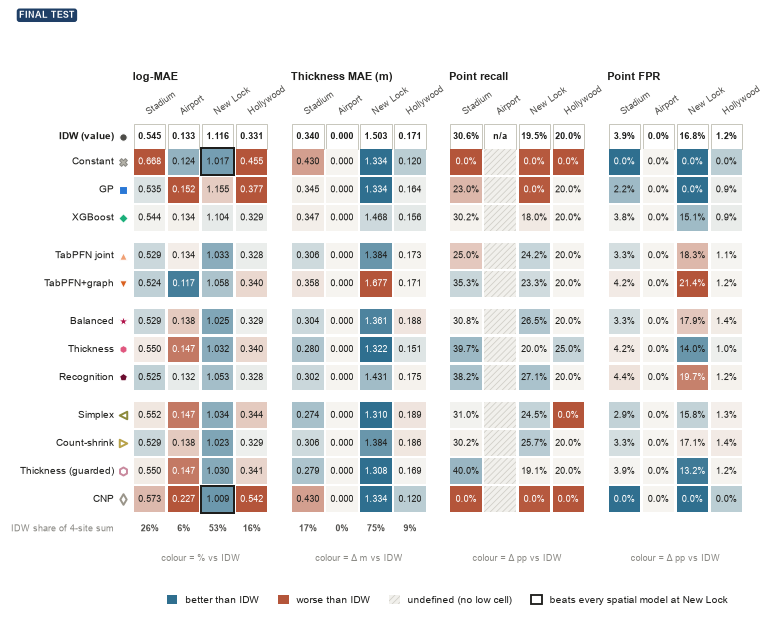

In [19]:
def site_heat(ST, slist, HM, frames, tier, name, frame_label, colsub=None, share=False, fh=128):
    rows_m = [m for m in MODELS if m != "idw"]
    fig = plt.figure(figsize=(W, fh * MM))
    n = len(HM); left = .155; wp = (.99 - left) / n
    axs = [fig.add_axes([left + i * wp, .11, wp * .86, .7]) for i in range(n)]
    for k, (ax, (col, title, fmt, dfun, unit, lower_better)) in enumerate(zip(axs, HM)):
        M_ = np.array([[dfun(ST.loc[(m, s), col], ST.loc[("idw", s), col]) for s in slist] for m in rows_m], float)
        fin = np.abs(M_[np.isfinite(M_)])
        lim = np.percentile(fin, 90) if fin.size and np.percentile(fin, 90) > 0 else 1.0
        norm = TwoSlopeNorm(0, -lim, lim)
        C = DIV(norm(np.nan_to_num(M_ if lower_better else -M_)))
        yy, gap = {}, 0
        for i, m in enumerate(rows_m):
            if i and GROUP_OF[m] != GROUP_OF[rows_m[i - 1]]: gap += .35
            yy[m] = i + 1.4 + gap
        ybot = max(yy.values())
        for j, s in enumerate(slist):
            iv = ST.loc[("idw", s), col]
            ax.add_patch(Rectangle((j + .04, .04), .92, .92, fc="#ffffff", ec=AXIS, lw=.6))
            ax.text(j + .5, .5, "n/a" if np.isnan(iv) else fmt.format(iv), ha="center", va="center", fontsize=6.2, color=INK, fontweight="bold")
            for i, m in enumerate(rows_m):
                v = ST.loc[(m, s), col]
                if np.isnan(v):
                    ax.add_patch(Rectangle((j + .04, yy[m] - .46), .92, .92, fc="#f1f0ec", ec="#cfcdc6", lw=.0, hatch="//////"))
                    continue
                ax.add_patch(Rectangle((j + .04, yy[m] - .46), .92, .92, fc=C[i, j], ec="none"))
                dark = abs(norm(M_[i, j]) - .5) > .36
                ax.text(j + .5, yy[m], fmt.format(v), ha="center", va="center", fontsize=5.9, color="white" if dark else INK)
            if share and col in ("log_mae", "h_point_mae_m"):
                tot = sum(ST.loc[("idw", s_), col] for s_ in slist)
                ax.text(j + .5, ybot + 1.05, f"{100*iv/tot:.0f}%", ha="center", va="center", fontsize=6.2, color=INK2, fontweight="bold")
        if share and k == 0:
            ax.text(-.55, ybot + 1.05, "IDW share of 4-site sum", ha="right", va="center", fontsize=5.8, color=MUTED, clip_on=False)
        for (fm, fs, fc_) in frames:
            if fc_ == col:
                j = slist.index(fs)
                ax.add_patch(Rectangle((j + .02, yy[fm] - .48), .96, .96, fc="none", ec=INK, lw=1.3, zorder=5))
        ax.set_xlim(0, len(slist)); ax.set_ylim(ybot + (1.6 if share else .55), -.1)
        labs = [(colsub or SNAME)[s] for s in slist]
        ax.set_xticks(np.arange(len(slist)) + .5, labs, rotation=35, ha="left", fontsize=6.2, rotation_mode="anchor")
        ax.xaxis.tick_top(); ax.tick_params(length=0, pad=2)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_yticks([])
        ax.set_title(title, loc="left", fontsize=7.4, fontweight="bold", pad=8 + 2.0 * max(len(l) for l in labs))
        ax.text(len(slist) / 2, ybot + (1.95 if share else .8), f"colour = {unit}", fontsize=6.0, color=MUTED, va="top", ha="center")
        if k == 0:
            mscatter(ax, -.28, .5, "idw", s=24, clip_on=False)
            ax.text(-.55, .5, "IDW (value)", va="center", ha="right", fontsize=6.5, clip_on=False, fontweight="bold")
            for m in rows_m:
                mscatter(ax, -.28, yy[m], m, s=24, clip_on=False)
                ax.text(-.55, yy[m], SHORT[m], va="center", ha="right", fontsize=6.5, clip_on=False)
    tierbadge(axs[0], .005, .975, tier, transform=fig.transFigure)
    h = [Rectangle((0, 0), 1, 1, fc=GOOD, label="better than IDW"), Rectangle((0, 0), 1, 1, fc=BAD, label="worse than IDW")]
    if any(np.isnan(ST.loc[(m, s), c]) for m in MODELS for s in slist for c, *_ in HM):
        h.append(Rectangle((0, 0), 1, 1, fc="#f1f0ec", ec="#cfcdc6", lw=0, hatch="//////", label="undefined (no low cell)"))
    if frames:
        h.append(Rectangle((0, 0), 1, 1, fc="none", ec=INK, lw=1.2, label=frame_label))
    fig.legend(handles=h, loc="lower center", ncol=len(h), bbox_to_anchor=(.57, -.005), fontsize=6.4, handlelength=1.1, handleheight=1)
    save(fig, name)
    return fig

HM_T = [("log_mae", "log-MAE", "{:.3f}", lambda v, r: 100 * (v / r - 1), "% vs IDW", True),
        ("h_point_mae_m", "Thickness MAE (m)", "{:.3f}", lambda v, r: v - r, "Δ m vs IDW", True),
        ("recall", "Point recall", "{:.1%}", lambda v, r: 100 * (v - r), "Δ pp vs IDW", False),
        ("false_positive_rate", "Point FPR", "{:.1%}", lambda v, r: 100 * (v - r), "Δ pp vs IDW", True)]
spatial = [m for m in MODELS if m not in ("constant", "cnp")]
NLL = TSITE_T.xs("newlock", level="site_id").log_mae
assert NLL[["constant", "cnp"]].max() < NLL[spatial].min()
FR_T = [("constant", "newlock", "log_mae"), ("cnp", "newlock", "log_mae")]
CSUB = {"christchurch_stadium": "Stadium", "wellington_airport": "Airport", "newlock": "New Lock", "hollywood": "Hollywood"}
site_heat(TSITE_T, TEST_SITES, HM_T, FR_T, "test", "fig13_test_sites", "beats every spatial model at New Lock",
          colsub=CSUB, share=True, fh=140)
plt.show()
share_h = TSITE_T.loc["idw"].h_point_mae_m / TSITE_T.loc["idw"].h_point_mae_m.sum()
assert abs(share_h["newlock"] - .75) < .01
HW = TSITE_T.xs("hollywood", level="site_id").h_point_mae_m
assert set(HW[HW == HW.min()].index) == {"constant", "cnp"}
print(f"FINAL TEST · New Lock share of IDW's 4-site thickness sum: {100*share_h['newlock']:.0f}% · "
      f"thickness MAE at New Lock across entries: {TSITE_T.xs('newlock', level='site_id').h_point_mae_m.min():.2f}–"
      f"{TSITE_T.xs('newlock', level='site_id').h_point_mae_m.max():.2f} m")
print("low-cell share of evaluation cells:", {TSITE[s]: f"{100*LOWSHARE[s]:.1f}%" for s in TEST_SITES})

**Caption.** *Fig. 13. FINAL TEST results per site (mean of five seeds). Wellington Airport has no low cell in any evaluation set: recall is undefined (hatched), and every entry has zero thickness error and zero point FPR there, so the equal-weight recall uses three sites and Airport only adds ties to thickness comparisons. New Lock, with 16 evaluation CPTs and the most low cells, carries three quarters of IDW's four-site thickness error (1.3–1.7 m for every entry), so the thickness conclusions are dominated by New Lock. At New Lock the Constant median and CNP have lower log-MAE than every spatial model (framed). At Hollywood the Constant median and CNP, which never predict a low cell, have the lowest thickness error. Absolute errors are lower than in validation mainly because Airport is easy; compare changes against IDW, not levels across tiers.*

### 图 14 · 测试预算曲线

每个点是该预算下 4 个测试场地的等权平均（每个场地先对 5 个种子平均；召回为 3 个场地）。所选入口与图 8 相同。

FINAL TEST · IDW − Balanced log-MAE by budget: {5: 0.017, 7: 0.018, 9: 0.028, 11: 0.036, 13: 0.03}
FINAL TEST · thickness MAE n = 5 → 13: {'IDW': (np.float64(0.581), np.float64(0.482)), 'Balanced': (np.float64(0.541), np.float64(0.432)), 'Thickness': (np.float64(0.544), np.float64(0.408)), 'GP': (np.float64(0.459), np.float64(0.471))}
lowest thickness MAE per budget: {5: 'GP', 7: 'Thickness', 9: 'Thickness', 11: 'Thickness', 13: 'Thickness'}


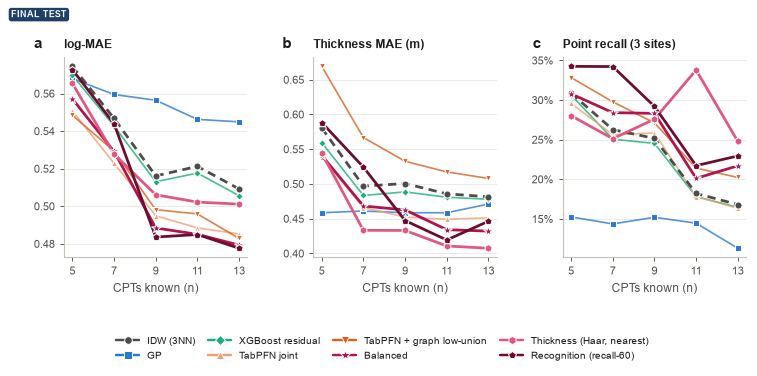

In [20]:
TLB = TBUD.log_mae.unstack().loc[:, B5]; THB = TBUD.h_point_mae_m.unstack().loc[:, B5]
assert all(TLB.loc[m, 13] < TLB.loc[m, 5] for m in SEL)
assert all(THB.loc[m, 13] < THB.loc[m, 5] for m in ["idw", "balanced", "thickness"]) and THB.loc["gp"].between(.455, .475).all()
budget_fig(TBUD, "test", "fig14_test_budget", recall_note=" (3 sites)"); plt.show()
print("FINAL TEST · IDW − Balanced log-MAE by budget:", (TLB.loc["idw"] - TLB.loc["balanced"]).round(3).to_dict())
print("FINAL TEST · thickness MAE n = 5 → 13:", {SHORT[m]: (round(THB.loc[m, 5], 3), round(THB.loc[m, 13], 3)) for m in ["idw", "balanced", "thickness", "gp"]})
print("lowest thickness MAE per budget:", {b: SHORT[THB.loc[SEL, b].idxmin()] for b in B5})

**Caption.** *Fig. 14. FINAL TEST error and recall as CPTs are added (equal weight over four test sites). Every plotted entry has lower log-MAE with 13 CPTs than with 5. Unlike validation, the thickness error of IDW, Balanced and Thickness also falls from 5 to 13 CPTs, while GP stays almost flat near 0.46 m. The curves average only 4 sites × 5 seeds and are dominated by New Lock for thickness and recall.*

### 图 15 · 名次稳定性：验证名次 vs 测试名次（Q5）

每个点是一个入口在验证层（横轴）与测试层（纵轴）的名次（1 = 最好；并列取最小名次，并列的点左右微移）。灰色方块是双方都进入前 3 的区域。对角线表示名次不变。

,val log-MAE rank,test log-MAE rank,val thickness rank,test thickness rank
model_id,,,,
Count-shrink,1,1,6,7
Balanced,2,2,5,5
TabPFN joint,3,3,3,6
Recognition (recall-60),6,4,4,10
TabPFN + graph low-union,8,5,8,13
Thickness (FPR-guarded),5,6,2,2
"Thickness (Haar, nearest)",7,7,1,1
Simplex,4,8,7,3
XGBoost residual,9,9,10,11


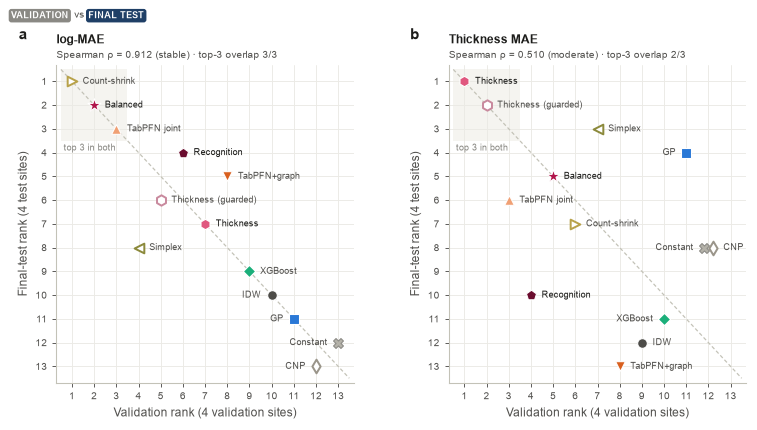

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(W, 98 * MM), gridspec_kw=dict(wspace=.32))
OFFS = {"log_mae": {}, "h_point_mae_m": {}}
for k, (ax, col, title) in enumerate(zip(axs, ["log_mae", "h_point_mae_m"], ["log-MAE", "Thickness MAE"])):
    rv, rt_ = MACRO[col].rank(method="min"), TMACRO[col].rank(method="min")
    ax.add_patch(Rectangle((.5, .5), 3, 3, fc=SOFT, ec="none", zorder=0))
    ax.text(.62, 3.62, "top 3 in both", fontsize=6.0, color=MUTED, ha="left", va="top")
    ax.plot([.5, 13.5], [.5, 13.5], color=AXIS, lw=.8, ls=(0, (3, 2)), zorder=1)
    seen = {}
    for m in MODELS:
        key = (rv[m], rt_[m]); seen.setdefault(key, []).append(m)
    for key, ms in seen.items():
        for j, m in enumerate(ms):
            dx = (j - (len(ms) - 1) / 2) * .38
            mscatter(ax, key[0] + dx, key[1], m, s=40, z=4)
            side = 1 if key[0] <= 9 else -1
            if len(ms) > 1: side = 1 if j == len(ms) - 1 else -1
            ax.annotate(SHORT[m], (key[0] + dx, key[1]), xytext=(7 * side, 0), textcoords="offset points", fontsize=6.2,
                        ha="left" if side > 0 else "right", va="center", color=INK if m in MAIN else INK2)
    ax.set_xlim(.3, 13.7); ax.set_ylim(13.7, .3)
    ax.set_xticks(range(1, 14)); ax.set_yticks(range(1, 14)); ax.tick_params(labelsize=6.3); hgrid(ax, "both")
    ax.set_xlabel("Validation rank (4 validation sites)"); ax.set_ylabel("Final-test rank (4 test sites)")
    ax.set_title(title, loc="left", fontsize=7.6, fontweight="bold", pad=14)
    v3, t3, ov = TOP3[col]
    ax.text(0, 1.015, f"Spearman ρ = {RHO[col]:.3f} ({STAB(RHO[col])}) · top-3 overlap {ov}/3", transform=ax.transAxes,
            fontsize=6.4, color=INK2, va="bottom")
    label(ax, "ab"[k], x=-.1, y=1.07)
tierbadge(axs[0], .01, .965, "val", transform=fig.transFigure)
fig.text(.1, .966, "vs", fontsize=6.6, color=INK2, va="bottom", ha="center")
tierbadge(axs[0], .112, .965, "test", transform=fig.transFigure)
fig.subplots_adjust(top=.86, bottom=.11, left=.07, right=.98)
save(fig, "fig15_rank_stability"); plt.show()
RK = pd.DataFrame({"val log-MAE rank": MACRO.log_mae.rank(method="min"), "test log-MAE rank": TMACRO.log_mae.rank(method="min"),
                   "val thickness rank": MACRO.h_point_mae_m.rank(method="min"), "test thickness rank": TMACRO.h_point_mae_m.rank(method="min")}).astype(int)
assert RK.loc["idw", "val log-MAE rank"] == RK.loc["idw", "test log-MAE rank"] == 10
assert (RK.loc["simplex", ["val thickness rank", "test thickness rank"]].tolist() == [7, 3]
        and RK.loc["gp", ["val thickness rank", "test thickness rank"]].tolist() == [11, 4] and RK.loc["tabpfn_graph", "test thickness rank"] == 13)
display(RK.rename(index=NAME).sort_values("test log-MAE rank"))

**Caption.** *Fig. 15. Rank stability between VALIDATION and FINAL TEST (Q5). (a) log-MAE: ρ = 0.912 (stable); the top three are the same entries in the same order (Count-shrink, Balanced, TabPFN joint), and IDW stays tenth. (b) Thickness MAE: ρ = 0.510 (moderate); Thickness and its guarded variant stay first and second, Simplex rises from seventh to third, GP from eleventh to fourth, and TabPFN + graph falls to last. The Constant median and CNP tie (they never predict a low cell). Validation ranks were frozen before unblinding.*

### 图 16 · 敏感性分析：只用分组已核实的 2 个场地

New Lock 与 Hollywood 没有全球坐标，无法核实它们与训练场地的距离，所以协议预先规定：同时报告只含分组已核实的 Chch Stadium 与 Wellington Airport 的结果。注意 Airport 没有低值单元，所以这里的召回和厚度实际只由 Chch Stadium 决定（召回 n = 1）。

(a) 预注册比较在两种场地集合上的判定；(b) 12 个入口相对 IDW 的变化（%），两种场地集合对照。

,comparison,four_sites,four_delta,two_sites,two_delta,same_direction
0,Balanced · log-MAE,Consistent improvement,-0.0263,Mean improvement only,-0.0059,True
1,Balanced · thickness MAE,Mean improvement only,-0.0406,Mean improvement only,-0.0181,True
2,Thickness · thickness MAE,Consistent improvement,-0.0653,Mean improvement only,-0.0300,True
3,Thickness vs guarded · thickness MAE,Mean improvement only,-0.0005,No improvement,0.0006,False
4,Recognition · point recall,Mean improvement only,0.0507,Consistent improvement,0.0759,True
5,Recognition · point FPR,Consistent worsening,0.0085,No improvement,0.0023,True
6,TabPFN joint · log-MAE,Consistent improvement,-0.0254,Mean improvement only,-0.0077,True
7,TabPFN joint · thickness MAE,Mean improvement only,-0.0379,Mean improvement only,-0.0169,True
8,TabPFN + graph · log-MAE,Consistent improvement,-0.0217,Consistent improvement,-0.0187,True
9,TabPFN + graph · thickness MAE,No improvement,0.0477,No improvement,0.0088,True


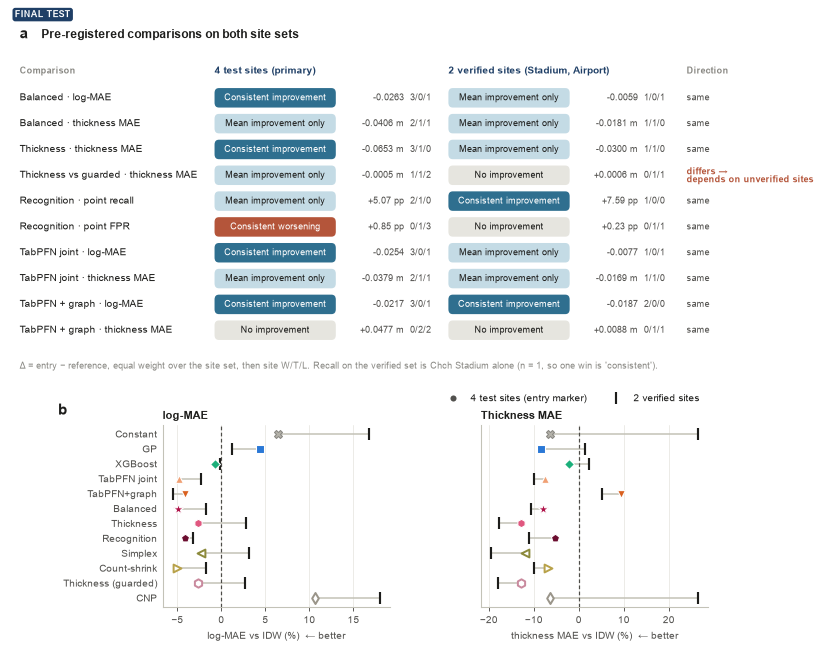

In [22]:
CMP = [("Balanced", "balanced", "idw", "log_mae"), ("Balanced", "balanced", "idw", "h_point_mae_m"),
       ("Thickness", "thickness", "idw", "h_point_mae_m"), ("Thickness vs guarded", "thickness", "thickness_guarded", "h_point_mae_m"),
       ("Recognition", "recognition", "idw", "recall"), ("Recognition", "recognition", "idw", "false_positive_rate"),
       ("TabPFN joint", "tabpfn_joint", "idw", "log_mae"), ("TabPFN joint", "tabpfn_joint", "idw", "h_point_mae_m"),
       ("TabPFN + graph", "tabpfn_graph", "idw", "log_mae"), ("TabPFN + graph", "tabpfn_graph", "idw", "h_point_mae_m")]
MLAB = {"log_mae": "log-MAE", "h_point_mae_m": "thickness MAE", "recall": "point recall", "false_positive_rate": "point FPR"}
SENS = []
for lab, m, r, c in CMP:
    p4, p2 = PAIR[(m, r, c)], compare(m, r, c, site_list=V2)
    sgn = lambda d: np.sign(-d if LOWER[c] else d)
    SENS.append(dict(lab=lab, m=m, r=r, c=c, p4=p4, p2=p2, agree=sgn(p4["delta"]) == sgn(p2["delta"])))
SD = {(s["m"], s["r"], s["c"]): s for s in SENS}
assert SD[("thickness", "thickness_guarded", "h_point_mae_m")]["p2"]["outcome"] == "no_improvement" and not SD[("thickness", "thickness_guarded", "h_point_mae_m")]["agree"]
assert sum(not s["agree"] for s in SENS) == 1
assert SD[("recognition", "idw", "recall")]["p2"]["n"] == 1 and SD[("recognition", "idw", "recall")]["p2"]["outcome"] == "consistent_improvement"
assert abs(SD[("balanced", "idw", "log_mae")]["p2"]["delta"] - (TMACRO2.loc["balanced", "log_mae"] - TMACRO2.loc["idw", "log_mae"])) < 1e-12

b2 = SD[("balanced", "idw", "log_mae")]["p2"]; r2 = SD[("recognition", "idw", "false_positive_rate")]["p2"]
assert round(b2["delta"], 4) == -0.0059 and (b2["w"], b2["l"]) == (1, 1) and round(100 * r2["delta"], 2) == 0.23
fig = plt.figure(figsize=(W, 150 * MM))
ax = fig.add_axes([0, .43, 1, .54]); ax.set_xlim(0, 175); ax.set_ylim(0, 72); ax.axis("off")
ax.text(2, 71, "a", fontsize=10, fontweight="bold", va="top")
ax.text(7, 70.6, "Pre-registered comparisons on both site sets", fontsize=7.6, fontweight="bold", va="top")
def dfmt(p_, c):
    v = p_["delta"]
    return f"{v:+.4f}" if c == "log_mae" else f"{v:+.4f} m" if c == "h_point_mae_m" else f"{100*v:+.2f} pp"
HX = dict(lab=2, c4=47, d4=82, c2=101, d2=136, ag=156)
hy = 62
ax.text(HX["lab"], hy, "Comparison", fontsize=6.1, color=MUTED, fontweight="bold", va="center")
ax.text(HX["c4"], hy, "4 test sites (primary)", fontsize=6.3, color=TIER_T, fontweight="bold", va="center")
ax.text(HX["c2"], hy, "2 verified sites (Stadium, Airport)", fontsize=6.3, color=TIER_T, fontweight="bold", va="center")
ax.text(HX["ag"], hy, "Direction", fontsize=6.1, color=MUTED, fontweight="bold", va="center")
yr = 56.5
for s in SENS:
    ref_lab = "" if s["r"] == "idw" else " (vs guarded)"
    ax.text(HX["lab"], yr, f"{s['lab']} · {MLAB[s['c']]}", fontsize=6.3, color=INK, va="center")
    for key, p_ in (("4", s["p4"]), ("2", s["p2"])):
        chip(ax, HX["c" + key], yr - 2, 28, 4, p_["outcome"], fs=5.9)
        ax.text(HX["d" + key] + 15, yr, dfmt(p_, s["c"]) + f"  {p_['w']}/{p_['t']}/{p_['l']}", fontsize=6.0, color=INK2, va="center", ha="right")
    ax.text(HX["ag"], yr, "same" if s["agree"] else "differs →\ndepends on unverified sites", fontsize=6.0 if s["agree"] else 5.7,
            color=INK2 if s["agree"] else BAD, va="center", fontweight="normal" if s["agree"] else "bold", linespacing=1.1)
    yr -= 5.3
ax.text(2, .5, "Δ = entry − reference, equal weight over the site set, then site W/T/L. Recall on the verified set is Chch Stadium alone "
        "(n = 1, so one win is 'consistent').", fontsize=6.0, color=MUTED, va="bottom")

for k, col in enumerate(["log_mae", "h_point_mae_m"]):
    bx = fig.add_axes([.2 + k * .42, .07, .3, .28])
    yy = {m: i for i, m in enumerate(D_ENT)}
    bx.axvline(0, color=COL["idw"], lw=.8, ls=(0, (3, 2)))
    for m in D_ENT:
        v4 = 100 * (TMACRO.loc[m, col] / TMACRO.loc["idw", col] - 1); v2 = 100 * (TMACRO2.loc[m, col] / TMACRO2.loc["idw", col] - 1)
        bx.plot([v4, v2], [yy[m], yy[m]], color=AXIS, lw=1.0, zorder=1)
        bx.scatter(v2, yy[m], marker="|", s=60, color=INK, lw=1.4, zorder=3)
        mscatter(bx, v4, yy[m], m, s=26, z=4)
    bx.set_ylim(len(D_ENT) - .4, -.6); hgrid(bx, "x")
    bx.set_yticks(range(len(D_ENT)), [SHORT[m] for m in D_ENT] if k == 0 else [], fontsize=6.3)
    bx.tick_params(axis="y", length=0); bx.tick_params(axis="x", labelsize=6.3)
    bx.set_xlabel(f"{MLAB[col]} vs IDW (%)  ← better", fontsize=6.8)
    bx.set_title({"log_mae": "log-MAE", "h_point_mae_m": "Thickness MAE"}[col], loc="left", fontsize=7.4, fontweight="bold", pad=4)
    if k == 0: label(bx, "b", x=-.42, y=1.04)
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=5, color=INK2, mec="white", label="4 test sites (entry marker)"),
                    Line2D([], [], ls="", marker="|", ms=8, mew=1.4, color=INK, label="2 verified sites")],
           loc="lower right", bbox_to_anchor=(.92, .37), ncol=2, fontsize=6.4)
tierbadge(ax, .005, .975, "test", transform=fig.transFigure)
save(fig, "fig16_sensitivity_verified"); plt.show()
display(pd.DataFrame([dict(comparison=f"{s['lab']} · {MLAB[s['c']]}", four_sites=OUTC[s['p4']['outcome']][0], four_delta=s['p4']['delta'],
                           two_sites=OUTC[s['p2']['outcome']][0], two_delta=s['p2']['delta'], same_direction=s['agree']) for s in SENS]).round(4))

**Caption.** *Fig. 16. FINAL TEST sensitivity analysis on the two grouping-verified test sites (Chch Stadium, Wellington Airport). (a) All pre-registered comparisons point in the same direction on both site sets except Thickness vs its guarded variant (−0.5 mm on four sites, +0.6 mm on two), which by protocol is reported as depending on the unverified sites; in practice the two thickness entries are equal. On the verified pair, Balanced's log-MAE gain shrinks to −0.0059 (one win, one loss) and Recognition's FPR increase to +0.23 pp. (b) Relative change to IDW for all entries. With Airport free of low cells, recall and thickness on the verified pair come from Chch Stadium alone.*

### 图 17 · 风险头的迁移：逐场地的风险召回与风险 FPR

风险校准器只用每折的 2 个验证场地拟合（fold 0、1：Lower Hutt + Tauranga；fold 2：Chch Metro Sports + Marshland），测试中原样使用。六个入口共享同一个经验风险头，所以在每个场地上它们只占一个点（橙色圆环）；其余入口为 GP 原生分布或对点预测的 Platt 校准。

,Chch Stadium risk_recall,Chch Stadium risk_fpr,Wellington Airport risk_recall,Wellington Airport risk_fpr,New Lock risk_recall,New Lock risk_fpr,Hollywood risk_recall,Hollywood risk_fpr,equal-weight risk recall,equal-weight risk FPR
Shared empirical head (6 entries),50.5,7.5,NaN,0.0,69.4,62.7,20.0,1.3,46.7,17.9
GP · native,51.7,7.2,NaN,0.0,34.6,37.9,20.0,1.7,35.4,11.7
IDW · Platt on point,60.8,11.4,NaN,0.2,49.1,45.2,61.0,3.1,57.0,15.0
XGBoost · Platt on point,63.0,11.5,NaN,0.2,48.2,44.7,51.0,2.7,54.1,14.8
TabPFN+graph · Platt on point,55.6,9.5,NaN,0.0,44.0,42.7,21.2,1.6,40.3,13.4
Simplex · Platt on point,81.7,10.9,NaN,0.3,53.9,43.9,70.4,3.7,68.7,14.7
Constant · Platt on point,0.0,0.0,NaN,0.0,85.0,85.0,0.0,0.0,28.3,21.2
CNP · Platt on point,0.0,0.0,NaN,0.0,100.0,100.0,0.0,0.0,33.3,25.0


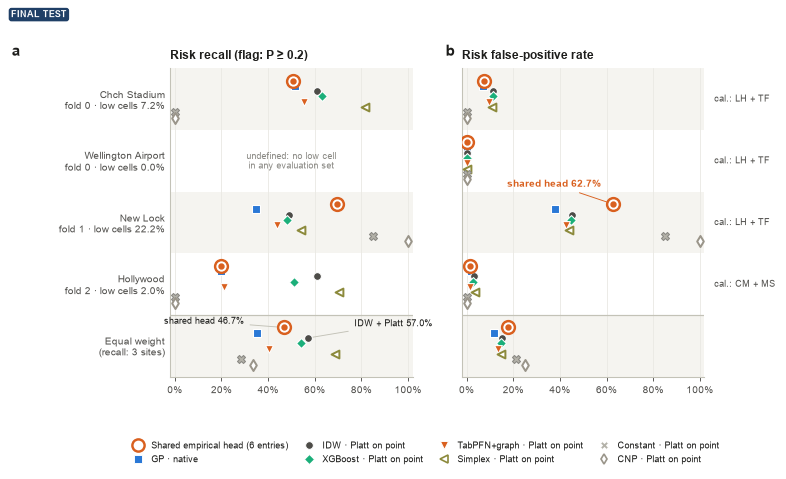

In [23]:
RS = [("balanced", "Shared empirical head (6 entries)"), ("gp", "GP · native"), ("idw", "IDW · Platt on point"),
      ("xgb", "XGBoost · Platt on point"), ("tabpfn_graph", "TabPFN+graph · Platt on point"), ("simplex", "Simplex · Platt on point"),
      ("constant", "Constant · Platt on point"), ("cnp", "CNP · Platt on point")]
assert all(np.allclose(TSITE_T.loc[m, ["risk_recall", "risk_fpr"]].to_numpy(), TSITE_T.loc["balanced", ["risk_recall", "risk_fpr"]].to_numpy(),
                       equal_nan=True) for m in SHARED_IDS)
assert all(TSITE_T.loc[(m, s), "risk_fpr"] <= .12 for m, _ in RS for s in ("christchurch_stadium", "hollywood"))
ROWS = TEST_SITES + ["equal"]
offs = np.linspace(-.3, .3, len(RS))
def rmark(ax, x, y, m):
    if m == "balanced":
        ax.scatter(x, y, s=70, facecolor="white", edgecolor=COL["tabpfn_graph"], lw=1.6, zorder=6)
        ax.scatter(x, y, s=10, color=COL["tabpfn_graph"], zorder=7)
    else:
        mscatter(ax, x, y, m, s=26, z=5)
fig = plt.figure(figsize=(W, 108 * MM))
axs = [fig.add_axes([.215, .2, .32, .66]), fig.add_axes([.6, .2, .32, .66])]
for k, (ax, col, title) in enumerate(zip(axs, ["risk_recall", "risk_fpr"], ["Risk recall (flag: P ≥ 0.2)", "Risk false-positive rate"])):
    for i, row in enumerate(ROWS):
        if i % 2 == 0: ax.axhspan(i - .5, i + .5, color=SOFT, lw=0, zorder=0)
        for (m, _), o_ in zip(RS, offs):
            v = TMACRO.loc[m, col] if row == "equal" else TSITE_T.loc[(m, row), col]
            if np.isnan(v): continue
            rmark(ax, v, i + o_, m)
    ax.axhline(len(TEST_SITES) - .5, color=AXIS, lw=.8)
    ax.set_xlim(-.02, 1.02); ax.set_ylim(len(ROWS) - .5, -.5); hgrid(ax, "x")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.tick_params(axis="x", labelsize=6.4)
    ax.set_title(title, loc="left", fontsize=7.6, fontweight="bold", pad=6)
    label(ax, "ab"[k], x=-.03 if k else -.62, y=1.03)
    if k == 0:
        ax.set_yticks(range(len(ROWS)), [f"{TSITE[s]}\nfold {TFOLD[s]} · low cells {100*LOWSHARE[s]:.1f}%" for s in TEST_SITES]
                      + ["Equal weight\n(recall: 3 sites)"], fontsize=6.3, linespacing=1.2)
        ai = ROWS.index("wellington_airport")
        ax.text(.5, ai, "undefined: no low cell\nin any evaluation set", ha="center", va="center", fontsize=6.1, color=MUTED, linespacing=1.2)
    else:
        ax.set_yticks(range(len(ROWS)), [])
        for i, s in enumerate(TEST_SITES):
            ax.text(1.04, i, "cal.: " + " + ".join(SITE[c][0] for c in sorted(CALS[TFOLD[s]])), transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
                    fontsize=5.9, color=INK2, va="center")
    ax.tick_params(axis="y", length=0)
nl = ROWS.index("newlock")
v = TSITE_T.loc[("balanced", "newlock"), "risk_fpr"]
axs[1].annotate(f"shared head {100*v:.1f}%", (v, nl + offs[0]), xytext=(v - .05, nl - .62), fontsize=6.3, color=COL["tabpfn_graph"],
                fontweight="bold", ha="right", va="center", arrowprops=dict(arrowstyle="-", color=COL["tabpfn_graph"], lw=.6))
ei = ROWS.index("equal")
for m, dy, dx, ha in [("balanced", -.4, -.17, "right"), ("idw", -.36, .2, "left")]:
    v = TMACRO.loc[m, "risk_recall"]; o_ = offs[[r[0] for r in RS].index(m)]
    axs[0].annotate(f"{'shared head' if m == 'balanced' else 'IDW + Platt'} {100*v:.1f}%", (v, ei + o_), xytext=(v + dx, ei + dy),
                    fontsize=6.2, color=INK, ha=ha, va="center", arrowprops=dict(arrowstyle="-", color=AXIS, lw=.6))
h = []
for m, lab in RS:
    if m == "balanced":
        h.append(Line2D([], [], ls="", marker="o", ms=8, mfc="white", mec=COL["tabpfn_graph"], mew=1.6, label=lab))
    else:
        h.append(mhandle(m, ms=5, label=lab))
fig.legend(handles=h, loc="lower center", ncol=4, bbox_to_anchor=(.55, -.005), fontsize=6.2, columnspacing=1.2, handletextpad=.4)
tierbadge(axs[0], .005, .965, "test", transform=fig.transFigure)
save(fig, "fig17_test_risk_transfer"); plt.show()
RT = pd.DataFrame({f"{TSITE[s]} {c}": [100 * TSITE_T.loc[(m, s), c] for m, _ in RS] for s in TEST_SITES for c in ("risk_recall", "risk_fpr")},
                  index=[lab for _, lab in RS])
RT["equal-weight risk recall"] = [100 * TMACRO.loc[m, "risk_recall"] for m, _ in RS]
RT["equal-weight risk FPR"] = [100 * TMACRO.loc[m, "risk_fpr"] for m, _ in RS]
display(RT.round(1))

**Caption.** *Fig. 17. FINAL TEST transfer of the risk flags. Calibrators were fitted on two validation sites per fold and applied unchanged. At Chch Stadium and Hollywood all sources flag few cells (risk FPR ≤ 12%). At New Lock, where 22% of the evaluation cells are low, the fold-1 calibration (Lower Hutt + Tauranga) makes the shared empirical head flag 62.7% of the non-low cells; the Constant and CNP flags mark almost all of New Lock (85% and 100%). Over the three sites where recall is defined, the shared head's risk recall (46.7%) is below that of the simple IDW + Platt flag (57.0%) and Simplex + Platt (68.7%). The shared risk head therefore transfers poorly to New Lock; risk flags need site-level recalibration before use.*

## 6 · 取舍与讨论

### 图 18 · 剖面误差与厚度误差的 Pareto 前沿：验证与测试

左下更好。阶梯线连接在两项指标上都不被其他入口支配的入口；灰色区域表示两项都优于同一层的 IDW。两个面板各用自己的坐标范围（两层的绝对误差不可比），比较的是入口的相对位置。

VALIDATION Pareto: ['tabpfn_joint', 'balanced', 'thickness', 'count_shrink', 'thickness_guarded'] · FINAL TEST Pareto: ['balanced', 'thickness', 'count_shrink', 'thickness_guarded']


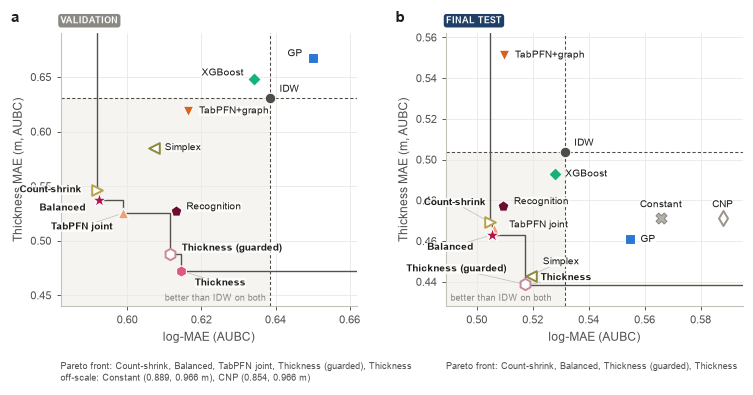

In [24]:
def pareto_of(MAC):
    pts = MAC[["log_mae", "h_point_mae_m"]]
    return [m for m in MODELS if not any((pts.loc[o] <= pts.loc[m]).all() and (pts.loc[o] < pts.loc[m]).any() for o in MODELS if o != m)]
def pareto_panel(ax, MAC, xl, yl, offs, shade_right=True):
    pts = MAC[["log_mae", "h_point_mae_m"]]; par = pareto_of(MAC)
    ix, iy = pts.loc["idw"]
    ax.add_patch(Rectangle((xl[0], yl[0]), ix - xl[0], iy - yl[0], fc=SOFT, ec="none", zorder=0))
    ax.axvline(ix, color=COL["idw"], lw=.7, ls=(0, (3, 2))); ax.axhline(iy, color=COL["idw"], lw=.7, ls=(0, (3, 2)))
    ax.text(ix - (xl[1] - xl[0]) * .015 if shade_right else xl[0] + (xl[1] - xl[0]) * .015, yl[0] + (yl[1] - yl[0]) * .02,
            "better than IDW on both", fontsize=6.1, color=MUTED, ha="right" if shade_right else "left")
    pf = pts.loc[par].sort_values("log_mae")
    sx, sy = [pf.log_mae.iloc[0]], [yl[1]]
    for (xa, ya) in pf.to_numpy():
        sx += [xa, xa]; sy += [sy[-1], ya]
    sx.append(xl[1]); sy.append(sy[-1])
    ax.plot(sx, sy, color=INK2, lw=.9, zorder=2)
    off = []
    for m in MODELS:
        x_, y_ = pts.loc[m]
        if x_ > xl[1] or y_ > yl[1]: off.append(m); continue
        mscatter(ax, x_, y_, m, s=48, z=5)
        o_ = offs.get(m, (7, 0)); dx, dy = o_[:2]
        ha = o_[2] if len(o_) > 2 else ("left" if dx >= 0 else "right")
        ax.annotate(SHORT[m], (x_, y_), xytext=(dx, dy), textcoords="offset points", fontsize=6.3,
                    ha=ha, va="center", fontweight="bold" if m in par else "normal", bbox=dict(fc="white", ec="none", pad=.2, alpha=.75),
                    arrowprops=dict(arrowstyle="-", color=AXIS, lw=.5, shrinkA=0, shrinkB=3) if abs(dx) + abs(dy) > 14 else None)
    ax.set_xlim(*xl); ax.set_ylim(*yl); hgrid(ax, "both")
    ax.set_xlabel("log-MAE (AUBC)"); ax.set_ylabel("Thickness MAE (m, AUBC)")
    txt = "Pareto front: " + ", ".join(SHORT[m] for m in pf.index)
    if off: txt += "\noff-scale: " + ", ".join(f"{SHORT[m]} ({pts.loc[m,'log_mae']:.3f}, {pts.loc[m,'h_point_mae_m']:.3f} m)" for m in off)
    ax.text(0, -.2, txt, transform=ax.transAxes, fontsize=6.0, color=INK2, va="top", linespacing=1.35)
    return par

PV, PTt = pareto_of(MACRO), pareto_of(TMACRO)
assert set(PV) == {"count_shrink", "balanced", "tabpfn_joint", "thickness_guarded", "thickness"}
assert set(PTt) == {"count_shrink", "balanced", "thickness_guarded", "thickness"}
fig, axs = plt.subplots(1, 2, figsize=(W, 100 * MM), gridspec_kw=dict(wspace=.3))
OFF_V = {"count_shrink": (-10, 0), "balanced": (-9, -5), "tabpfn_joint": (-7, -9), "thickness_guarded": (8, 4), "thickness": (9, -8),
         "recognition": (7, 3), "simplex": (7, 0), "tabpfn_graph": (7, 0), "xgb": (-7, 4), "idw": (6, 6), "gp": (-7, 3)}
OFF_T = {"count_shrink": (-3, 13, "right"), "balanced": (-12, -8), "tabpfn_joint": (10, 3), "recognition": (7, 3), "tabpfn_graph": (7, 0),
         "thickness_guarded": (-12, 10), "thickness": (10, 5), "simplex": (8, 9), "xgb": (7, 0), "idw": (6, 6), "gp": (7, 0),
         "constant": (0, 9, "center"), "cnp": (0, 9, "center")}
pareto_panel(axs[0], MACRO, (.582, .662), (.44, .69), OFF_V)
pareto_panel(axs[1], TMACRO, (.489, .595), (.428, .562), OFF_T, shade_right=False)
for ax, l, t in zip(axs, "ab", ["val", "test"]):
    label(ax, l, x=-.14, y=1.03); tierbadge(ax, 0, 1.03, t)
fig.subplots_adjust(top=.9, bottom=.27, left=.08, right=.98)
save(fig, "fig18_pareto_val_test"); plt.show()
print("VALIDATION Pareto:", PV, "· FINAL TEST Pareto:", PTt)

**Caption.** *Fig. 18. Trade-off between profile error and thickness error. (a) VALIDATION: Count-shrink, Balanced, TabPFN joint, Thickness (FPR-guarded) and Thickness form the Pareto front. (b) FINAL TEST: the same front without TabPFN joint, which Balanced now dominates by small margins; Thickness and its guarded variant are practically the same point. In both tiers the entries split into a profile group (Count-shrink, Balanced, TabPFN joint) and a thickness group (Thickness, guarded, Simplex), so no single entry is best on both objectives. On the test sites GP, the Constant median and CNP have lower thickness error than IDW but much higher log-MAE.*

### 图 19 · 低值识别：点召回与点误报率（验证与测试）

点决策为 q̂c < 1 MPa。虚线为同一层的 IDW，点线为同一层的点 FPR 护栏（IDW + 2 pp）。测试层召回只来自 3 个场地。

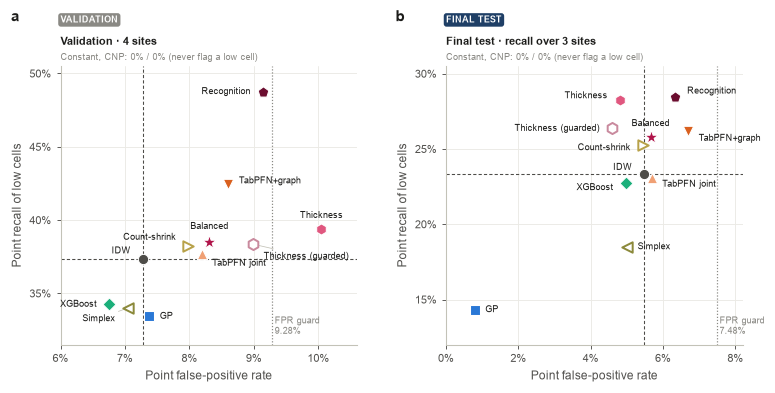

In [25]:
def recall_panel(ax, MAC, guard, xl, yl, offs, title):
    R_ = MAC[["recall", "false_positive_rate"]]
    ax.axvline(R_.loc["idw", "false_positive_rate"], color=COL["idw"], lw=.7, ls=(0, (3, 2)))
    ax.axhline(R_.loc["idw", "recall"], color=COL["idw"], lw=.7, ls=(0, (3, 2)))
    ax.axvline(guard, color=MUTED, lw=.8, ls=(0, (1, 1.5)))
    ax.text(guard + (xl[1] - xl[0]) * .01, yl[0] + (yl[1] - yl[0]) * .03, f"FPR guard\n{100*guard:.2f}%", fontsize=5.9, color=MUTED, va="bottom")
    for m in MODELS:
        x_, y_ = R_.loc[m, "false_positive_rate"], R_.loc[m, "recall"]
        if y_ <= 0: continue
        mscatter(ax, x_, y_, m, s=46, z=5)
        o_ = offs.get(m, (7, 0)); dx, dy = o_[:2]
        ha = o_[2] if len(o_) > 2 else ("left" if dx >= 0 else "right")
        ax.annotate(SHORT[m], (x_, y_), xytext=(dx, dy), textcoords="offset points", fontsize=6.2,
                    ha=ha, va="center",
                    arrowprops=dict(arrowstyle="-", color=AXIS, lw=.5, shrinkA=0, shrinkB=3) if abs(dx) + abs(dy) > 14 else None)
    ax.set_xlim(*xl); ax.set_ylim(*yl); hgrid(ax, "both")
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(.05)); ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(.01 if xl[0] > 0 else .02))
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    ax.set_xlabel("Point false-positive rate"); ax.set_ylabel("Point recall of low cells")
    ax.set_title(title, loc="left", fontsize=7.4, fontweight="bold", pad=14)
fig, axs = plt.subplots(1, 2, figsize=(W, 96 * MM), gridspec_kw=dict(wspace=.3))
OR_V = {"recognition": (-8, 0), "tabpfn_graph": (7, 2), "thickness": (0, 9, "center"), "balanced": (0, 10, "center"),
        "thickness_guarded": (7, -8), "count_shrink": (-8, 6), "tabpfn_joint": (7, -6), "idw": (-8, 5), "gp": (7, 0),
        "xgb": (-8, 0), "simplex": (-8, -7)}
OR_T = {"recognition": (8, 4), "thickness": (-8, 3), "thickness_guarded": (-8, 0), "tabpfn_graph": (7, -5), "balanced": (0, 9, "center"),
        "count_shrink": (-8, -2), "idw": (-8, 4), "tabpfn_joint": (7, -4), "xgb": (-8, -3), "simplex": (7, 0), "gp": (7, 0)}
recall_panel(axs[0], MACRO, GUARD, (.06, .106), (.315, .505), OR_V, "Validation · 4 sites")
assert TMACRO.false_positive_rate.max() <= TGUARD and TMACRO.false_positive_rate.drop(["constant", "cnp"]).idxmin() == "gp"
recall_panel(axs[1], TMACRO, TGUARD, (0, .082), (.12, .305), OR_T, "Final test · recall over 3 sites")
for ax, l, t in zip(axs, "ab", ["val", "test"]):
    label(ax, l, x=-.14, y=1.15); tierbadge(ax, 0, 1.15, t)
    ax.text(0, 1.015, "Constant, CNP: 0% / 0% (never flag a low cell)", transform=ax.transAxes, fontsize=5.9, color=MUTED, va="bottom")
fig.subplots_adjust(top=.8, bottom=.13, left=.08, right=.98)
save(fig, "fig19_recall_fpr_val_test"); plt.show()

**Caption.** *Fig. 19. Point recall against point false-positive rate. (a) VALIDATION: Recognition raises recall from 37.4% (IDW) to 48.8% at a false-positive rate of 9.1% (IDW 7.3%); Thickness is the only entry beyond the validation guard (10.05% > 9.28%). (b) FINAL TEST: Recognition again has the highest recall (28.4% vs 23.4%) at +0.85 pp FPR, and Thickness (28.2%) is close behind with a lower FPR than IDW; every entry is inside the test guard (7.48%), and GP is the most conservative entry that flags any low cell (FPR 0.8%, recall 14.3%). Recall trades against false alarms in both tiers, so Recognition is an explicit operating point, not a free gain. Risk flags (calibrated P ≥ 0.2) are a different operating point; see Table 1 and Fig. 17.*

### 图 20 · 场地层面：验证场地上相对 IDW 的收益与代价

格内数字为该入口在该验证场地的 AUBC 数值，颜色为相对 IDW 的变化；顶行是 IDW 自身的数值。黑框标出 Balanced 在验证上的两处局部代价。测试场地的同类图见图 13。

VALIDATION · Lower Hutt thickness MAE IDW → Balanced: 0.133 → 0.254 m
VALIDATION · Marshland point recall %: {'idw': np.float64(22.79), 'balanced': np.float64(5.15), 'recognition': np.float64(30.0), 'tabpfn_graph': np.float64(31.03)}; point FPR %: {'idw': np.float64(4.49), 'balanced': np.float64(0.93), 'recognition': np.float64(3.12)}
VALIDATION · Tauranga log-MAE, best three: {'tabpfn_joint': 0.5714, 'constant': 0.5739, 'tabpfn_graph': 0.5788}


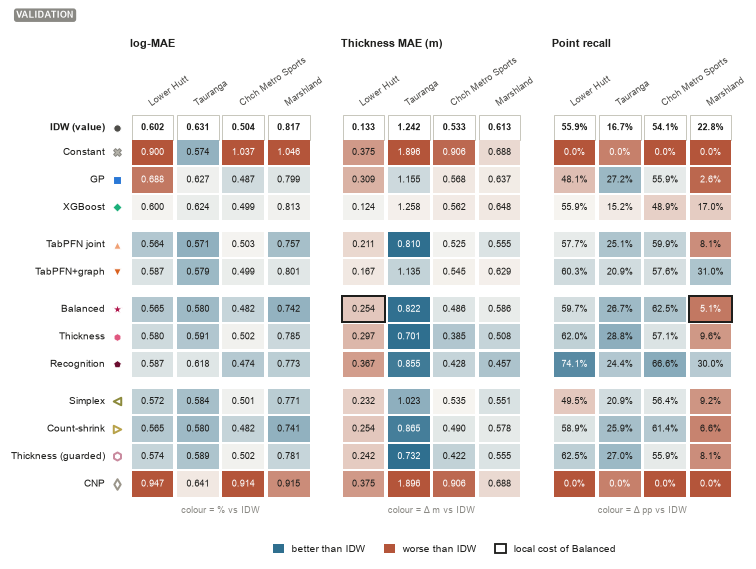

In [26]:
HM_V = [("log_mae", "log-MAE", "{:.3f}", lambda v, r: 100 * (v / r - 1), "% vs IDW", True),
        ("h_point_mae_m", "Thickness MAE (m)", "{:.3f}", lambda v, r: v - r, "Δ m vs IDW", True),
        ("recall", "Point recall", "{:.1%}", lambda v, r: 100 * (v - r), "Δ pp vs IDW", False)]
FR_V = [("balanced", "lower_hutt_town_hall", "h_point_mae_m"), ("balanced", "marshland", "recall")]
site_heat(SITE_T, VAL_SITES, HM_V, FR_V, "val", "fig20_validation_sites", "local cost of Balanced", fh=128)
plt.show()
TF, MS, LH = "tauranga_farmers_building", "marshland", "lower_hutt_town_hall"
lh = SITE_T.loc[[("idw", LH), ("balanced", LH)], "h_point_mae_m"].round(3).to_numpy()
ms_r = {m: round(100 * SITE_T.loc[(m, MS), "recall"], 2) for m in ["idw", "balanced", "recognition", "tabpfn_graph"]}
ms_f = {m: round(100 * SITE_T.loc[(m, MS), "false_positive_rate"], 2) for m in ["idw", "balanced", "recognition"]}
tf_rank = SITE_T.xs(TF, level="site_id").log_mae.sort_values()
assert tuple(lh) == (0.133, 0.254) and ms_r["balanced"] == 5.15 and ms_r["recognition"] == 30.0
assert ms_f["balanced"] < ms_f["recognition"] < ms_f["idw"]
assert list(tf_rank.index[:2]) == ["tabpfn_joint", "constant"] and tf_rank["constant"] < tf_rank["idw"]
print(f"VALIDATION · Lower Hutt thickness MAE IDW → Balanced: {lh[0]} → {lh[1]} m")
print(f"VALIDATION · Marshland point recall %: {ms_r}; point FPR %: {ms_f}")
print("VALIDATION · Tauranga log-MAE, best three:", tf_rank.head(3).round(4).to_dict())

**Caption.** *Fig. 20. VALIDATION site-level gains and costs relative to IDW. Macro improvements hide local losses. At Lower Hutt Balanced nearly doubles IDW's small thickness error (0.133 → 0.254 m); at Marshland its point recall falls from 22.8% to 5.1%, where Recognition recovers 30.0%. At Tauranga the Constant median beats IDW and all entries except TabPFN joint on log-MAE. The final test shows the same pattern at New Lock, where the Constant median and CNP beat every spatial model (Fig. 13): simple site-level baselines remain competitive at sites with little spatial structure.*

### 图 21 · 精度与推断耗时（v0.9.1 统一基准）

13 个入口都按同一个协议实测：12 个状态（8 组不同输入），每个状态 1 次预热加 3 次计时，进程固定在逻辑核 2、单线程，频率未锁定。完整路径包含原生风险头或共享风险头（校准前的概率），不含评价时的 Platt 校准。

设备差异：标记外有灰圈的入口，其 TabPFN 组件在 CUDA（RTX 4080）上运行，其余计算仍在固定的 CPU 核上；**CPU 行与 CUDA 行不是同条件比较**。(c) 中的短竖线是有独立风险头的 6 个入口的纯点路径（`--point-only`，全部在 CPU 上）。TabPFN 在 CPU 上与 CUDA 参考**数值上不等价**。(a)(b) 的纵轴是**验证**误差。

,device,total_ms_median,total_ms_p95,initialization_ms_median,matches_reference
model_id,,,,,
Constant median,cpu,2.6,2.7,2.9,True
IDW (3NN),cpu,6.8,7.2,2.9,True
GP,cpu,74.5,197.1,3.4,True
XGBoost residual,cpu,83.4,110.1,4.4,True
TabPFN joint,cuda,169.1,202.6,75.5,True
TabPFN + graph low-union,cuda,136.4,162.1,67.1,True
Balanced,cuda,183.2,202.4,70.2,True
"Thickness (Haar, nearest)",cuda,151.2,176.7,66.9,True
Recognition (recall-60),cuda,186.2,197.9,64.1,True


,device,total_ms_median,total_ms_p95,max_point_difference,label_changes,matches_reference
model_id,,,,,,
TabPFN joint,cpu,1857.171,2750.971,0.33,1,False
Balanced,cpu,37.122,44.488,0.00,0,True
"Thickness (Haar, nearest)",cpu,9.939,10.909,0.00,0,True
Recognition (recall-60),cpu,39.572,48.536,0.00,0,True
Count-shrink,cpu,197.449,268.845,0.00,0,True
Thickness (FPR-guarded),cpu,10.274,11.534,0.00,0,True


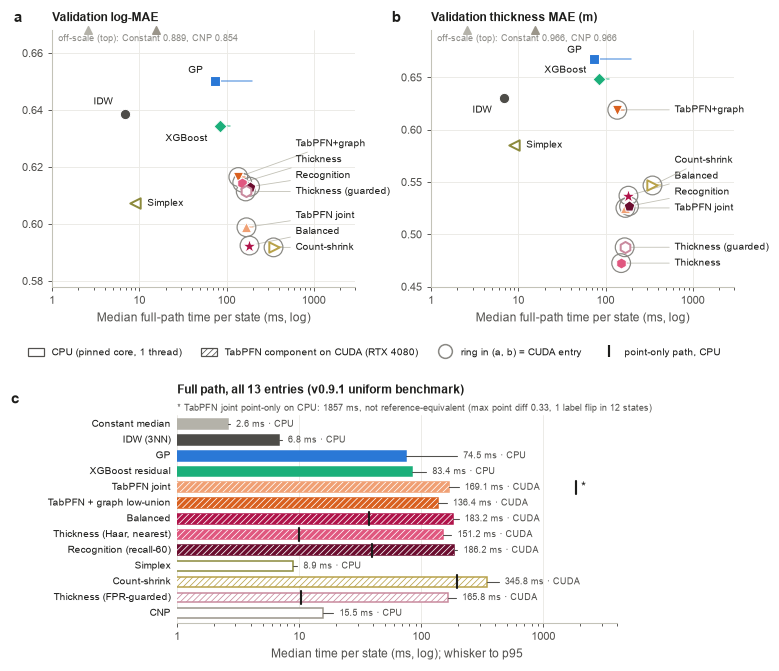

In [27]:
RTM = RTF[["total_ms_median", "total_ms_p95", "device"]].rename(columns={"total_ms_median": "ms", "total_ms_p95": "p95"})
CUDA = [m for m in MODELS if RTM.loc[m, "device"] == "cuda"]
assert set(CUDA) == {"tabpfn_joint", "tabpfn_graph", "balanced", "thickness", "recognition", "count_shrink", "thickness_guarded"}

def spread(vals, gap, lo, hi):
    order = np.argsort(vals); v = np.asarray(vals, float)[order].copy()
    for i in range(1, len(v)):
        v[i] = max(v[i], v[i - 1] + gap)
    v -= max(0, v[-1] - hi)
    for i in range(len(v) - 2, -1, -1):
        v[i] = min(v[i], v[i + 1] - gap)
    v += max(0, lo - v[0])
    out = np.empty_like(v); out[order] = v
    return out

fig = plt.figure(figsize=(W, 160 * MM))
MAN = [{"idw": (-8, 8), "gp": (-8, 7), "xgb": (-8, -8), "simplex": (8, 0)},
       {"idw": (-8, -8), "gp": (-8, 6), "xgb": (-8, 6), "simplex": (8, 0)}]
for k, (col, ylab, yl) in enumerate([("log_mae", "Validation log-MAE", (.578, .668)), ("h_point_mae_m", "Validation thickness MAE (m)", (.45, .695))]):
    ax = fig.add_axes([.075 + k * .5, .57, .4, .37])
    off = []
    for m in MODELS:
        r = RTM.loc[m]; v = MACRO.loc[m, col]
        if v > yl[1]:
            ax.scatter(r.ms, yl[1], marker="^", s=24, color=COL[m], clip_on=False, zorder=5); off.append(m)
            continue
        ax.plot([r.ms, r.p95], [v, v], color=COL[m], lw=1, alpha=.6, zorder=2)
        if r.device == "cuda":
            ax.scatter(r.ms, v, s=150, facecolor="none", edgecolor=MUTED, lw=.8, zorder=4)
        mscatter(ax, r.ms, v, m, s=46, z=5)
        if m in MAN[k]:
            dx, dy = MAN[k][m]
            ax.annotate(SHORT[m], (r.ms, v), xytext=(dx, dy), textcoords="offset points", fontsize=6.3,
                        ha="left" if dx > 0 else "right", va="center")
    crowd = [m for m in CUDA if MACRO.loc[m, col] <= yl[1]]
    ys = spread([MACRO.loc[m, col] for m in crowd], (yl[1] - yl[0]) * .062, yl[0] + .004, yl[1] - .004)
    for m, yt in zip(crowd, ys):
        tag(ax, RTM.loc[m, "ms"], MACRO.loc[m, col], SHORT[m], 620, yt, ha="left", fs=6.3)
    ax.text(.02, .985, "off-scale (top): " + ", ".join(f"{SHORT[m]} {MACRO.loc[m, col]:.3f}" for m in off),
            transform=ax.transAxes, fontsize=6.0, color=MUTED, va="top")
    ax.set_xscale("log"); ax.set_xlim(1, 3000); ax.set_ylim(*yl); hgrid(ax, "both")
    ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1000"])
    ax.set_xlabel("Median full-path time per state (ms, log)"); ax.set_title(ylab, loc="left", fontsize=7.6, fontweight="bold")
    label(ax, "ab"[k], x=-.1, y=1.02)
c = fig.add_axes([.24, .085, .58, .3])
yc = {m: i for i, m in enumerate(MODELS)}
for m in MODELS:
    r = RTM.loc[m]
    c.barh(yc[m], r.ms, height=.62, color=COL[m] if m not in DISC else "white", edgecolor=COL[m], lw=1.0,
           hatch="//////" if (r.device == "cuda" and m in DISC) else None, zorder=2)
    if r.device == "cuda" and m not in DISC:
        c.barh(yc[m], r.ms, height=.62, fc="none", edgecolor="white", lw=0, hatch="//////", zorder=2.5)
    c.plot([r.ms, r.p95], [yc[m], yc[m]], color=INK2, lw=.7, zorder=3)
    c.text(r.p95 * 1.12, yc[m], f"{r.ms:.1f} ms" + (" · CUDA" if r.device == "cuda" else " · CPU"), va="center", fontsize=6.0, color=INK2)
    c.text(-.015, yc[m], NAME[m], ha="right", va="center", fontsize=6.4, color=INK, transform=c.get_yaxis_transform())
for m, r in RTP.iterrows():
    c.plot([r.total_ms_median] * 2, [yc[m] - .42, yc[m] + .42], color=INK, lw=1.4, zorder=4)
tj = RTP.loc["tabpfn_joint"]
c.text(tj.total_ms_median * 1.1, yc["tabpfn_joint"], "*", fontsize=8, color=INK, va="center")
c.set_xscale("log"); c.set_xlim(1, 4000); c.set_ylim(len(MODELS) - .4, -.6)
c.set_yticks([]); c.spines["left"].set_visible(False); hgrid(c, "x")
c.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1000"]); c.set_xlabel("Median time per state (ms, log); whisker to p95")
c.set_title("Full path, all 13 entries (v0.9.1 uniform benchmark)", loc="left", fontsize=7.6, fontweight="bold", pad=14)
c.text(0, 1.01, f"* TabPFN joint point-only on CPU: {tj.total_ms_median:.0f} ms, not reference-equivalent "
       f"(max point diff {tj.max_point_difference:.2f}, {int(tj.label_changes)} label flip in 12 states)",
       transform=c.transAxes, fontsize=6.0, color=INK2, va="bottom")
label(c, "c", x=-.36, y=1.04)
fig.legend(handles=[Rectangle((0, 0), 1, 1, fc="white", ec=INK2, lw=.8, label="CPU (pinned core, 1 thread)"),
                    Rectangle((0, 0), 1, 1, fc="white", ec=INK2, lw=.8, hatch="//////", label="TabPFN component on CUDA (RTX 4080)"),
                    Line2D([], [], ls="", marker="o", ms=9, mfc="none", mec=MUTED, label="ring in (a, b) = CUDA entry"),
                    Line2D([], [], color=INK, lw=1.4, marker="|", ls="", ms=8, mew=1.4, label="point-only path, CPU")],
           loc="center", ncol=4, bbox_to_anchor=(.5, .475), fontsize=6.4, handlelength=1.6, handleheight=1)
save(fig, "fig21_runtime"); plt.show()
display(RTF[["device", "total_ms_median", "total_ms_p95", "initialization_ms_median", "matches_reference"]].rename(index=NAME).round(1))
display(RTP[["device", "total_ms_median", "total_ms_p95", "max_point_difference", "label_changes", "matches_reference"]].rename(index=NAME).round(3))

**Caption.** *Fig. 21. Accuracy (VALIDATION) against measured inference time for all thirteen entries (v0.9.1 uniform benchmark: 12 states, 1 warm-up + 3 timed repeats, pinned logical core, single thread, frequency not locked; median, whisker to p95). The full path includes the native or shared risk head (pre-calibration probability) but not the evaluation-time Platt calibration. Hatched bars and ringed markers run the TabPFN component on CUDA (RTX 4080), the rest on the pinned CPU core, so CPU and CUDA rows are not like-for-like. Balanced takes 183 ms per state against 6.8 ms for IDW; Count-shrink takes 346 ms (1.89× Balanced) for a log-MAE that differs from Balanced's by less than 0.001 in both tiers. TabPFN on CPU is not reference-equivalent: the TabPFN joint point-only path takes 1.86 s per state and differs from the CUDA reference by up to 0.33 in ln qc (one label flip in 12 states).*

### 讨论

- **剖面重建**：Count-shrink、Balanced、TabPFN joint 在两层都是 log-MAE 前三，测试上相对 IDW 低约 0.026（在 4 个场地中的 3 个更好）。Count-shrink 与 Balanced 之差在两层都小于 0.001，而 Count-shrink 耗时约为 1.89 倍，所以 Balanced 是默认方案。
- **厚度**：Thickness 与护栏版在两层都是厚度前二，在测试上对 IDW 是"一致改进"，点 FPR 也在测试护栏内；两者在测试上几乎相同（差 0.5 mm）。厚度结论主要由 New Lock 决定，而常数中位数的厚度 MAE 也低于 IDW，说明"从不预测低值"在低值稀少的场地上是强基线。
- **识别**：Recognition 在两层都有最高的点召回，但召回提高是"仅均值改进"，误报的增加是"一致变差"（仍在护栏内）。
- **TabPFN**：两个 TabPFN 入口的 log-MAE 都是"一致改进"，但 TabPFN joint 中 TabPFN 只提供一半幅值底座；TabPFN + graph 在测试厚度上排最后。
- **风险旗标**：风险校准只用 2 个验证场地，迁移到 New Lock 时误报很高，需要按场地重新校准。

## 7 · 局限与项目历程

**局限（全部适用于当前结论）**
- **测试场地只有 4 个**，其中 2 个（New Lock、Hollywood）分组未核实；每个测试状态只评 5–16 根 CPT，种子之间不是独立重复。所有测试判定都是描述性的（最小符号检验 p = 0.125）。
- **场地组成决定了测试结论**：Wellington Airport 没有低值单元（召回无定义、厚度误差全为 0）；Hollywood 低值单元极少；厚度与召回的信息主要来自 Chch Stadium 和 New Lock，厚度结论由 New Lock（1.3–1.7 m 误差）主导。
- **验证层带有选择偏差**：13 个入口是在 4 个验证场地上选出的，验证分数偏乐观（见图 22：验证上的领先幅度在测试上缩小）。
- **弱间接通道**：测试场地在其他折中是训练源，那些折的权重参与过验证场地上的选择。
- **风险校准**每折只用 2 个验证场地，迁移到新场地有限（New Lock 风险 FPR 62.7%）。
- **只有 GP 给出区间**，且覆盖不足：名义 90%，验证实际 79.8%，测试 86.5%。
- **耗时不是同条件比较**：7 个入口的 TabPFN 组件在 CUDA 上运行；TabPFN 在 CPU 上与参考不等价。
- **没有证明能少打 CPT**：两层都只评价固定 maximin 揭示序列下的预测质量，不评价选点策略。

### 图 22 · 项目历程：验证分数随候选增多而变好，独立测试上领先幅度缩小

(a) 项目最早的外层测试（v0.1：8 个场地 × 5 个种子，**另一种协议**），当时没有模型赢过 IDW。

(b) 截至每个版本、在**同一批 4 个验证场地**上比较过的所有配置中的最优值，相对验证 IDW 的变化（log-MAE 0.638586、厚度 0.630371 m）；v0.2 的模型只以 v0.3 表中的重新评分出现。(c) 各版本 README 中写明的配置数。

(d) 同一批入口相对 IDW 的变化：验证层 → 最终测试层（各自相对本层的 IDW）。

In [28]:
def git_csv(tag, path):
    out = subprocess.run(["git", "-C", str(ROOT), "show", f"{tag}:{path}"], capture_output=True, check=True).stdout
    return pd.read_csv(io.BytesIO(out))

HIST = [("v0.3", "v0.3-diagnostics", "results/diagnostics-20261014/comparison/unique_site_macro.csv"),
        ("v0.4", "v0.4-residual", "results/v4-residual-20261014/comparison/unique_site_macro.csv"),
        ("v0.5", "v0.5-exploration", "results/v5-exploration-20261014/comparison/all_model_ranking.csv"),
        ("v0.6", "v0.6-combinations", "results/v6-combinations-20261014/final/all_model_ranking.csv"),
        ("v0.7", "v0.7-discovery", "results/v7-discovery-20261014/comparison/all_model_ranking.csv"),
        ("v0.8", "v0.8-engineering", "results/v8-engineering-20261014/comparison/all_model_ranking.csv")]
VERS = ["v0.2", "v0.3", "v0.4", "v0.5", "v0.6", "v0.7", "v0.8"]
README_N = {"v0.2": 6, "v0.3": 15, "v0.4": 23, "v0.5": 32, "v0.6": 90, "v0.7": 183, "v0.8": 203}   # tagged READMEs
REFS = {"idw", "gp", "target_constant_median"}
IDW_VAL = MACRO.loc["idw", "log_mae"]; IDW_H = MACRO.loc["idw", "h_point_mae_m"]
try:
    tables = {v: git_csv(t, p) for v, t, p in HIST}
    MASTER = tables["v0.8"].set_index("model_id")
    for v, d in tables.items():
        sh = d[d.model_id.isin(MASTER.index)].set_index("model_id")
        assert np.allclose(sh[["log_mae", "h_point_mae_m"]], MASTER.loc[sh.index, ["log_mae", "h_point_mae_m"]], atol=1e-12), v
    v2_ids = set(git_csv("v0.2-validation", "results/v2-validation-20261013/model_validation_macro.csv").model_id)
    tables["v0.2"] = tables["v0.3"][tables["v0.3"].model_id.isin(v2_ids)]
    pool, rows = pd.DataFrame(), []
    for v in VERS:
        pool = pd.concat([pool, tables[v][~tables[v].model_id.isin(REFS)]]).drop_duplicates("model_id", keep="last").reset_index(drop=True)
        rows.append(dict(version=v, n_configs=README_N[v], best_log=pool.log_mae.min(), best_h=pool.h_point_mae_m.min()))
    EVO = pd.DataFrame(rows)
    T01 = git_csv("v0.1-results", "results/main-20261013/budget_curve_macro.csv")
    HIST_SOURCE = "git tags v0.1-results … v0.8-engineering"
except Exception as exc:
    print("git unavailable, using recorded historic values:", exc)
    EVO = pd.DataFrame(dict(version=VERS, n_configs=[README_N[v] for v in VERS],
                            best_log=[0.635885, 0.627008, 0.620528, 0.620528, 0.610703, 0.592435, 0.591791],
                            best_h=[0.642090, 0.630371, 0.630371, 0.595215, 0.552246, 0.472493, 0.472493]))
    T01 = pd.DataFrame(dict(model_id=["gp", "gp", "gp", "idw", "tabpfn", "tabpfn", "tabpfn", "tabpfn_finetuned",
                                      "tabpfn_finetuned", "tabpfn_finetuned", "xgb"],
                            policy_id=["maximin", "threshold_uncertainty", "uncertainty", "maximin", "maximin",
                                       "threshold_uncertainty", "uncertainty", "maximin", "threshold_uncertainty",
                                       "uncertainty", "maximin"],
                            aubc_log_mae=[0.590550, 0.593122, 0.591014, 0.573812, 0.661242, 0.641554, 0.644221,
                                          0.612189, 0.601231, 0.591034, 0.643504]))
    HIST_SOURCE = "recorded values"
cur_pool = MACRO.drop(["idw", "gp", "constant"])
EVO = pd.concat([EVO, pd.DataFrame([dict(version="v0.9.1", n_configs=len(MODELS), best_log=cur_pool.log_mae.min(),
                                         best_h=cur_pool.h_point_mae_m.min())])], ignore_index=True)
EVO["d_log_vs_idw_pct"] = 100 * (EVO.best_log / IDW_VAL - 1); EVO["d_h_vs_idw_pct"] = 100 * (EVO.best_h / IDW_H - 1)
assert list(EVO.n_configs) == [6, 15, 23, 32, 90, 183, 203, 13]
assert abs(EVO.d_log_vs_idw_pct.iloc[-2] - (-7.33)) < .005 and abs(EVO.d_h_vs_idw_pct.iloc[-2] - (-25.05)) < .005
t01 = T01.set_index(["model_id", "policy_id"]).aubc_log_mae
T01_IDW = t01[("idw", "maximin")]
T01_BEST = (t01.drop(("idw", "maximin")) / T01_IDW - 1).sort_values()
SHRINK = [("count_shrink", "log_mae"), ("balanced", "log_mae"), ("tabpfn_joint", "log_mae"),
          ("thickness", "h_point_mae_m"), ("thickness_guarded", "h_point_mae_m"), ("balanced", "h_point_mae_m")]
SHR = pd.DataFrame([dict(entry=m, metric=c, val=pct(MACRO, m, c), test=pct(TMACRO, m, c)) for m, c in SHRINK])
assert (SHR.test < 0).all() and (SHR.test > SHR.val).all()          # every margin survives but shrinks
print(f"historic source: {HIST_SOURCE}")
print(f"v0.1 outer test (different protocol): IDW AUBC log-MAE {T01_IDW:.4f}; best alternative {T01_BEST.index[0]} {100*T01_BEST.iloc[0]:+.1f}%")
display(EVO.round({"best_log": 6, "best_h": 6, "d_log_vs_idw_pct": 2, "d_h_vs_idw_pct": 2}))
display(SHR.assign(entry=SHR.entry.map(NAME)).round(2))

historic source: git tags v0.1-results … v0.8-engineering
v0.1 outer test (different protocol): IDW AUBC log-MAE 0.5738; best alternative ('gp', 'maximin') +2.9%


,version,n_configs,best_log,best_h,d_log_vs_idw_pct,d_h_vs_idw_pct
0,v0.2,6,0.635885,0.642090,-0.42,1.86
1,v0.3,15,0.627008,0.630371,-1.81,0.00
2,v0.4,23,0.620528,0.630371,-2.83,0.00
3,v0.5,32,0.620528,0.595215,-2.83,-5.58
4,v0.6,90,0.610703,0.552246,-4.37,-12.39
5,v0.7,183,0.592435,0.472493,-7.23,-25.05
6,v0.8,203,0.591791,0.472493,-7.33,-25.05
7,v0.9.1,13,0.591791,0.472493,-7.33,-25.05


,entry,metric,val,test
0,Count-shrink,log_mae,-7.33,-5.02
1,Balanced,log_mae,-7.23,-4.94
2,TabPFN joint,log_mae,-6.22,-4.78
3,"Thickness (Haar, nearest)",h_point_mae_m,-25.05,-12.97
4,Thickness (FPR-guarded),h_point_mae_m,-22.64,-12.86
5,Balanced,h_point_mae_m,-14.82,-8.07


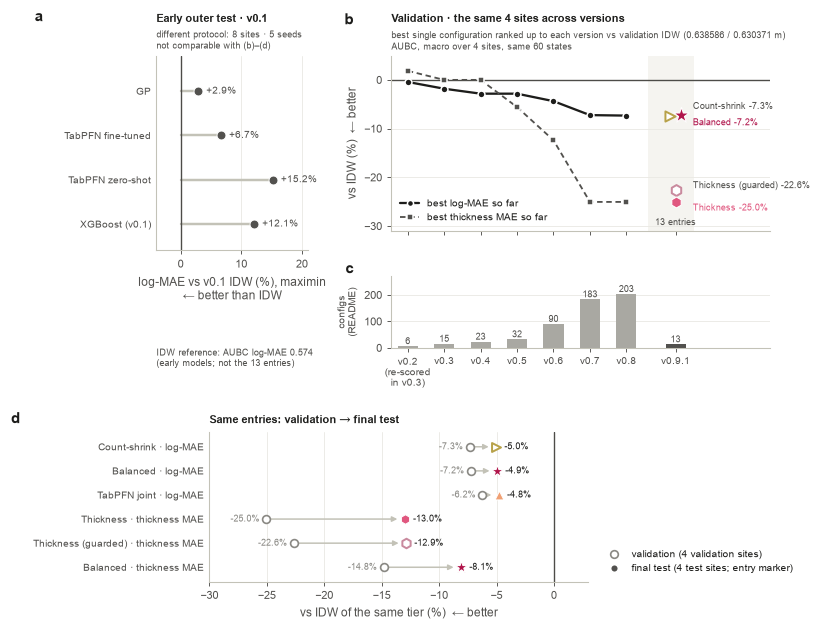

In [29]:
fig = plt.figure(figsize=(W, 150 * MM))
a = fig.add_axes([.17, .58, .2, .3])
T01m = T01[T01.policy_id == "maximin"].set_index("model_id").aubc_log_mae
names01 = {"gp": "GP", "xgb": "XGBoost (v0.1)", "tabpfn": "TabPFN zero-shot", "tabpfn_finetuned": "TabPFN fine-tuned"}
vals = [(names01[m], 100 * (T01m[m] / T01m["idw"] - 1)) for m in ["gp", "tabpfn_finetuned", "tabpfn", "xgb"]]
for i, (nm, v) in enumerate(vals):
    a.plot([0, v], [i, i], color=AXIS, lw=1.6, zorder=1)
    a.scatter(v, i, s=34, color=INK2, edgecolor="white", lw=.6, zorder=3)
    a.text(v + 1.3, i, f"{v:+.1f}%", va="center", fontsize=6.7, color=INK2)
a.axvline(0, color=COL["idw"], lw=.9); a.set_yticks(range(len(vals)), [v[0] for v in vals], fontsize=6.8)
a.set_ylim(len(vals) - .4, -.8); a.set_xlim(-4, 21); hgrid(a, "x"); a.tick_params(axis="y", length=0)
a.set_xlabel("log-MAE vs v0.1 IDW (%), maximin\n← better than IDW")
a.text(0, -.5, f"IDW reference: AUBC log-MAE {T01_IDW:.3f}\n(early models; not the 13 entries)", transform=a.transAxes,
       fontsize=6.2, color=INK2, va="top")
a.set_title("Early outer test · v0.1", loc="left", fontsize=7.4, fontweight="bold", pad=22)
a.text(0, 1.02, "different protocol: 8 sites · 5 seeds\nnot comparable with (b)–(d)", transform=a.transAxes, fontsize=6.2, color=INK2, va="bottom", linespacing=1.25)
label(a, "a", x=-.75, y=1.16)

b = fig.add_axes([.48, .61, .5, .27]); c = fig.add_axes([.48, .43, .5, .11], sharex=b)
EV = EVO[EVO.version != "v0.9.1"]
xv = np.arange(len(EV)); X9 = len(EV) + .35
b.axhline(0, color=COL["idw"], lw=.9)
b.plot(xv, EV.d_log_vs_idw_pct, color=INK, lw=1.5, marker="o", ms=4.5, mec="white", zorder=3)
b.plot(xv, EV.d_h_vs_idw_pct, color=INK2, lw=1.2, ls=(0, (3, 2)), marker="s", ms=4, mec="white", zorder=3)
b.legend(handles=[Line2D([], [], color=INK, lw=1.5, marker="o", ms=4, mec="white", label="best log-MAE so far"),
                  Line2D([], [], color=INK2, lw=1.2, ls=(0, (3, 2)), marker="s", ms=3.6, mec="white", label="best thickness MAE so far")],
         loc="lower left", fontsize=6.3)
RET = [("count_shrink", "log_mae", (8, 6), -.14), ("balanced", "log_mae", (8, -5), .14), ("thickness_guarded", "h_point_mae_m", (8, 3), 0), ("thickness", "h_point_mae_m", (8, -4), 0)]
for m, col, (dx, dy), xo in RET:
    v = pct(MACRO, m, col)
    mscatter(b, X9 + xo, v, m, s=44 if m != "balanced" else 56, z=5)
    b.annotate(f"{SHORT[m]} {v:+.1f}%", (X9 + .14, v), xytext=(dx, dy), textcoords="offset points", fontsize=6.1, va="center",
               color=COL[m] if m not in DISC else INK2)
b.axvspan(len(EV) - .4, X9 + .5, color=SOFT, lw=0, zorder=0)
b.text(X9, -30.2, "13 entries", ha="center", fontsize=6.1, color=INK2, va="bottom")
b.set_ylim(-31, 5); b.set_xlim(-.45, X9 + 2.6); hgrid(b)
b.set_ylabel("vs IDW (%)  ← better"); b.tick_params(labelbottom=False)
b.set_title("Validation · the same 4 sites across versions", loc="left", fontsize=7.4, fontweight="bold", pad=22)
b.text(0, 1.02, "best single configuration ranked up to each version vs validation IDW (0.638586 / 0.630371 m)\nAUBC, macro over 4 sites, same 60 states",
       transform=b.transAxes, fontsize=6.1, color=INK2, va="bottom", linespacing=1.25)
label(b, "b", x=-.1, y=1.16)
c.bar(xv, EV.n_configs, width=.55, color="#a9a8a2", lw=0)
c.bar([X9], [len(MODELS)], width=.55, color=INK2, lw=0)
for x_, n_ in zip(list(xv) + [X9], list(EV.n_configs) + [len(MODELS)]):
    c.text(x_, n_ + 8, str(int(n_)), ha="center", fontsize=6.2, color=INK2)
c.set_ylim(0, 270); c.set_yticks([0, 100, 200]); hgrid(c)
xl_ = ["v0.2\n(re-scored\nin v0.3)"] + list(EV.version[1:]) + ["v0.9.1"]
c.set_xticks(list(xv) + [X9], xl_, fontsize=6.3)
c.set_ylabel("configs\n(README)", fontsize=6.5); label(c, "c", x=-.1, y=1.0)

d = fig.add_axes([.24, .07, .5, .23])
LABD = {("count_shrink", "log_mae"): "Count-shrink · log-MAE", ("balanced", "log_mae"): "Balanced · log-MAE",
        ("tabpfn_joint", "log_mae"): "TabPFN joint · log-MAE", ("thickness", "h_point_mae_m"): "Thickness · thickness MAE",
        ("thickness_guarded", "h_point_mae_m"): "Thickness (guarded) · thickness MAE", ("balanced", "h_point_mae_m"): "Balanced · thickness MAE"}
d.axvline(0, color=COL["idw"], lw=.9)
for i, r in SHR.iterrows():
    d.annotate("", (r.test, i), (r.val, i), arrowprops=dict(arrowstyle="-|>", color=AXIS, lw=1.0, mutation_scale=7, shrinkA=3, shrinkB=5))
    d.scatter(r.val, i, s=26, facecolor="white", edgecolor=MUTED, lw=1.1, zorder=4)
    mscatter(d, r.test, i, r.entry, s=34, z=5)
    d.text(r.val - .6, i, f"{r.val:+.1f}%", ha="right", va="center", fontsize=6.0, color=MUTED)
    d.text(r.test + .7, i, f"{r.test:+.1f}%", ha="left", va="center", fontsize=6.2, color=INK)
d.set_yticks(range(len(SHR)), [LABD[(r.entry, r.metric)] for r in SHR.itertuples()], fontsize=6.4)
d.set_ylim(len(SHR) - .4, -.6); d.set_xlim(-30, 3); hgrid(d, "x"); d.tick_params(axis="y", length=0)
d.set_xlabel("vs IDW of the same tier (%)  ← better")
d.set_title("Same entries: validation → final test", loc="left", fontsize=7.4, fontweight="bold", pad=6)
label(d, "d", x=-.5, y=1.04)
d.legend(handles=[Line2D([], [], ls="", marker="o", ms=5, mfc="white", mec=MUTED, mew=1.1, label="validation (4 validation sites)"),
                  Line2D([], [], ls="", marker="o", ms=5, color=INK2, mec="white", label="final test (4 test sites; entry marker)")],
         loc="lower left", bbox_to_anchor=(1.02, 0), fontsize=6.3)
save(fig, "fig22_history_and_shrinkage"); plt.show()

**Caption.** *Fig. 22. Project history and what the final test adds. (a) The early outer test (v0.1, a different protocol) found no model better than IDW (best alternative +2.9%). (b) On the four validation sites, the best single configuration moved from 0.4% to 7.3% below validation IDW on log-MAE and to 25.0% below on thickness error, (c) while the number of configurations ranked on the same sites grew to 203 (README counts); this is why validation margins are optimistic. (d) On the four independent test sites the same entries are still better than IDW, but by less: log-MAE margins shrink from about −7% to about −5%, and the thickness margin of Thickness from −25.0% to −13.0%. Each tier is expressed relative to its own IDW; absolute levels are not compared.*

---

## 结论与写进报告时的口径

**最终测试（独立证据，4 个场地，描述性）**
1. **剖面**：Count-shrink 0.5049、Balanced 0.5052、TabPFN joint 0.5061 是测试 log-MAE 前三，与验证前三完全相同（Spearman ρ = 0.912，稳定）；IDW 为 0.5315。Balanced 的 log-MAE 对 IDW 是"一致改进"（−0.0263，3 胜 1 负），厚度是"仅均值改进"（−0.041 m），所以 Q1 的预注册判定是"Balanced 对 IDW 只有部分改进"（图 11、12）。
2. **厚度**：Thickness 的厚度 MAE 为 0.4383 m，对 IDW（0.5036 m）是"一致改进"（−0.065 m，3 胜 1 平 0 负），点 FPR 4.81% 在测试护栏 7.48% 内；它与护栏版几乎相同。厚度排名只是中等稳定（ρ = 0.510），且由 New Lock 主导；常数中位数（0.471 m）也低于 IDW（图 12、13、15）。
3. **识别**：Recognition 的点召回最高（28.4%，+5.07 pp，仅均值改进），点 FPR +0.85 pp（一致变差，但在护栏内）（图 12、19）。
4. **TabPFN**：两个 TabPFN 入口的 log-MAE 都是一致改进；TabPFN joint 厚度仅均值改进，TabPFN + graph 厚度无改进。TabPFN joint 中 TabPFN 只提供一半幅值底座（图 12）。
5. **风险旗标**：共享风险头迁移到 New Lock 时风险 FPR 达 62.7%，等权风险召回 46.7% 低于 IDW + Platt 的 57.0%（图 17）。
6. **敏感性**：只用 2 个分组已核实的场地时，除"Thickness 对护栏版"（差约 0.5 mm）外，所有比较方向一致（图 16）。

**验证（选择证据）**：Balanced 把 log-MAE 从 0.6386 降到 0.5924（−7.2%），厚度从 0.630 m 降到 0.537 m；Thickness 0.472 m 但点 FPR 10.05% 超过验证护栏 9.28%，护栏版 0.488 m；Recognition 召回 48.8%（图 7–9）。这些数字带有选择偏差，独立测试上的领先幅度更小（图 22d）。

**必须同时说明的局限**：测试只有 4 个场地（最小 p = 0.125），其中 2 个分组未核实；Airport 没有低值单元，厚度结论由 New Lock 主导；两层的绝对误差不可比；风险校准迁移差；只有 GP 有区间且覆盖不足；耗时 CPU/CUDA 不同条件；没有证明能少打 CPT（第 7 节）。

**剩余工作（截止 2026-10-28 23:59）**：报告定稿、幻灯片（≤ 12 页）、录屏（≤ 15 分钟）和代码打包。